<a href="https://colab.research.google.com/github/gplucchese/Trabalho_Final_DepFed_CentroOeste_Compilado/blob/main/Dep_Federais_Centro_Oeste_Compilado_entrega.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fase 1 — Análise Descritiva: Candidatos 2026 (TSE)

O objetivo desta fase é descrever o perfil dos candidatos a **Deputado Federal do Centro-Oeste** (DF, GO, MS e MT) antes da modelagem. A análise parte dos dados cadastrais, patrimoniais e de despesas de campanha divulgados pelo TSE e enfatiza as quatro variáveis exigidas para a clusterização: **idade, tempo de estudo, total de bens e total de despesas**.

Este notebook parte do arquivo salvo pela **Fase 0** (`00_preparacao_dados.ipynb`).

## Configuração

Use os **mesmos valores** que você usou na Fase 0, para carregar o arquivo certo.

In [200]:
CARGO = "DEPUTADO FEDERAL"
UF = ['DF', 'GO', 'MS', 'MT']
ANO_ELEICAO = 2026

In [201]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option("display.float_format", "{:,.2f}".format)

nome_uf = str(UF) if UF is not None else 'BRASIL'
nome_cargo = CARGO.replace(' ', '_')
arquivo = f"/dados/candidatos_{nome_cargo}_{nome_uf}_{ANO_ELEICAO}.csv"

df = pd.read_csv(arquivo)
print(f"Carregado: {arquivo}  ->  {df.shape[0]} candidatos, {df.shape[1]} colunas")
df.head()

Carregado: /dados/candidatos_DEPUTADO_FEDERAL_['DF', 'GO', 'MS', 'MT']_2026.csv  ->  692 candidatos, 59 colunas


,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,SG_UF,SG_UE,NM_UE,CD_CARGO,DS_CARGO,SQ_CANDIDATO,NR_CANDIDATO,NM_CANDIDATO,NM_URNA_CANDIDATO,NM_SOCIAL_CANDIDATO,NR_CPF_CANDIDATO,DS_EMAIL,CD_SITUACAO_CANDIDATURA,DS_SITUACAO_CANDIDATURA,TP_AGREMIACAO,NR_PARTIDO,SG_PARTIDO,NM_PARTIDO,NR_FEDERACAO,NM_FEDERACAO,SG_FEDERACAO,DS_COMPOSICAO_FEDERACAO,SQ_COLIGACAO,NM_COLIGACAO,DS_COMPOSICAO_COLIGACAO,SG_UF_NASCIMENTO,DT_NASCIMENTO,NR_TITULO_ELEITORAL_CANDIDATO,CD_GENERO,DS_GENERO,CD_GRAU_INSTRUCAO,DS_GRAU_INSTRUCAO,CD_ESTADO_CIVIL,DS_ESTADO_CIVIL,CD_COR_RACA,DS_COR_RACA,CD_OCUPACAO,DS_OCUPACAO,CD_SIT_TOT_TURNO,DS_SIT_TOT_TURNO,BENS IMÓVEIS,BENS MÓVEIS,DINHEIRO,INVESTIMENTOS RENDA FIXA,INVESTIMENTOS RENDA VARIÁVEL,OUTROS BENS,Total_Bens,Total_Bens_Log,IDADE
0,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532001,3022,ALESSANDRA ALMEIDA CHIANELLI DUTRA,ALE CHIANELLI,#NULO,58442472134,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,DF,1972-11-28,11236642070,4,FEMININO,8,SUPERIOR COMPLETO,9,DIVORCIADO(A),1,BRANCA,171,JORNALISTA E REDATOR,-1,#NULO,0.00,"130,000.00",0.00,0.00,0.00,0.00,"130,000.00",11.78,53
1,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532002,3012,PAULO CESAR ECHEBARRIA DE CARVALHO,PAULO ECHEBARRIA,#NULO,37959077134,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,GO,1965-10-20,7033782089,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),1,BRANCA,171,JORNALISTA E REDATOR,-1,#NULO,0.00,"380,000.00",0.00,0.00,0.00,"15,000,000.00","15,380,000.00",16.55,60
2,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532003,3004,FLAVIO HENRIQUE TORMINN FLEURY,FLAVIO FLEURY,#NULO,88847560144,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,GO,1981-09-01,46935651074,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),1,BRANCA,114,FISIOTERAPEUTA E TERAPEUTA OCUPACIONAL,-1,#NULO,0.00,"53,000.00",0.00,0.00,0.00,0.00,"53,000.00",10.88,45
3,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532004,3030,CARINE TEIXEIRA MARQUES,CARINE TEIXEIRA,#NULO,1642767182,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,GO,1986-08-25,52572671066,4,FEMININO,8,SUPERIOR COMPLETO,3,CASADO(A),2,PRETA,257,EMPRESÁRIO,-1,#NULO,0.00,0.00,0.00,0.00,"120,000.00",0.00,"120,000.00",11.70,40
4,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532005,3010,EMILIO KERBER FILHO,EMILIO KERBER,#NULO,92759130053,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,PR,1976-08-31,263044410167,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),1,BRANCA,185,ESCRITOR E CRÍTICO,-1,#NULO,"1,380,000.00",0.00,0.00,0.00,0.00,0.00,"1,380,000.00",14.14,50


## 1) Visão geral: tamanho, tipos e dados ausentes

Antes de olhar variável por variável, um raio-x da tabela inteira.

692 candidatos x 59 colunas



,nº de colunas
object,31
int64,20
float64,8


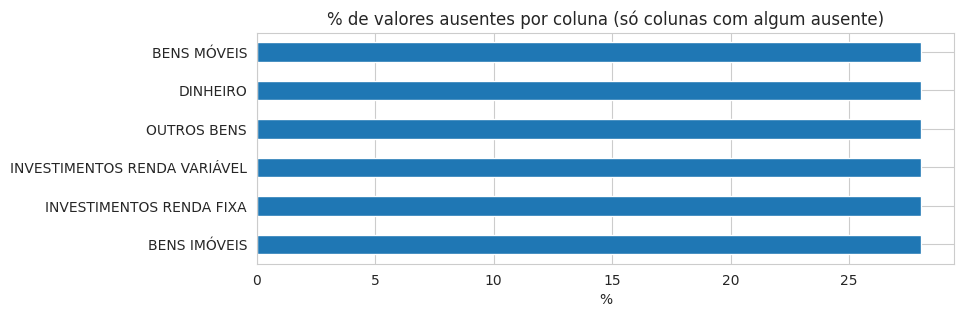

In [202]:
print(f"{df.shape[0]} candidatos x {df.shape[1]} colunas\n")
display(df.dtypes.value_counts().rename('nº de colunas'))

faltantes = (df.isna().mean() * 100).sort_values(ascending=False)
faltantes = faltantes[faltantes > 0]

if len(faltantes) > 0:
    plt.figure(figsize=(9, max(3, len(faltantes) * 0.3)))
    faltantes.plot(kind='barh')
    plt.title('% de valores ausentes por coluna (só colunas com algum ausente)')
    plt.xlabel('%')
    plt.gca().invert_yaxis()
    plt.show()
else:
    print("Nenhuma coluna com valores ausentes.")

## 2) Escolhendo o que explorar

O dataset tem dezenas de colunas — muitas são identificadores administrativos (`SQ_CANDIDATO`, `NR_CPF_CANDIDATO`, `DS_EMAIL`, hashes de geração...) sem valor analítico. As duas listas abaixo reúnem as colunas com conteúdo substantivo — **sintam-se livres para adicionar outras que despertarem curiosidade** (`df.columns` mostra tudo o que está disponível).

In [203]:
display(pd.DataFrame({"Coluna": df.columns}))

,Coluna
0,DT_GERACAO
1,HH_GERACAO
2,ANO_ELEICAO
3,CD_TIPO_ELEICAO
4,NM_TIPO_ELEICAO
5,NR_TURNO
6,CD_ELEICAO
7,DS_ELEICAO
8,DT_ELEICAO
9,TP_ABRANGENCIA


In [204]:
colunas_numericas = [
    'IDADE',
    'Total_Bens',
    'Total_Bens_Log',
    'BENS MÓVEIS',
    'BENS IMÓVEIS',
    'DINHEIRO',
    'INVESTIMENTOS RENDA FIXA',
    'INVESTIMENTOS RENDA VARIÁVEL',
    'OUTROS BENS',
]
colunas_numericas = [c for c in colunas_numericas if c in df.columns]

colunas_categoricas = [
    'DS_GENERO',
    'DS_ESTADO_CIVIL',
    'DS_COR_RACA',
    'DS_GRAU_INSTRUCAO',
    'DS_SITUACAO_CANDIDATURA',
    'DS_SIT_TOT_TURNO',
    'TP_AGREMIACAO',
    'SG_PARTIDO',
    'DS_OCUPACAO',
    'NR_TURNO',
    'SG_UE',
]
colunas_categoricas = [c for c in colunas_categoricas if c in df.columns]

print("Numéricas:")
display(pd.DataFrame({"Coluna": colunas_numericas}))
print("Categóricas:")
display(pd.DataFrame({"Coluna": colunas_categoricas}))

Numéricas:


,Coluna
0,IDADE
1,Total_Bens
2,Total_Bens_Log
3,BENS MÓVEIS
4,BENS IMÓVEIS
5,DINHEIRO
6,INVESTIMENTOS RENDA FIXA
7,INVESTIMENTOS RENDA VARIÁVEL
8,OUTROS BENS


Categóricas:


,Coluna
0,DS_GENERO
1,DS_ESTADO_CIVIL
2,DS_COR_RACA
3,DS_GRAU_INSTRUCAO
4,DS_SITUACAO_CANDIDATURA
5,DS_SIT_TOT_TURNO
6,TP_AGREMIACAO
7,SG_PARTIDO
8,DS_OCUPACAO
9,NR_TURNO


## 3) Variáveis numéricas: distribuição e outliers

In [205]:
display(df[colunas_numericas].describe().T)

,count,mean,std,min,25%,50%,75%,max
IDADE,692.00,48.57,12.51,21.00,40.00,48.00,57.00,86.00
Total_Bens,692.00,"1,951,439.81","8,181,165.69",0.00,0.00,"208,700.00","970,437.10","103,733,556.02"
Total_Bens_Log,692.00,9.41,6.09,0.00,0.00,12.25,13.79,18.46
BENS MÓVEIS,498.00,"347,124.70","4,301,330.16",0.00,0.00,"38,750.00","139,125.00","95,000,000.00"
BENS IMÓVEIS,498.00,"804,424.55","2,368,881.75",0.00,0.00,"235,171.32","800,000.00","35,528,057.35"
DINHEIRO,498.00,"57,257.95","370,337.37",0.00,0.00,0.00,"1,348.66","5,275,341.98"
INVESTIMENTOS RENDA FIXA,498.00,"181,341.63","1,896,525.00",0.00,0.00,0.00,0.00,"33,057,038.00"
INVESTIMENTOS RENDA VARIÁVEL,498.00,"351,289.00","3,193,887.07",0.00,0.00,0.00,0.00,"65,018,864.00"
OUTROS BENS,498.00,"970,201.42","5,062,359.76",0.00,0.00,0.00,"120,000.00","73,979,450.00"


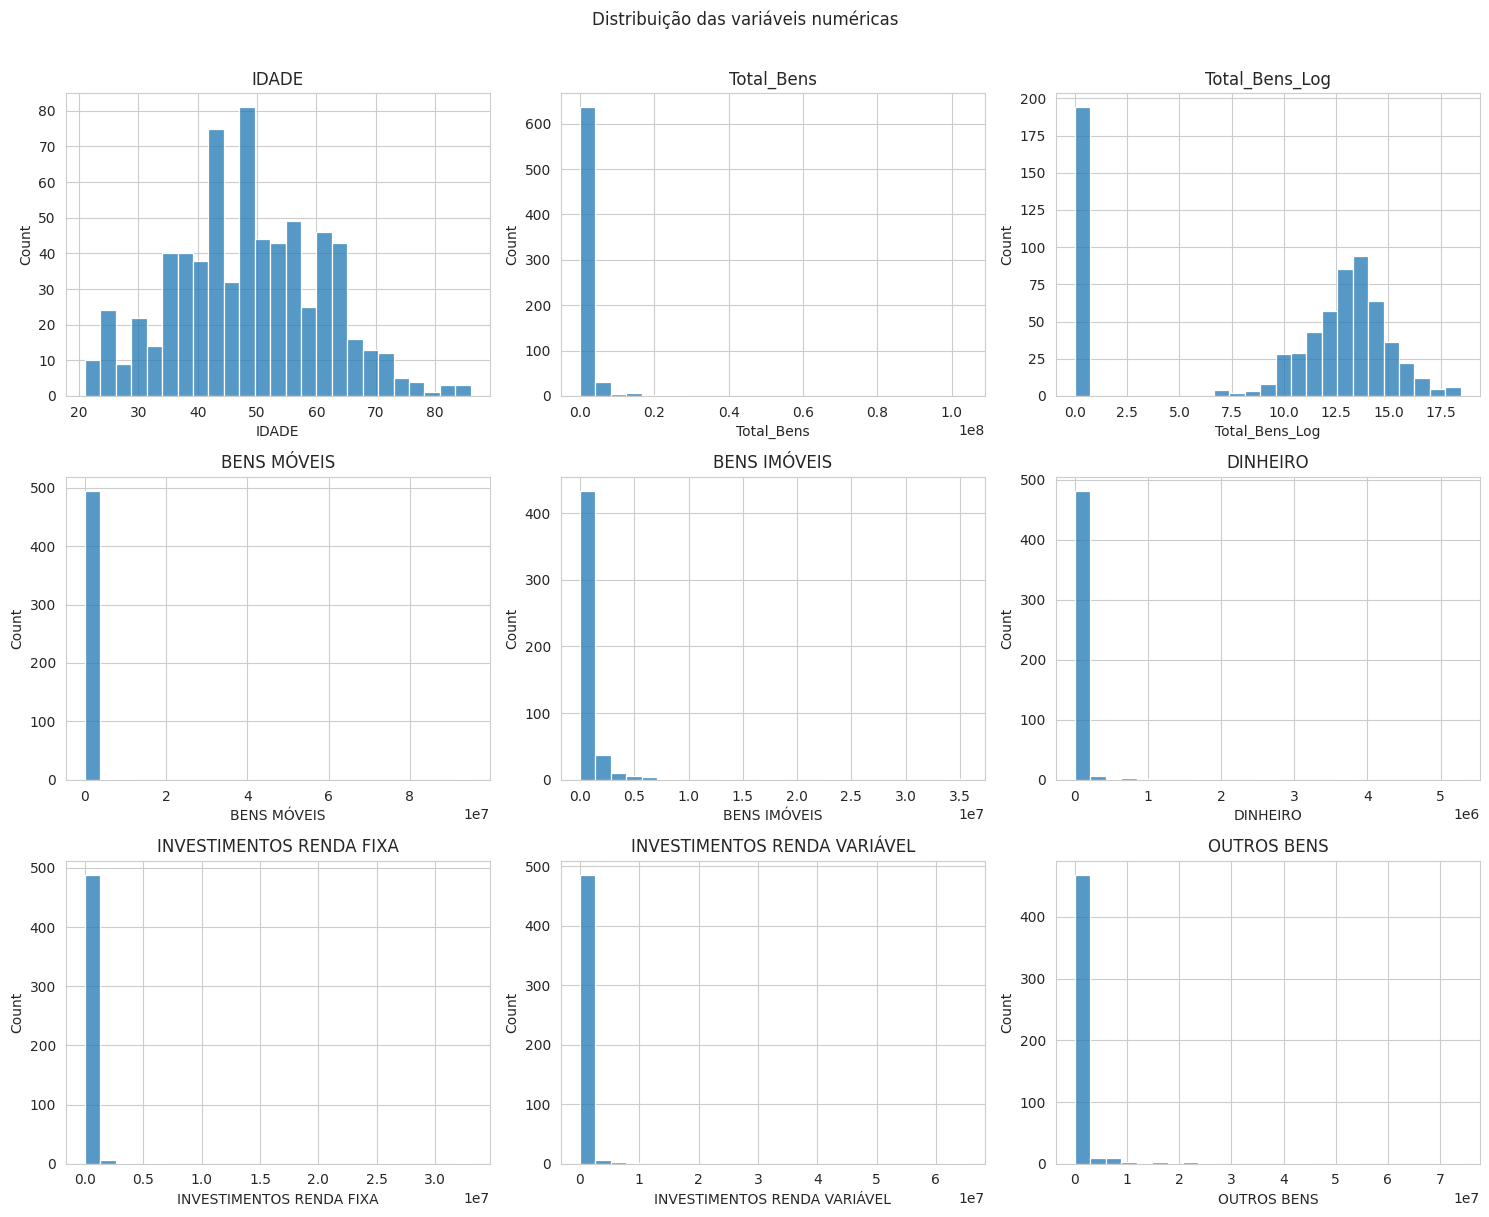

In [206]:
n = len(colunas_numericas)
ncols = 3
nrows = -(-n // ncols)  # arredonda pra cima

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(colunas_numericas):
    sns.histplot(df[col], bins=25, ax=axes[i])
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Distribuição das variáveis numéricas', y=1.01)
plt.tight_layout()
plt.show()

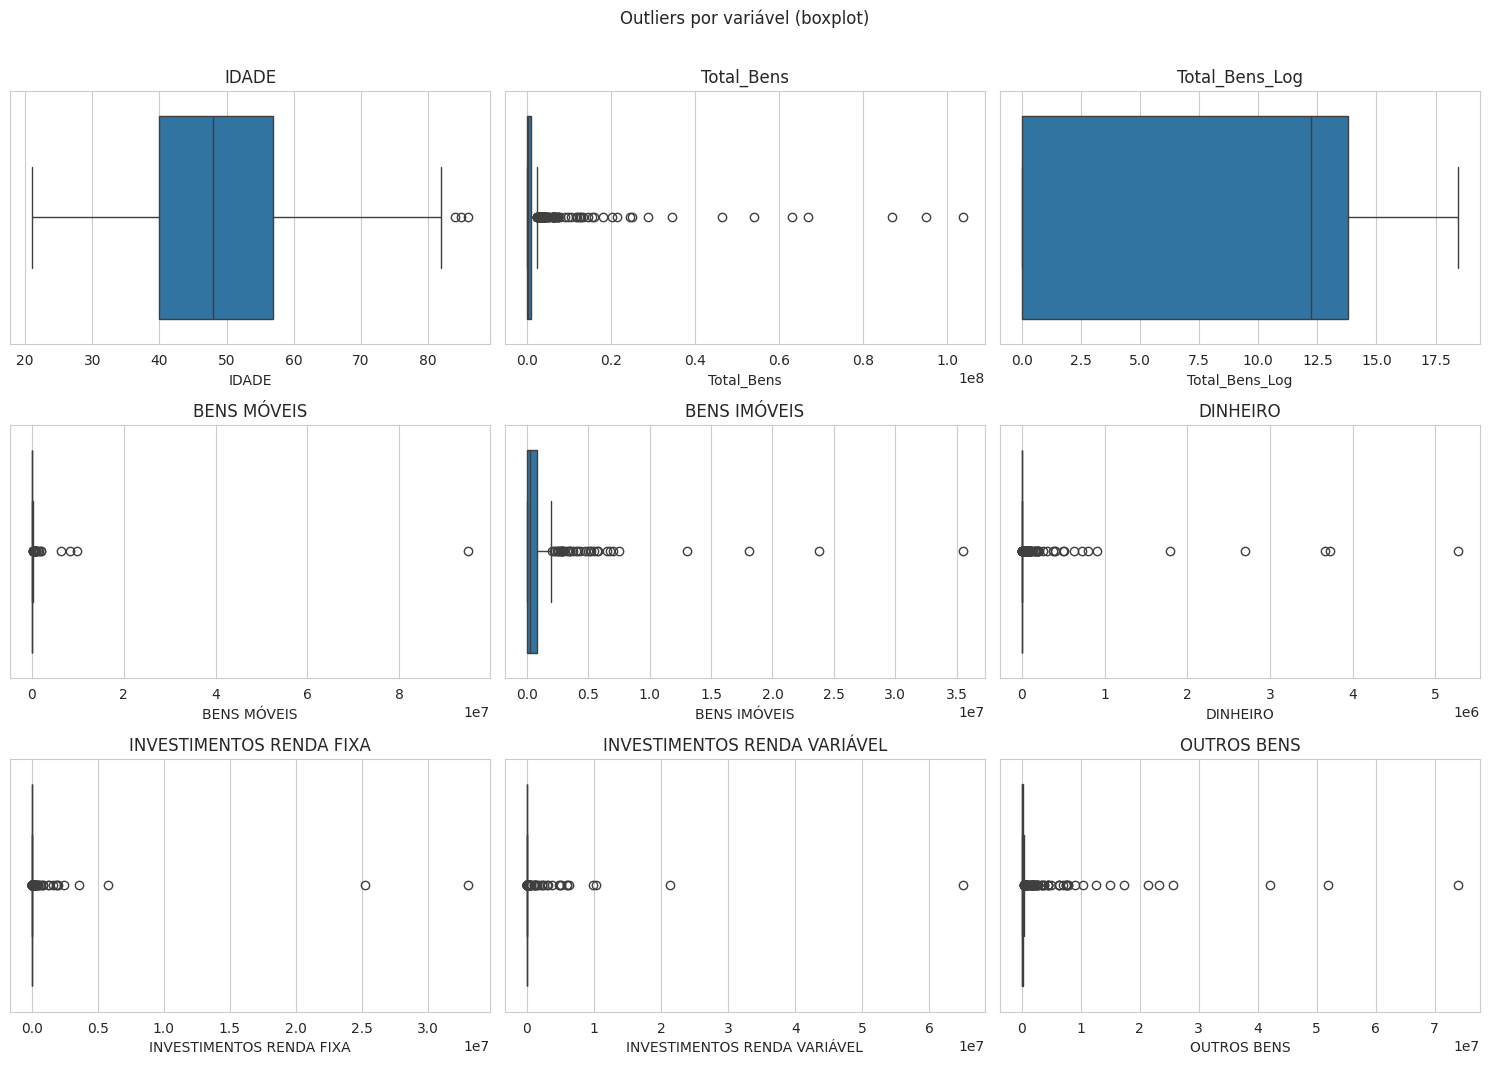

In [207]:
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.5 * nrows))
axes = axes.flatten()

for i, col in enumerate(colunas_numericas):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Outliers por variável (boxplot)', y=1.01)
plt.tight_layout()
plt.show()

### 3.1) Quantificando os outliers (regra do IQR)

O boxplot mostra visualmente; esta tabela quantifica: quantos candidatos ficam fora do intervalo `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]` em cada variável.

In [208]:
linhas = []
for col in colunas_numericas:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lim_inf, lim_sup = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    linhas.append({
        'variavel': col, 'limite_inferior': lim_inf, 'limite_superior': lim_sup,
        'qtd_outliers': n_outliers, 'pct_outliers': round(100 * n_outliers / len(df), 1),
    })

pd.DataFrame(linhas).sort_values('pct_outliers', ascending=False)

,variavel,limite_inferior,limite_superior,qtd_outliers,pct_outliers
6,INVESTIMENTOS RENDA FIXA,0.00,0.00,122,17.60
5,DINHEIRO,"-2,022.99","3,371.64",116,16.80
7,INVESTIMENTOS RENDA VARIÁVEL,0.00,0.00,104,15.00
1,Total_Bens,"-1,455,655.66","2,426,092.76",87,12.60
8,OUTROS BENS,"-180,000.00","300,000.00",84,12.10
3,BENS MÓVEIS,"-208,687.50","347,812.50",41,5.90
4,BENS IMÓVEIS,"-1,200,000.00","2,000,000.00",37,5.30
0,IDADE,14.50,82.50,3,0.40
2,Total_Bens_Log,-20.68,34.46,0,0.00


## 4) Variáveis categóricas: contagens e proporções

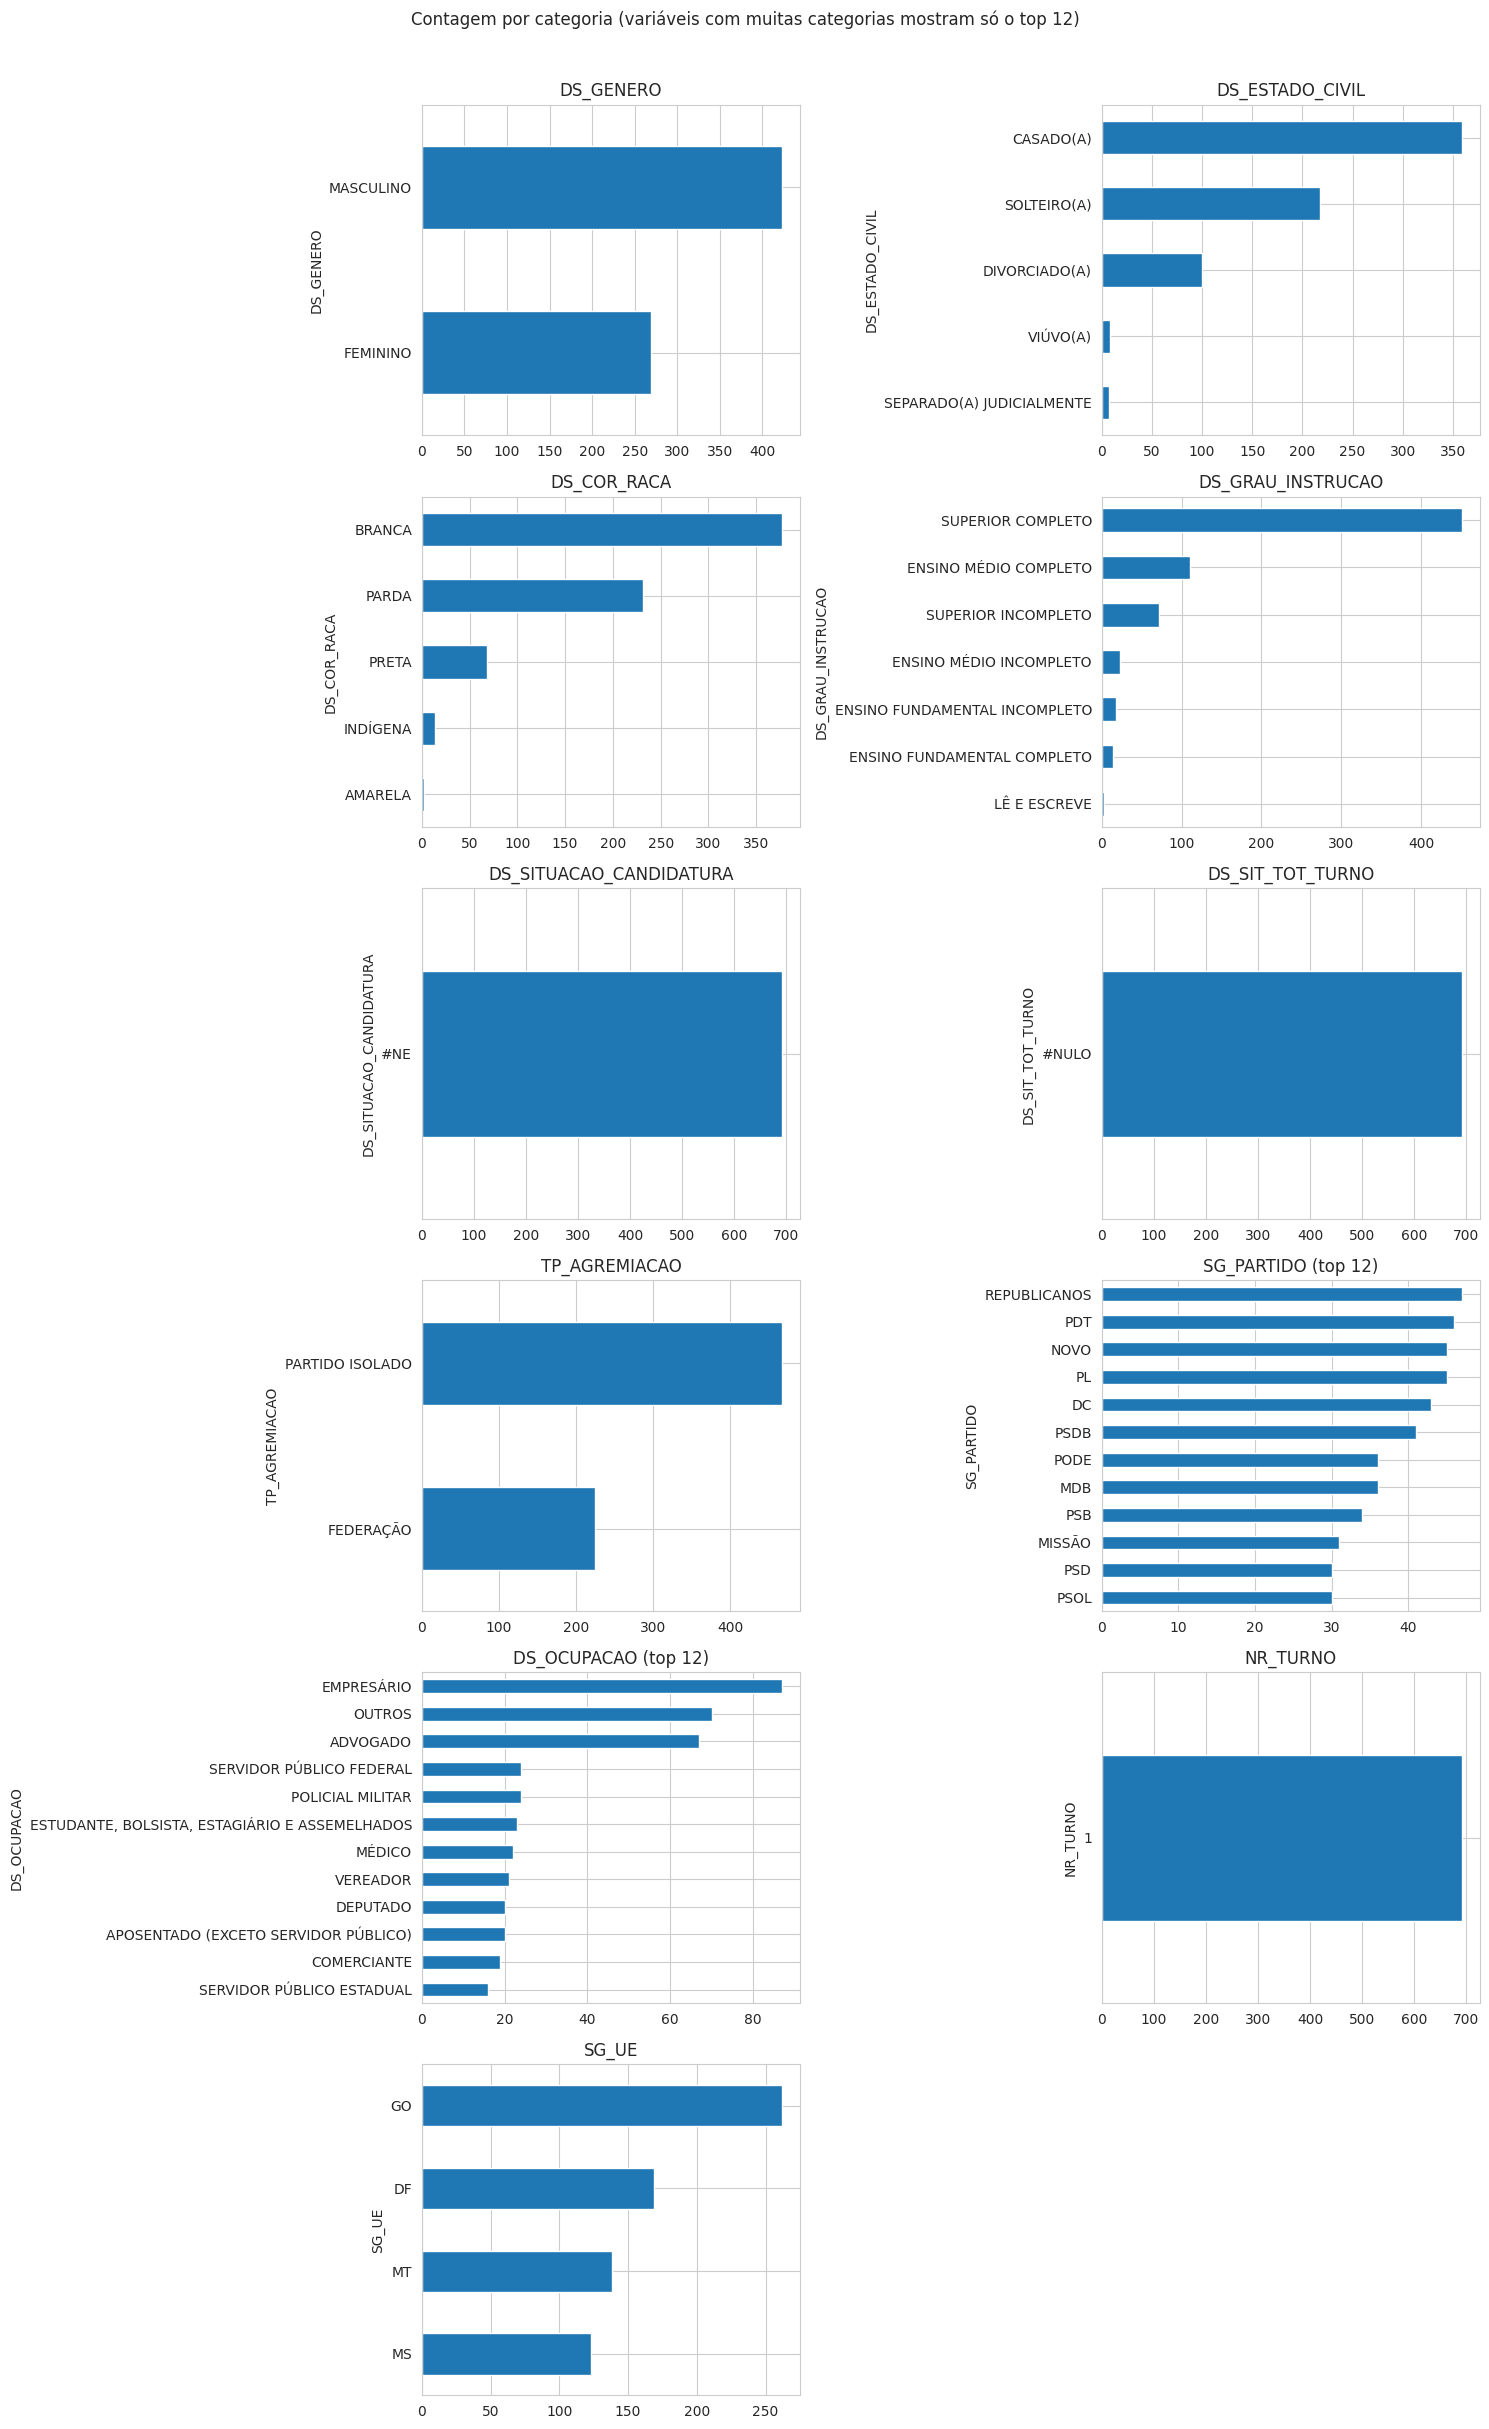

In [209]:
def plot_categorica(ax, coluna, top_n=12):
    contagem = df[coluna].value_counts().head(top_n)
    contagem.plot(kind='barh', ax=ax)
    ax.set_title(coluna + (f' (top {top_n})' if df[coluna].nunique() > top_n else ''))
    ax.invert_yaxis()

n = len(colunas_categoricas)
ncols = 2
nrows = -(-n // ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(colunas_categoricas):
    plot_categorica(axes[i], col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Contagem por categoria (variáveis com muitas categorias mostram só o top 12)', y=1.01)
plt.tight_layout()
plt.show()

In [210]:
for col in colunas_categoricas:
    print(f"--- {col} ({df[col].nunique()} categorias) ---")
    print((df[col].value_counts(normalize=True).head(8) * 100).round(1).astype(str) + '%')
    print()

--- DS_GENERO (2 categorias) ---
DS_GENERO
MASCULINO    61.1%
FEMININO     38.9%
Name: proportion, dtype: object

--- DS_ESTADO_CIVIL (5 categorias) ---
DS_ESTADO_CIVIL
CASADO(A)                    51.9%
SOLTEIRO(A)                  31.5%
DIVORCIADO(A)                14.5%
VIÚVO(A)                      1.2%
SEPARADO(A) JUDICIALMENTE     1.0%
Name: proportion, dtype: object

--- DS_COR_RACA (5 categorias) ---
DS_COR_RACA
BRANCA      54.5%
PARDA       33.4%
PRETA        9.8%
INDÍGENA     2.0%
AMARELA      0.3%
Name: proportion, dtype: object

--- DS_GRAU_INSTRUCAO (7 categorias) ---
DS_GRAU_INSTRUCAO
SUPERIOR COMPLETO                65.2%
ENSINO MÉDIO COMPLETO            16.0%
SUPERIOR INCOMPLETO              10.4%
ENSINO MÉDIO INCOMPLETO           3.3%
ENSINO FUNDAMENTAL INCOMPLETO     2.6%
ENSINO FUNDAMENTAL COMPLETO       2.0%
LÊ E ESCREVE                      0.4%
Name: proportion, dtype: object

--- DS_SITUACAO_CANDIDATURA (1 categorias) ---
DS_SITUACAO_CANDIDATURA
#NE    100.0%
Nam

## 5) Dispersão entre variáveis numéricas

Correlação e gráficos de dispersão par a par — sem nenhuma variável de destaque, só pra ver como as variáveis se relacionam (ou não).

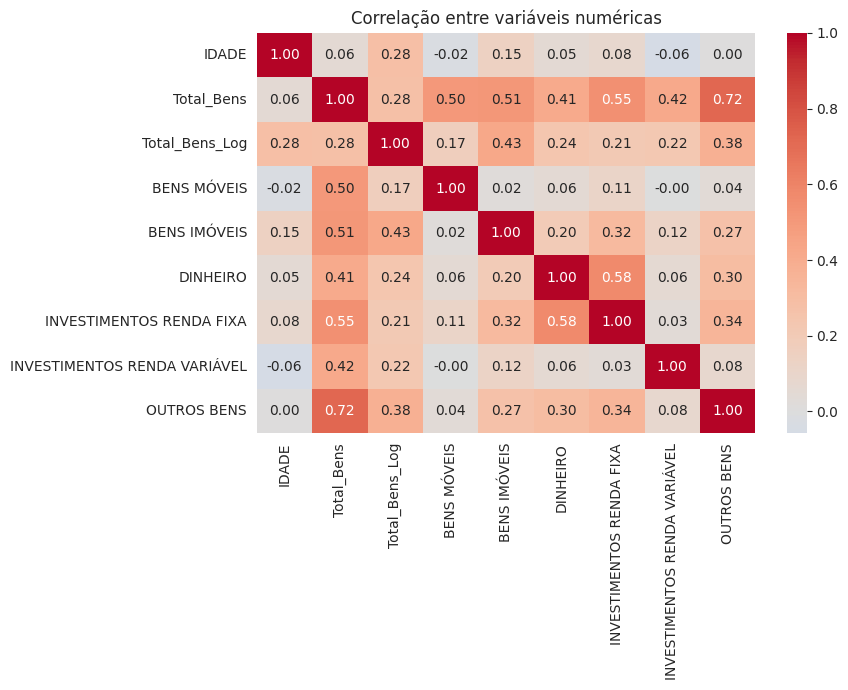

In [211]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[colunas_numericas].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlação entre variáveis numéricas')
plt.tight_layout()
plt.show()

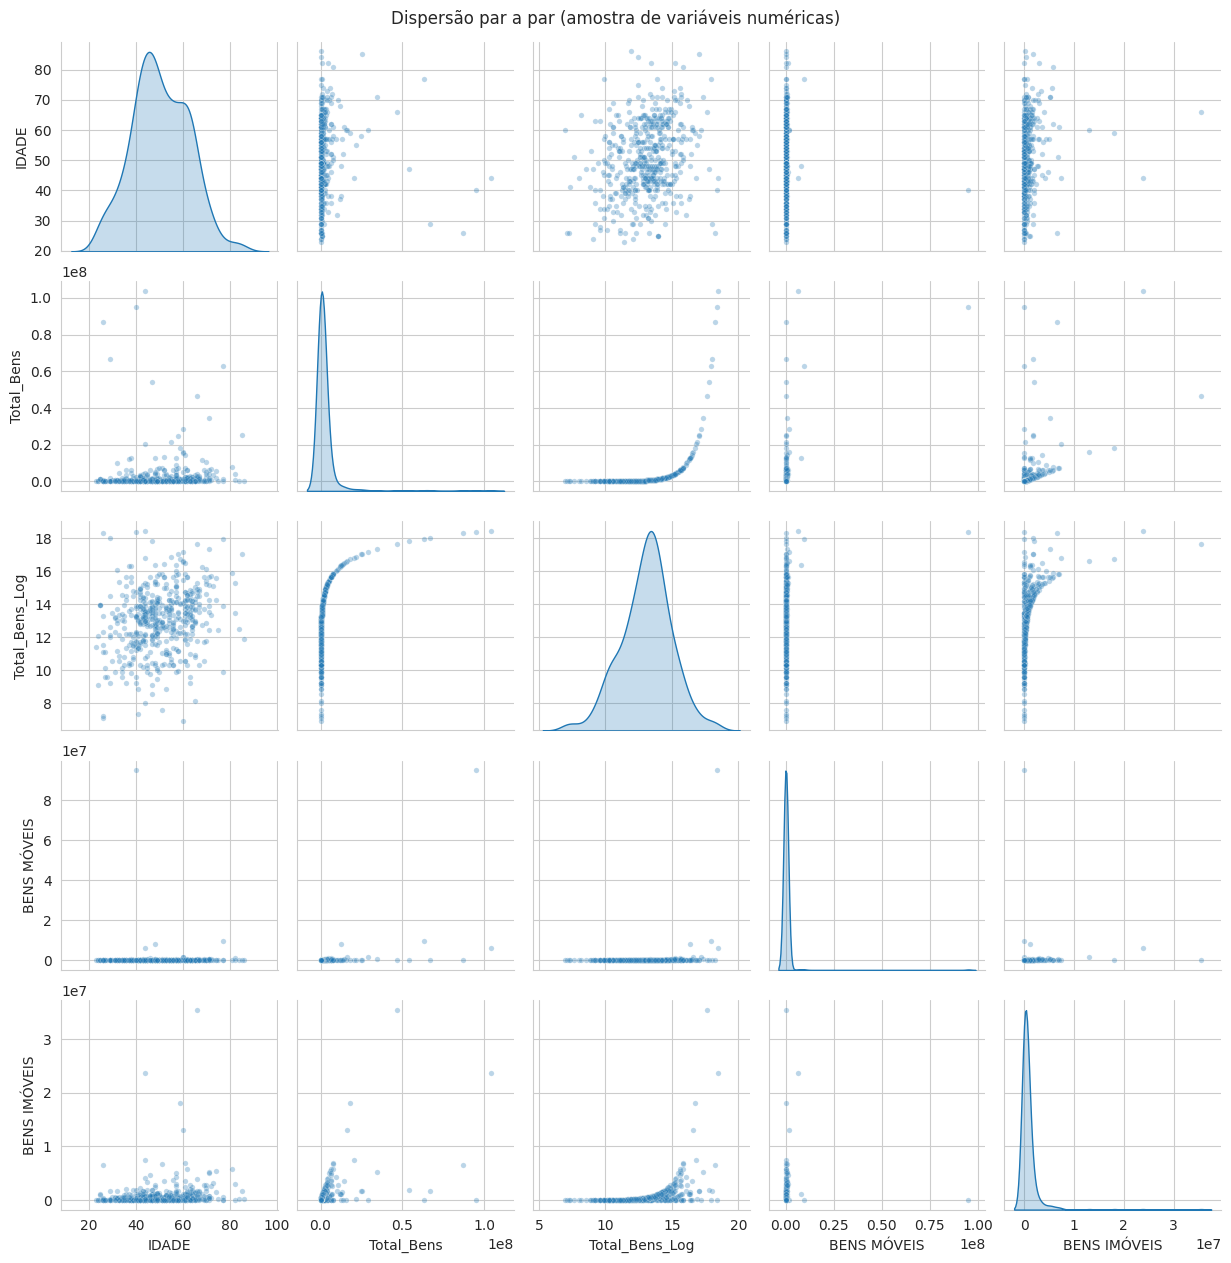

In [212]:
# Pairplot com um subconjunto (pairplot com muitas variáveis fica pesado/ilegível)
subset = colunas_numericas[:5]
sns.pairplot(df[subset].dropna(), diag_kind='kde', plot_kws={'alpha': 0.3, 's': 15})
plt.suptitle('Dispersão par a par (amostra de variáveis numéricas)', y=1.01)
plt.show()

### 5.1) Um exemplo de dispersão colorida

Só um exemplo de como cruzar uma variável numérica com outra numérica *e* uma categórica ao mesmo tempo — troquem `x`, `y` e `hue` livremente para explorar outras combinações.

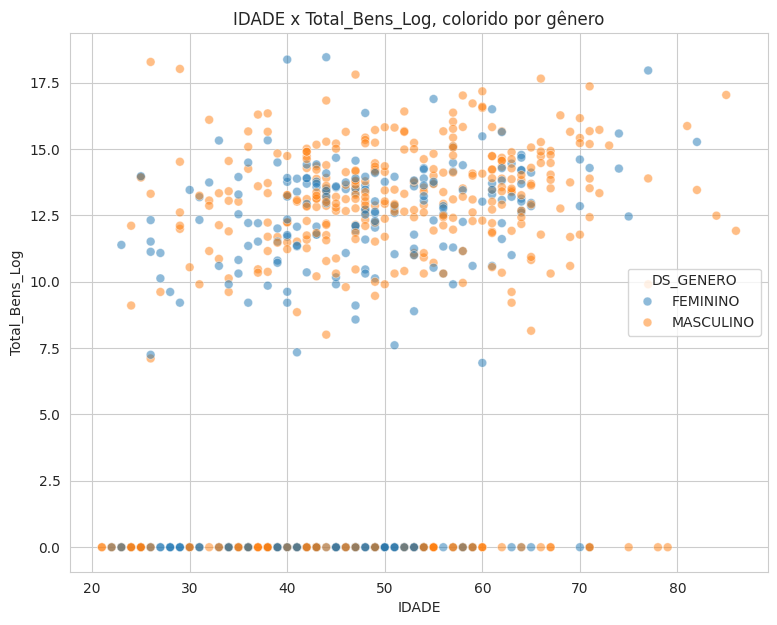

In [213]:
plt.figure(figsize=(9, 7))
sns.scatterplot(data=df, x='IDADE', y='Total_Bens_Log', hue='DS_GENERO', alpha=0.5, s=40)
plt.title('IDADE x Total_Bens_Log, colorido por gênero')
plt.show()

## 6) Proporções entre grupos

Alguns exemplos de cruzamentos categóricos — não são os únicos possíveis, só uma amostra do tipo de pergunta que dá pra fazer.

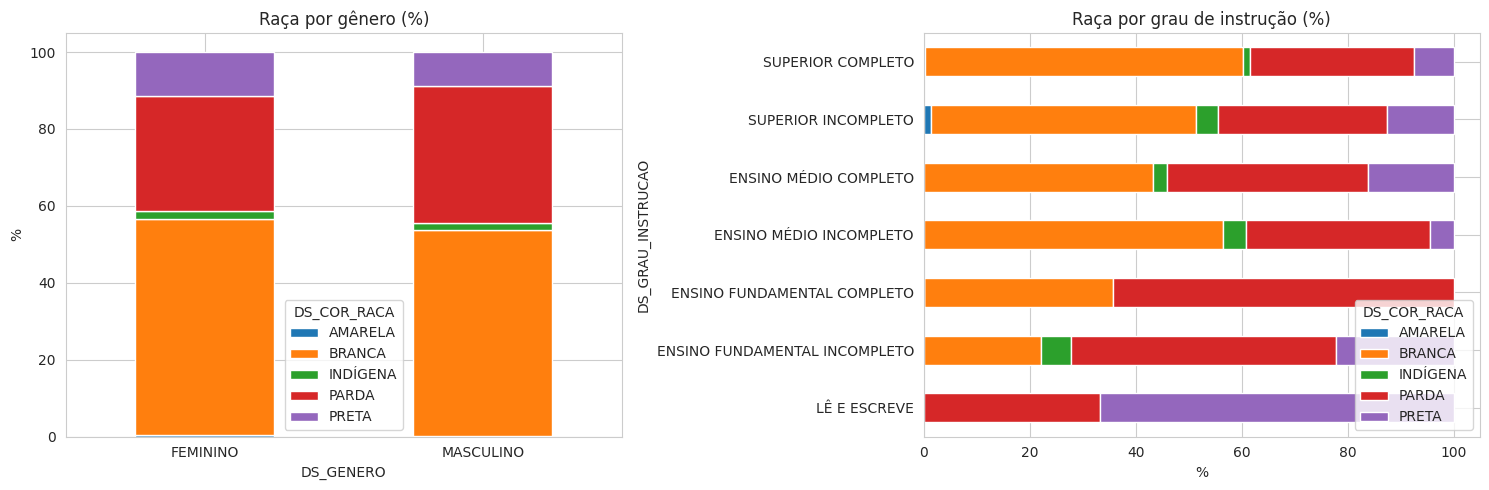

In [214]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

pd.crosstab(df['DS_GENERO'], df['DS_COR_RACA'], normalize='index').mul(100).plot(
    kind='bar', stacked=True, ax=axes[0]
)
axes[0].set_title('Raça por gênero (%)')
axes[0].set_ylabel('%')
axes[0].tick_params(axis='x', rotation=0)

ordem_instrucao = df[['CD_GRAU_INSTRUCAO', 'DS_GRAU_INSTRUCAO']].drop_duplicates().sort_values('CD_GRAU_INSTRUCAO')['DS_GRAU_INSTRUCAO']
pd.crosstab(df['DS_GRAU_INSTRUCAO'], df['DS_COR_RACA'], normalize='index').loc[ordem_instrucao].mul(100).plot(
    kind='barh', stacked=True, ax=axes[1]
)
axes[1].set_title('Raça por grau de instrução (%)')
axes[1].set_xlabel('%')

plt.tight_layout()
plt.show()

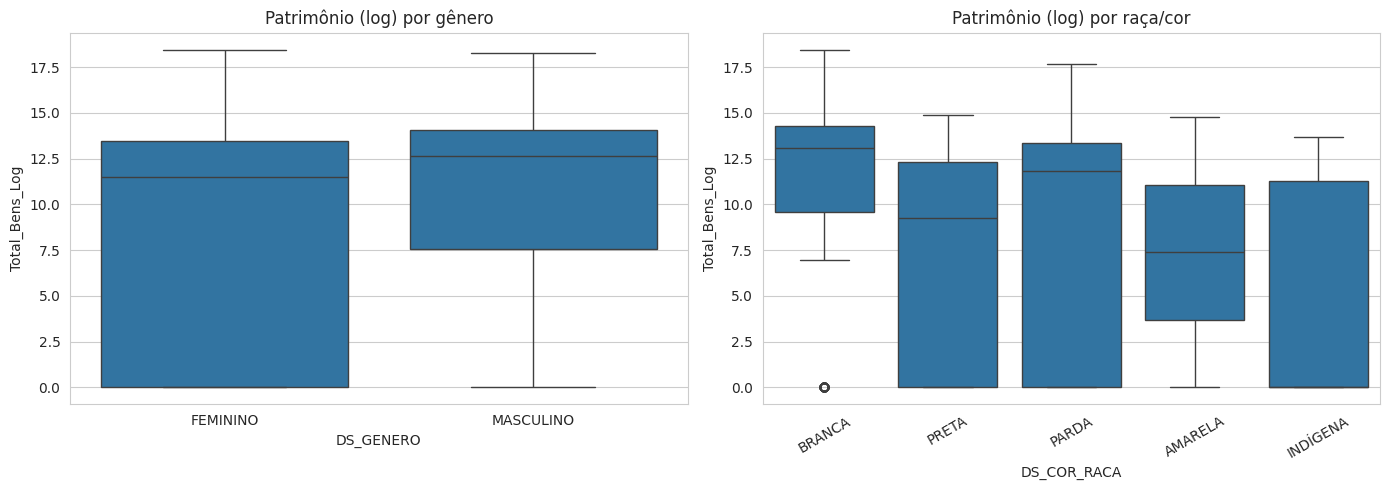

In [215]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='DS_GENERO', y='Total_Bens_Log', ax=axes[0])
axes[0].set_title('Patrimônio (log) por gênero')

sns.boxplot(data=df, x='DS_COR_RACA', y='Total_Bens_Log', ax=axes[1])
axes[1].set_title('Patrimônio (log) por raça/cor')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

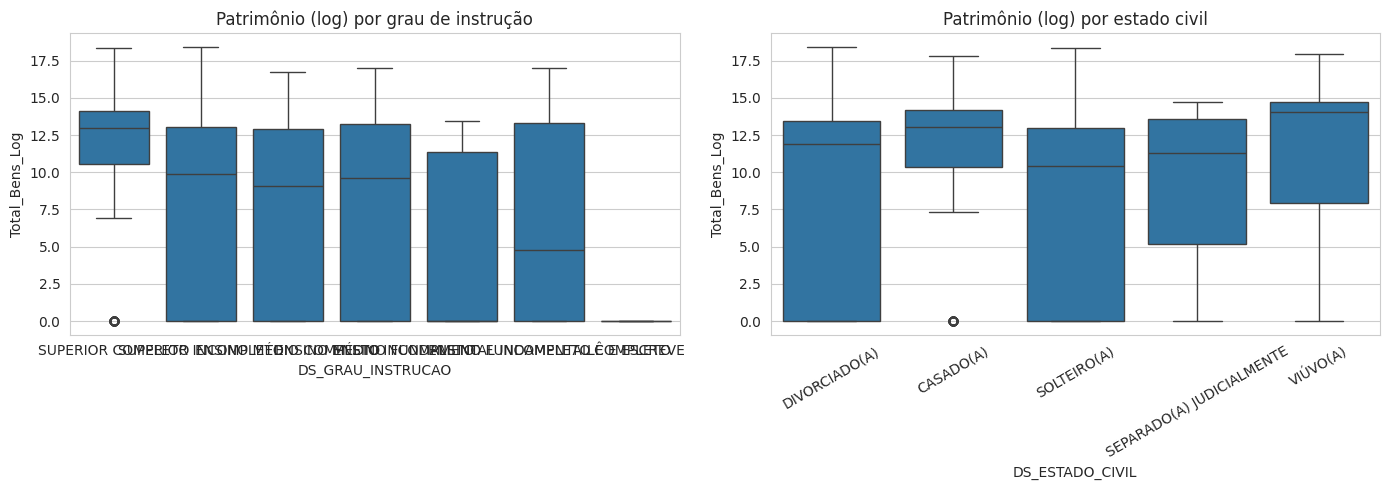

In [216]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='DS_GRAU_INSTRUCAO', y='Total_Bens_Log', ax=axes[0])
axes[0].set_title('Patrimônio (log) por grau de instrução')

sns.boxplot(data=df, x='DS_ESTADO_CIVIL', y='Total_Bens_Log', ax=axes[1])
axes[1].set_title('Patrimônio (log) por estado civil')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

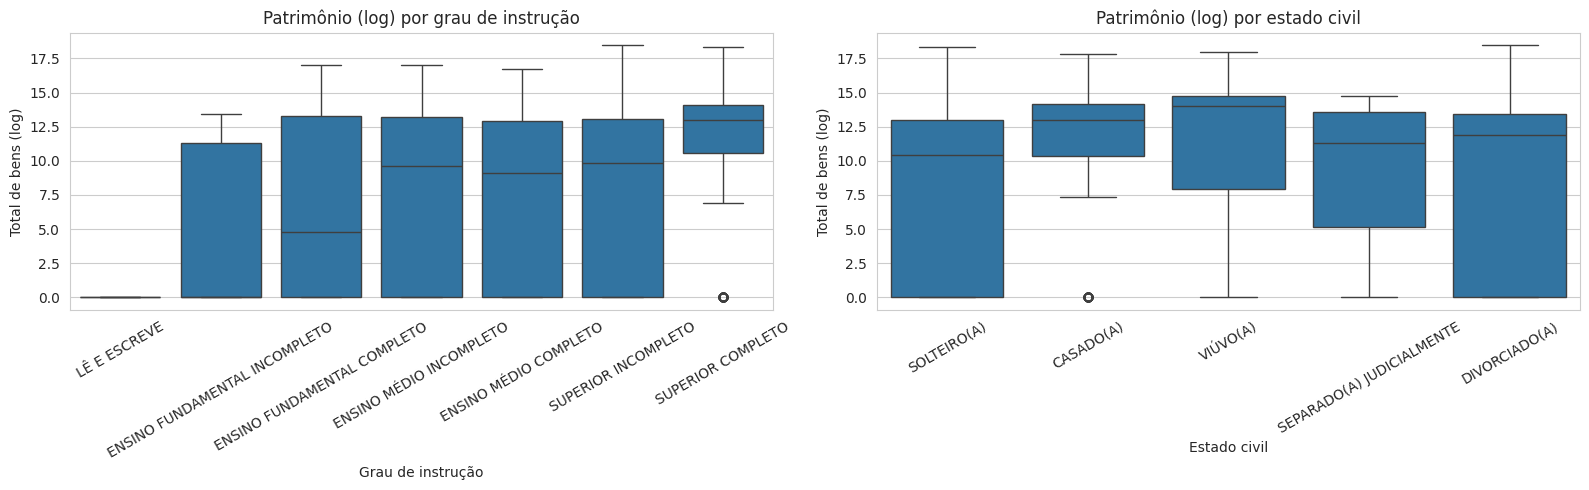

In [217]:
# Ordem do grau de instrução pelo respectivo código
ordem_instrucao = (
    df[['CD_GRAU_INSTRUCAO', 'DS_GRAU_INSTRUCAO']]
    .drop_duplicates()
    .sort_values('CD_GRAU_INSTRUCAO')
    ['DS_GRAU_INSTRUCAO']
    .tolist()
)

# Ordem do estado civil pelo respectivo código
ordem_estado_civil = (
    df[['CD_ESTADO_CIVIL', 'DS_ESTADO_CIVIL']]
    .drop_duplicates()
    .sort_values('CD_ESTADO_CIVIL')
    ['DS_ESTADO_CIVIL']
    .tolist()
)


# Cria os dois gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(16, 5))


# Grau de instrução
sns.boxplot(
    data=df,
    x='DS_GRAU_INSTRUCAO',
    y='Total_Bens_Log',
    order=ordem_instrucao,
    ax=axes[0]
)

axes[0].set_title('Patrimônio (log) por grau de instrução')
axes[0].set_xlabel('Grau de instrução')
axes[0].set_ylabel('Total de bens (log)')
axes[0].tick_params(axis='x', rotation=30)


# Estado civil
sns.boxplot(
    data=df,
    x='DS_ESTADO_CIVIL',
    y='Total_Bens_Log',
    order=ordem_estado_civil,
    ax=axes[1]
)

axes[1].set_title('Patrimônio (log) por estado civil')
axes[1].set_xlabel('Estado civil')
axes[1].set_ylabel('Total de bens (log)')
axes[1].tick_params(axis='x', rotation=30)


plt.tight_layout()
plt.show()

## 7) Comparação entre UFs

Como o recorte reúne quatro UFs, esta seção compara a quantidade de candidatos e o patrimônio mediano entre DF, GO, MS e MT. Ela só é omitida quando `UF` contém uma única sigla.

,qtd_candidatos,idade_media,patrimonio_mediano,pct_feminino
SG_UF,,,,
GO,262,48.00,"236,123.00",40.80
DF,169,49.40,"204,623.30",38.50
MT,138,47.80,"290,000.00",37.70
MS,123,49.40,"107,613.00",36.60


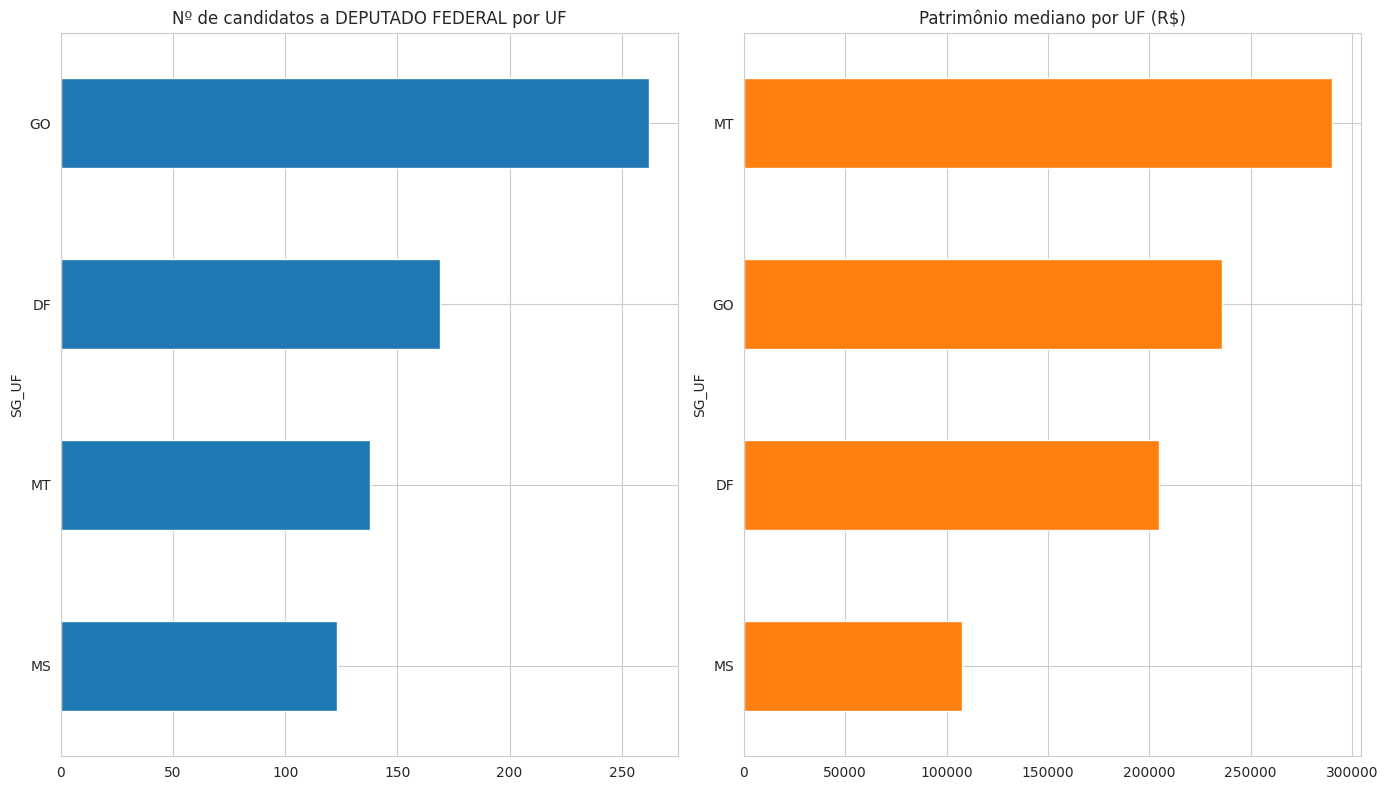

In [218]:
if UF is None or not isinstance(UF, str):
    resumo_uf = df.groupby('SG_UF').agg(
        qtd_candidatos=('SQ_CANDIDATO', 'count'),
        idade_media=('IDADE', 'mean'),
        patrimonio_mediano=('Total_Bens', 'median'),
        pct_feminino=('DS_GENERO', lambda x: (x == 'FEMININO').mean() * 100),
    ).round(1).sort_values('qtd_candidatos', ascending=False)

    display(resumo_uf)

    fig, axes = plt.subplots(1, 2, figsize=(14, 8))
    resumo_uf['qtd_candidatos'].sort_values().plot(kind='barh', ax=axes[0])
    axes[0].set_title(f'Nº de candidatos a {CARGO} por UF')

    resumo_uf['patrimonio_mediano'].sort_values().plot(kind='barh', ax=axes[1], color='tab:orange')
    axes[1].set_title('Patrimônio mediano por UF (R$)')

    plt.tight_layout()
    plt.show()
else:
    print(f"UF = {UF!r} — comparação não se aplica a um recorte de UF única.")

## 8) Visão geral das variáveis analisadas

Para que o perfil da população esteja claro antes da modelagem, esta seção apresenta **idade**, **tempo de estudo**, **total de bens declarados** e **total de despesas declaradas de campanha**. Essas são as **quatro variáveis que serão usadas na clusterização com Bisecting K-Means**, conforme as regras do trabalho.

O tempo de estudo é uma equivalência aproximada, em anos, construída a partir do grau de instrução informado ao TSE. Para despesas, usamos `VR_DESPESA_CONTRATADA`: compromissos já declarados pela campanha no snapshot disponível, ainda que nem todos tenham sido pagos. Cada candidato pode aparecer em várias linhas; por isso os valores são somados por `SQ_CANDIDATO`. Candidato sem registro no arquivo recebe zero, pois não há despesa declarada nesse snapshot.

In [219]:
from pathlib import Path

ANOS_ESTUDO_POR_GRAU = {
    'ANALFABETO': 0,
    'LÊ E ESCREVE': 1,
    'ENSINO FUNDAMENTAL INCOMPLETO': 4,
    'ENSINO FUNDAMENTAL COMPLETO': 8,
    'ENSINO MÉDIO INCOMPLETO': 9,
    'ENSINO MÉDIO COMPLETO': 11,
    'SUPERIOR INCOMPLETO': 13,
    'SUPERIOR COMPLETO': 16,
}
df['ANOS_ESTUDO'] = df['DS_GRAU_INSTRUCAO'].map(ANOS_ESTUDO_POR_GRAU)

ufs_despesas = [UF] if isinstance(UF, str) else UF
if ufs_despesas is None:
    arquivos_despesas = sorted(Path('dados').glob(f'despesas_contratadas_candidatos_{ANO_ELEICAO}_*.csv'))
else:
    arquivos_despesas = [
        Path(f'/dados/despesas_contratadas_candidatos_{ANO_ELEICAO}_{uf}.csv')
        for uf in ufs_despesas
    ]

arquivos_ausentes = [str(p) for p in arquivos_despesas if not p.exists()]
if arquivos_ausentes:
    raise FileNotFoundError('Arquivos de despesas ausentes: ' + ', '.join(arquivos_ausentes))
if not arquivos_despesas:
    raise FileNotFoundError('Nenhum arquivo de despesas foi encontrado em dados/.')

colunas_despesa = ['DT_GERACAO', 'DS_CARGO', 'SQ_CANDIDATO', 'VR_DESPESA_CONTRATADA']
partes_despesas = []
for caminho in arquivos_despesas:
    parte = pd.read_csv(
        caminho, sep=';', encoding='latin-1', usecols=colunas_despesa,
        dtype={'SQ_CANDIDATO': 'int64'}
    )
    parte = parte[parte['DS_CARGO'].str.upper() == CARGO.upper()].copy()
    partes_despesas.append(parte)

df_despesas = pd.concat(partes_despesas, ignore_index=True)
datas_despesas = sorted(df_despesas['DT_GERACAO'].dropna().unique())
df_despesas['VR_DESPESA_CONTRATADA'] = pd.to_numeric(
    df_despesas['VR_DESPESA_CONTRATADA'].astype(str)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False),
    errors='coerce'
)

valores_invalidos = df_despesas['VR_DESPESA_CONTRATADA'].isna().sum()
gasto_por_candidato = (
    df_despesas.groupby('SQ_CANDIDATO', as_index=False)['VR_DESPESA_CONTRATADA']
    .sum(min_count=1)
    .rename(columns={'VR_DESPESA_CONTRATADA': 'Total_Gasto_Campanha'})
)

df = df.drop(columns=['Total_Gasto_Campanha', 'Total_Gasto_Campanha_Log'], errors='ignore')
df = df.merge(gasto_por_candidato, on='SQ_CANDIDATO', how='left')
sem_registro_despesa = df['Total_Gasto_Campanha'].isna().sum()
df['Total_Gasto_Campanha'] = df['Total_Gasto_Campanha'].fillna(0)
df['Total_Gasto_Campanha_Log'] = np.log1p(df['Total_Gasto_Campanha'])

print(f'Snapshot dos candidatos: {df["DT_GERACAO"].iloc[0]}.')
print(f'Snapshot das despesas: {", ".join(datas_despesas)}.')
print(f'{len(df_despesas):,} lançamentos de despesas contratadas para {CARGO}.')
print(f'{valores_invalidos:,} lançamento(s) com valor inválido, ignorado(s) na soma.')
print(f'{sem_registro_despesa:,} de {len(df):,} candidatos sem registro de despesa; tratados como R$ 0,00.')
print(f'Total de despesas declaradas na população: R$ {df["Total_Gasto_Campanha"].sum():,.2f}')

Snapshot dos candidatos: 08/09/2026.
Snapshot das despesas: 22/09/2026.
45,299 lançamentos de despesas contratadas para DEPUTADO FEDERAL.
0 lançamento(s) com valor inválido, ignorado(s) na soma.
30 de 692 candidatos sem registro de despesa; tratados como R$ 0,00.
Total de despesas declaradas na população: R$ 164,213,492.74


### 8.1) Estatísticas descritivas

As estatísticas abaixo permanecem na escala original. Além dos quantis usuais, mostramos a quantidade de observações válidas e a proporção de zeros, especialmente importante para patrimônio e despesas.

In [220]:
variaveis_clusterizacao = {
    'IDADE': 'Idade (anos)',
    'ANOS_ESTUDO': 'Tempo de estudo equivalente (anos)',
    'Total_Bens': 'Total de bens declarados (R$)',
    'Total_Gasto_Campanha': 'Total de despesas declaradas (R$)',
}

resumo_clusterizacao = (
    df[list(variaveis_clusterizacao)].describe(percentiles=[0.25, 0.5, 0.75]).T
    .rename(index=variaveis_clusterizacao)
    .rename(columns={
        'count': 'n', 'mean': 'média', 'std': 'desvio padrão',
        'min': 'mínimo', '25%': 'Q1', '50%': 'mediana',
        '75%': 'Q3', 'max': 'máximo'
    })
)
resumo_clusterizacao['ausentes (%)'] = [
    df[coluna].isna().mean() * 100 for coluna in variaveis_clusterizacao
]
resumo_clusterizacao['zeros (%)'] = [
    df[coluna].eq(0).mean() * 100 for coluna in variaveis_clusterizacao
]
display(resumo_clusterizacao.round(2))

,n,média,desvio padrão,mínimo,Q1,mediana,Q3,máximo,ausentes (%),zeros (%)
Idade (anos),692.00,48.57,12.51,21.00,40.00,48.00,57.00,86.00,0.00,0.00
Tempo de estudo equivalente (anos),692.00,14.11,3.01,1.00,13.00,16.00,16.00,16.00,0.00,0.00
Total de bens declarados (R$),692.00,"1,951,439.81","8,181,165.69",0.00,0.00,"208,700.00","970,437.10","103,733,556.02",0.00,28.03
Total de despesas declaradas (R$),692.00,"237,302.74","452,885.04",0.00,"1,000.75","35,765.28","220,078.96","2,887,585.51",0.00,22.54


### 8.2) Distribuições

Idade e tempo de estudo aparecem na escala original. Bens e despesas são muito assimétricos; por isso seus histogramas usam `log1p`, que mantém os zeros e reduz a influência visual dos valores extremos. Os totais em reais continuam disponíveis na tabela acima.

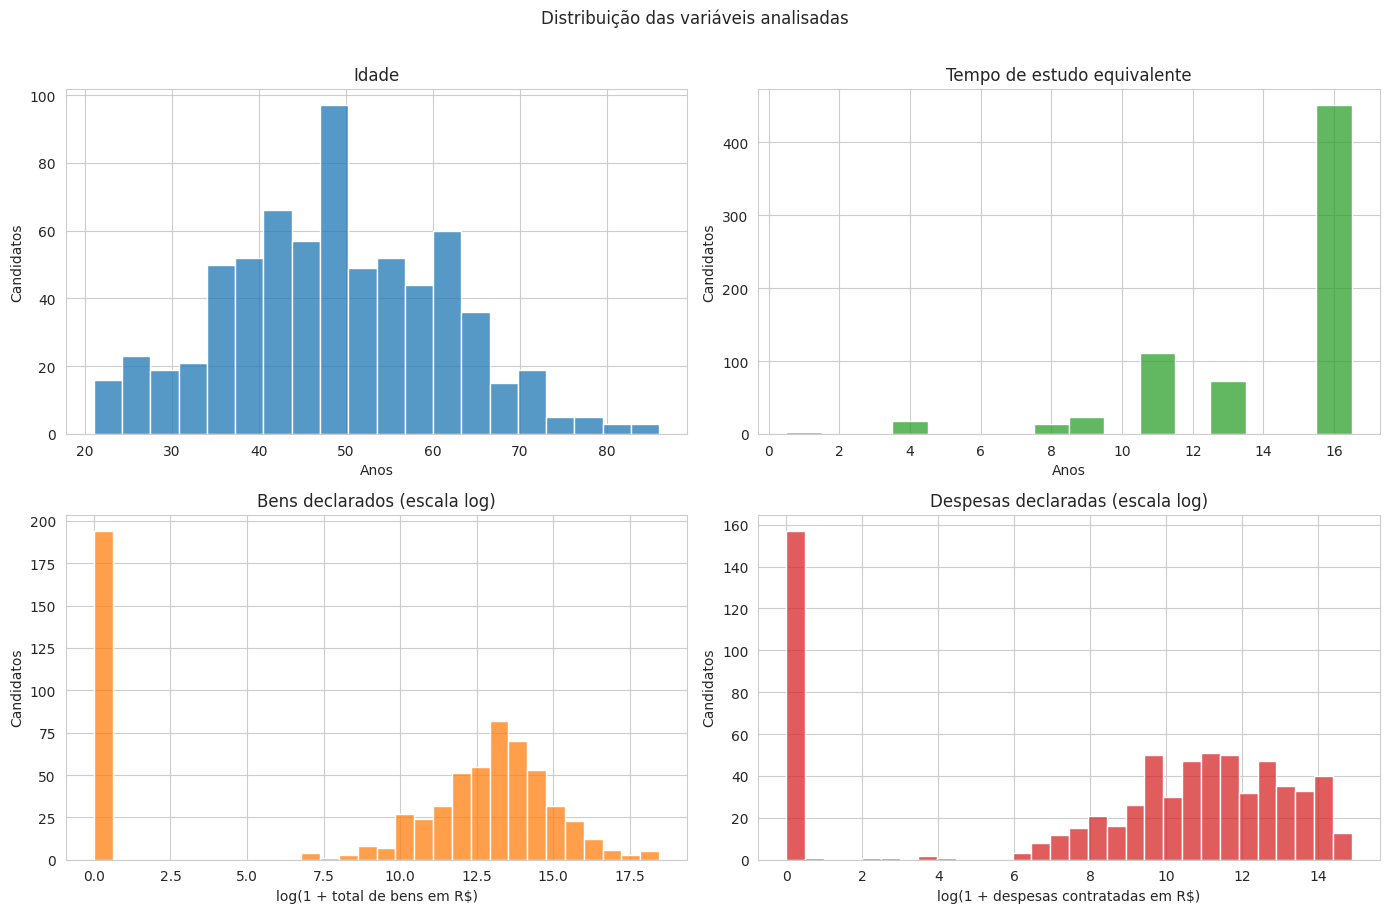

In [221]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(df['IDADE'].dropna(), bins=20, ax=axes[0, 0], color='tab:blue')
axes[0, 0].set(title='Idade', xlabel='Anos', ylabel='Candidatos')

anos_estudo_validos = df['ANOS_ESTUDO'].dropna()
bins_estudo = np.arange(anos_estudo_validos.min() - 0.5, anos_estudo_validos.max() + 1.5, 1)
sns.histplot(anos_estudo_validos, bins=bins_estudo, ax=axes[0, 1], color='tab:green')
axes[0, 1].set(title='Tempo de estudo equivalente', xlabel='Anos', ylabel='Candidatos')

sns.histplot(np.log1p(df['Total_Bens']), bins=30, ax=axes[1, 0], color='tab:orange')
axes[1, 0].set(title='Bens declarados (escala log)', xlabel='log(1 + total de bens em R$)', ylabel='Candidatos')

sns.histplot(df['Total_Gasto_Campanha_Log'], bins=30, ax=axes[1, 1], color='tab:red')
axes[1, 1].set(title='Despesas declaradas (escala log)', xlabel='log(1 + despesas contratadas em R$)', ylabel='Candidatos')

plt.suptitle('Distribuição das variáveis analisadas', y=1.01)
plt.tight_layout()
plt.show()

### 8.3) Boxplots e assimetria

Os boxplots complementam os histogramas e facilitam a identificação de concentração e valores extremos. Para bens e despesas, mantemos a transformação `log1p` apenas na visualização.

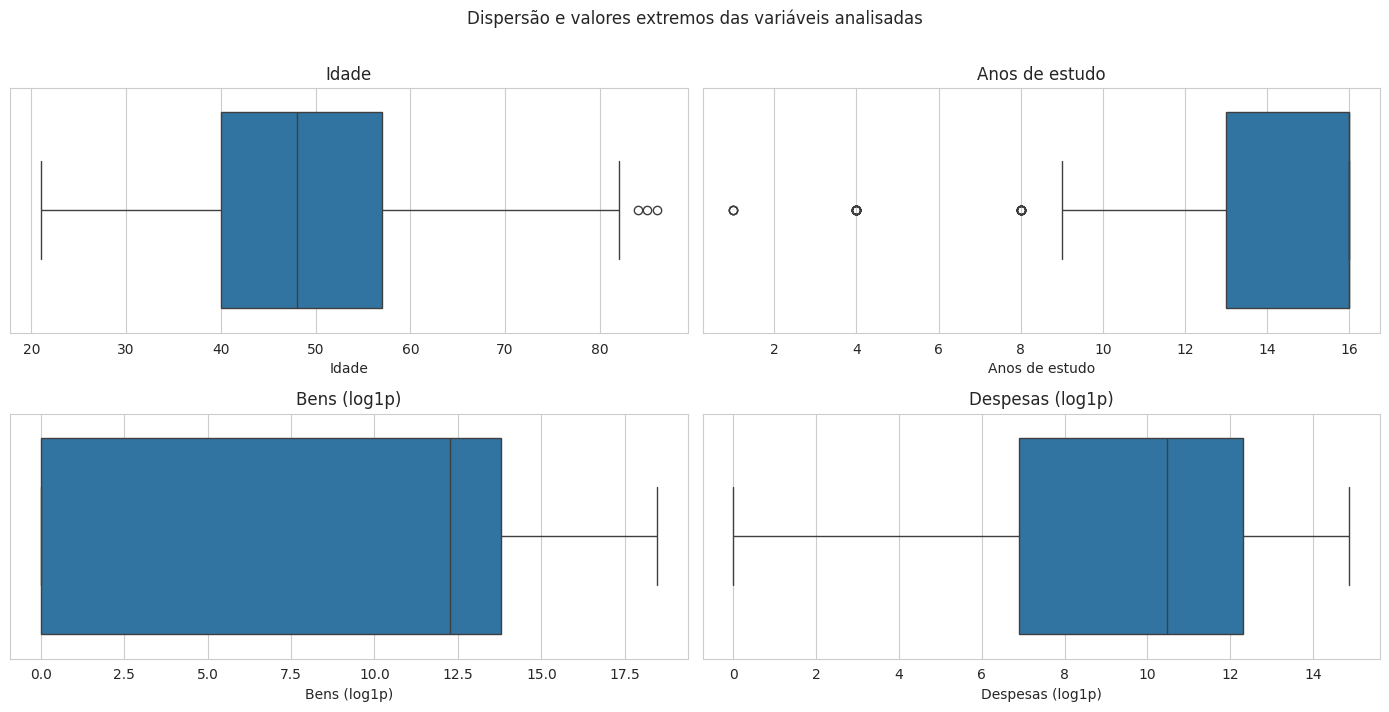

In [222]:
dados_boxplot = pd.DataFrame({
    'Idade': df['IDADE'],
    'Anos de estudo': df['ANOS_ESTUDO'],
    'Bens (log1p)': np.log1p(df['Total_Bens']),
    'Despesas (log1p)': df['Total_Gasto_Campanha_Log'],
})

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for ax, coluna in zip(axes.flat, dados_boxplot.columns):
    sns.boxplot(x=dados_boxplot[coluna], ax=ax)
    ax.set_title(coluna)

plt.suptitle('Dispersão e valores extremos das variáveis analisadas', y=1.01)
plt.tight_layout()
plt.show()

### 8.4) Leitura sintética do perfil

A célula seguinte transforma as medidas principais em frases, para registrar uma leitura objetiva da população sem depender apenas da inspeção dos gráficos.

In [223]:
print(
    f"• Idade: mediana de {df['IDADE'].median():.0f} anos "
    f"(Q1={df['IDADE'].quantile(0.25):.0f}; Q3={df['IDADE'].quantile(0.75):.0f})."
)
print(
    f"• Tempo de estudo equivalente: mediana de {df['ANOS_ESTUDO'].median():.0f} anos "
    f"(Q1={df['ANOS_ESTUDO'].quantile(0.25):.0f}; Q3={df['ANOS_ESTUDO'].quantile(0.75):.0f})."
)
print(
    f"• Bens declarados: mediana de R$ {df['Total_Bens'].median():,.2f}; "
    f"{df['Total_Bens'].eq(0).mean():.1%} declararam valor zero."
)
print(
    f"• Despesas declaradas: mediana de R$ {df['Total_Gasto_Campanha'].median():,.2f}; "
    f"{df['Total_Gasto_Campanha'].eq(0).mean():.1%} têm total zero no snapshot."
)
print(
    '• As médias financeiras acima das medianas e as caudas longas nos histogramas '
    'indicam forte assimetria; a escala logarítmica facilita a visualização dessas distribuições.'
)

• Idade: mediana de 48 anos (Q1=40; Q3=57).
• Tempo de estudo equivalente: mediana de 16 anos (Q1=13; Q3=16).
• Bens declarados: mediana de R$ 208,700.00; 28.0% declararam valor zero.
• Despesas declaradas: mediana de R$ 35,765.28; 22.5% têm total zero no snapshot.
• As médias financeiras acima das medianas e as caudas longas nos histogramas indicam forte assimetria; a escala logarítmica facilita a visualização dessas distribuições.


### 8.5) Pontos principais para a apresentação

- A população analisada contém **692 candidatos**: 262 de GO, 169 do DF, 138 de MT e 123 de MS.
- O candidato mediano tem **48 anos** e equivalência educacional de **16 anos de estudo**; essa última medida é uma aproximação baseada em faixas de escolaridade, não uma duração individual observada.
- O patrimônio mediano é **R$ 208,7 mil**, mas 28,0% registram valor zero. As despesas medianas são **R$ 35,8 mil**, com 22,5% em zero no snapshot.
- Médias muito superiores às medianas e caudas longas mostram que patrimônio e despesas são fortemente assimétricos. Por isso, a próxima fase deverá considerar transformação `log1p` e padronização antes do Bisecting K-Means.
- Entre as UFs, MT apresenta o maior patrimônio mediano (R$ 290 mil) e MS o menor (R$ 107,6 mil); essa diferença regional deverá ser retomada na interpretação dos clusters.

---
## Fechamento

Esta etapa estabelece o perfil da população e documenta assimetrias, zeros e valores extremos que precisam ser considerados na padronização e na interpretação dos clusters. As diferenças observadas aqui servirão de base para justificar as decisões metodológicas da etapa seguinte.

## Próximo passo

**Fase 2 — Clusterização com Bisecting K-Means**, usando idade, tempo de estudo, total de bens e total de despesas. Serão comparados diferentes valores de K por cotovelo e silhueta antes da escolha final.

# Fase 2 — Clusterização: Candidatos 2026 (TSE)

## Pergunta de negócio

> **Existem perfis demográfico-sociais distintos entre os candidatos a Deputado Federal do Centro-Oeste nas Eleições 2026? Combinando idade, escolaridade, patrimônio declarado e despesas de campanha, os candidatos se agrupam em segmentos claramente diferentes — e, se sim, como esses segmentos se distribuem em termos de gênero, cor/raça, profissão e estado civil?**

Para responder isso com K-Means, separamos as variáveis em dois papéis:

- **Variáveis-driver** (entram na conta de distância, definem os clusters): idade, escolaridade, patrimônio declarado e despesas de campanha.
- **Variáveis de perfil** (não entram no modelo — descrevem os clusters depois de prontos): `DS_GENERO`, `DS_COR_RACA`, `DS_ESTADO_CIVIL`, `DS_OCUPACAO`, partido e UF.

> `DS_SIT_TOT_TURNO` (situação eleitoral — eleito ou não) fica de fora por enquanto: a eleição de 2026 ainda não aconteceu, então essa coluna vem toda nula nesta base. Assim que o resultado sair, vale voltar aqui e cruzar os clusters com quem foi eleito.

Essa separação importa: jogar categóricas como gênero/raça direto numa distância Euclidiana exigiria codificação cuidadosa (fora do escopo desta primeira versão). Em vez disso, os grupos nascem de 4 variáveis contínuas/ordinais, e o "perfil demográfico-social" completo — que é o que a pergunta pede — aparece na leitura dos clusters, não na formação deles.

**Este notebook cobre a Parte 1 (K-Means)**, em **duas rodadas de propósito**, pra mostrar por que escolha de variável e escolha de métrica importam:

1. **Versão 1**: exatamente como fizemos na primeira tentativa — escolaridade entra como o código bruto do TSE, seleção de `k` só com cotovelo + silhouette.
2. **Versão 2**: escolaridade recodificada como variável intervalar, e mais duas métricas (Davies-Bouldin, Calinski-Harabasz) apoiando a escolha de `k`.

Depois das duas rodadas de K-Means, a Parte 2 aplica o **Bisecting K-Means** à mesma base e compara os resultados.

Parte do arquivo salvo pela **Fase 0** (`00_preparacao_dados.ipynb`).

## Configuração

Use os **mesmos valores** que você usou na Fase 0/1, para carregar o arquivo certo.

In [224]:
CARGO = "DEPUTADO FEDERAL"
UF = ['DF', 'GO', 'MS', 'MT']
ANO_ELEICAO = 2026
K_KMEANS = 5
K_BISECTING = 5

In [225]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

SEMENTE = 42
np.random.seed(SEMENTE)  # reprodutibilidade defensiva — o KMeans já usa random_state próprio,
                          # mas fixar a semente global evita surpresa se alguém adicionar
                          # outro trecho aleatório (amostragem, shuffle, etc.) mais adiante.

nome_uf = str(UF) if UF is not None else 'BRASIL'
nome_cargo = CARGO.replace(' ', '_')
arquivo = f"/dados/candidatos_{nome_cargo}_{nome_uf}_{ANO_ELEICAO}.csv"

df = pd.read_csv(arquivo)

# Integra as despesas contratadas das quatro UFs, como na análise descritiva.
ufs_despesas = [UF] if isinstance(UF, str) else UF
arquivos_despesas = [
    Path(f'/dados/despesas_contratadas_candidatos_{ANO_ELEICAO}_{uf}.csv')
    for uf in ufs_despesas
]
arquivos_ausentes = [str(p) for p in arquivos_despesas if not p.exists()]
if arquivos_ausentes:
    raise FileNotFoundError('Arquivos de despesas ausentes: ' + ', '.join(arquivos_ausentes))

partes_despesas = []
for caminho in arquivos_despesas:
    parte = pd.read_csv(
        caminho, sep=';', encoding='latin-1',
        usecols=['DS_CARGO', 'SQ_CANDIDATO', 'VR_DESPESA_CONTRATADA'],
        dtype={'SQ_CANDIDATO': 'int64'}
    )
    parte = parte[parte['DS_CARGO'].str.upper() == CARGO.upper()].copy()
    parte['VR_DESPESA_CONTRATADA'] = pd.to_numeric(
        parte['VR_DESPESA_CONTRATADA'].astype(str)
        .str.replace('.', '', regex=False).str.replace(',', '.', regex=False),
        errors='coerce'
    )
    partes_despesas.append(parte)

gasto_por_candidato = (
    pd.concat(partes_despesas, ignore_index=True)
    .groupby('SQ_CANDIDATO', as_index=False)['VR_DESPESA_CONTRATADA'].sum(min_count=1)
    .rename(columns={'VR_DESPESA_CONTRATADA': 'Total_Gasto_Campanha'})
)
df = df.merge(gasto_por_candidato, on='SQ_CANDIDATO', how='left')
df['Total_Gasto_Campanha'] = df['Total_Gasto_Campanha'].fillna(0)
df['Total_Gasto_Campanha_Log'] = np.log1p(df['Total_Gasto_Campanha'])

print(f"Carregado: {arquivo}  ->  {df.shape[0]} candidatos, {df.shape[1]} colunas")
df.head()

Carregado: /dados/candidatos_DEPUTADO_FEDERAL_['DF', 'GO', 'MS', 'MT']_2026.csv  ->  692 candidatos, 61 colunas


,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,SG_UF,SG_UE,NM_UE,CD_CARGO,DS_CARGO,SQ_CANDIDATO,NR_CANDIDATO,NM_CANDIDATO,NM_URNA_CANDIDATO,NM_SOCIAL_CANDIDATO,NR_CPF_CANDIDATO,DS_EMAIL,CD_SITUACAO_CANDIDATURA,DS_SITUACAO_CANDIDATURA,TP_AGREMIACAO,NR_PARTIDO,SG_PARTIDO,NM_PARTIDO,NR_FEDERACAO,NM_FEDERACAO,SG_FEDERACAO,DS_COMPOSICAO_FEDERACAO,SQ_COLIGACAO,NM_COLIGACAO,DS_COMPOSICAO_COLIGACAO,SG_UF_NASCIMENTO,DT_NASCIMENTO,NR_TITULO_ELEITORAL_CANDIDATO,CD_GENERO,DS_GENERO,CD_GRAU_INSTRUCAO,DS_GRAU_INSTRUCAO,CD_ESTADO_CIVIL,DS_ESTADO_CIVIL,CD_COR_RACA,DS_COR_RACA,CD_OCUPACAO,DS_OCUPACAO,CD_SIT_TOT_TURNO,DS_SIT_TOT_TURNO,BENS IMÓVEIS,BENS MÓVEIS,DINHEIRO,INVESTIMENTOS RENDA FIXA,INVESTIMENTOS RENDA VARIÁVEL,OUTROS BENS,Total_Bens,Total_Bens_Log,IDADE,Total_Gasto_Campanha,Total_Gasto_Campanha_Log
0,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532001,3022,ALESSANDRA ALMEIDA CHIANELLI DUTRA,ALE CHIANELLI,#NULO,58442472134,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,DF,1972-11-28,11236642070,4,FEMININO,8,SUPERIOR COMPLETO,9,DIVORCIADO(A),1,BRANCA,171,JORNALISTA E REDATOR,-1,#NULO,0.00,"130,000.00",0.00,0.00,0.00,0.00,"130,000.00",11.78,53,"89,958.81",11.41
1,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532002,3012,PAULO CESAR ECHEBARRIA DE CARVALHO,PAULO ECHEBARRIA,#NULO,37959077134,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,GO,1965-10-20,7033782089,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),1,BRANCA,171,JORNALISTA E REDATOR,-1,#NULO,0.00,"380,000.00",0.00,0.00,0.00,"15,000,000.00","15,380,000.00",16.55,60,"3,000.00",8.01
2,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532003,3004,FLAVIO HENRIQUE TORMINN FLEURY,FLAVIO FLEURY,#NULO,88847560144,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,GO,1981-09-01,46935651074,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),1,BRANCA,114,FISIOTERAPEUTA E TERAPEUTA OCUPACIONAL,-1,#NULO,0.00,"53,000.00",0.00,0.00,0.00,0.00,"53,000.00",10.88,45,"1,628.83",7.40
3,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532004,3030,CARINE TEIXEIRA MARQUES,CARINE TEIXEIRA,#NULO,1642767182,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,GO,1986-08-25,52572671066,4,FEMININO,8,SUPERIOR COMPLETO,3,CASADO(A),2,PRETA,257,EMPRESÁRIO,-1,#NULO,0.00,0.00,0.00,0.00,"120,000.00",0.00,"120,000.00",11.70,40,"3,443.50",8.14
4,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532005,3010,EMILIO KERBER FILHO,EMILIO KERBER,#NULO,92759130053,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,PR,1976-08-31,263044410167,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),1,BRANCA,185,ESCRITOR E CRÍTICO,-1,#NULO,"1,380,000.00",0.00,0.00,0.00,0.00,0.00,"1,380,000.00",14.14,50,"2,297.78",7.74


---
# Versão 1 — a primeira tentativa

Variáveis-driver: `IDADE`, `CD_GRAU_INSTRUCAO` (código bruto do TSE, 2 a 8), `Total_Bens_Log` e `Total_Gasto_Campanha_Log`. Escolha de `k` só com cotovelo (WCSS) + silhouette.

### V1.1) Outliers e padronização

In [226]:
colunas_driver_v1 = ['IDADE', 'CD_GRAU_INSTRUCAO', 'Total_Bens_Log', 'Total_Gasto_Campanha_Log']

antes = df.shape[0]
Q1, Q3 = df['Total_Bens_Log'].quantile([0.25, 0.75])
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

df_cluster_v1 = df[df['Total_Bens_Log'] <= limite_superior].copy()
print(f"Removidos {antes - df_cluster_v1.shape[0]} candidatos com patrimônio extremo "
      f"(Total_Bens_Log > {limite_superior:.2f}, ~R$ {np.expm1(limite_superior):,.0f})")
print(f"Base para clusterização: {df_cluster_v1.shape[0]} candidatos")

scaler_v1 = MinMaxScaler()
X_v1 = scaler_v1.fit_transform(df_cluster_v1[colunas_driver_v1])

df_cluster_v1[colunas_driver_v1].describe()

Removidos 0 candidatos com patrimônio extremo (Total_Bens_Log > 34.46, ~R$ 927,725,026,861,692)
Base para clusterização: 692 candidatos


,IDADE,CD_GRAU_INSTRUCAO,Total_Bens_Log,Total_Gasto_Campanha_Log
count,692.00,692.00,692.00,692.00
mean,48.57,7.24,9.41,8.58
std,12.51,1.26,6.09,5.03
min,21.00,2.00,0.00,0.00
25%,40.00,7.00,0.00,6.91
50%,48.00,8.00,12.25,10.48
75%,57.00,8.00,13.79,12.30
max,86.00,8.00,18.46,14.88


### V1.2) Escolhendo k (cotovelo + silhouette)

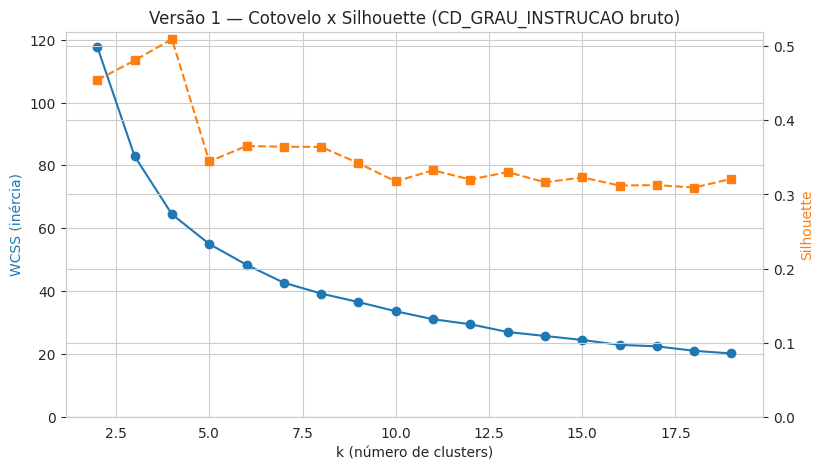

k=2  WCSS=117.669  silhouette=0.454
k=3  WCSS=82.888  silhouette=0.481
k=4  WCSS=64.435  silhouette=0.510
k=5  WCSS=54.984  silhouette=0.345
k=6  WCSS=48.359  silhouette=0.365
k=7  WCSS=42.653  silhouette=0.364
k=8  WCSS=39.204  silhouette=0.364
k=9  WCSS=36.494  silhouette=0.342
k=10  WCSS=33.569  silhouette=0.318
k=11  WCSS=31.025  silhouette=0.333
k=12  WCSS=29.433  silhouette=0.320
k=13  WCSS=26.975  silhouette=0.330
k=14  WCSS=25.703  silhouette=0.316
k=15  WCSS=24.430  silhouette=0.323
k=16  WCSS=22.870  silhouette=0.312
k=17  WCSS=22.398  silhouette=0.313
k=18  WCSS=20.983  silhouette=0.309
k=19  WCSS=20.129  silhouette=0.321


In [227]:
wcss_v1, sil_v1 = [], []
faixa_k = range(2, 20)

for k in faixa_k:
    km = KMeans(n_clusters=k, random_state=SEMENTE, n_init=10)
    labels = km.fit_predict(X_v1)
    wcss_v1.append(km.inertia_)
    sil_v1.append(silhouette_score(X_v1, labels))

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(list(faixa_k), wcss_v1, marker='o', color='tab:blue')
ax1.set_xlabel('k (número de clusters)')
ax1.set_ylabel('WCSS (inércia)', color='tab:blue')
ax1.set_ylim(bottom=0)  # eixo começa em zero: um eixo cortado pode fazer o cotovelo parecer mais dramático do que é
ax1.set_title('Versão 1 — Cotovelo x Silhouette (CD_GRAU_INSTRUCAO bruto)')

ax2 = ax1.twinx()
ax2.plot(list(faixa_k), sil_v1, marker='s', linestyle='--', color='tab:orange')
ax2.set_ylabel('Silhouette', color='tab:orange')
ax2.set_ylim(bottom=min(0, min(sil_v1)))
plt.show()

for k, w, s in zip(faixa_k, wcss_v1, sil_v1):
    print(f"k={k}  WCSS={w:.3f}  silhouette={s:.3f}")

> Repare que o cotovelo não mostra uma quebra nítida — a curva desce suavemente, sem um "V" claro. Isso pode ser dado real (candidatos formando mais um contínuo do que grupos separados) ou pode ser efeito de tratar uma variável ordinal como se fosse intervalar. Seguimos mesmo assim com um `k` razoável, só pra completar a Versão 1 e comparar depois.

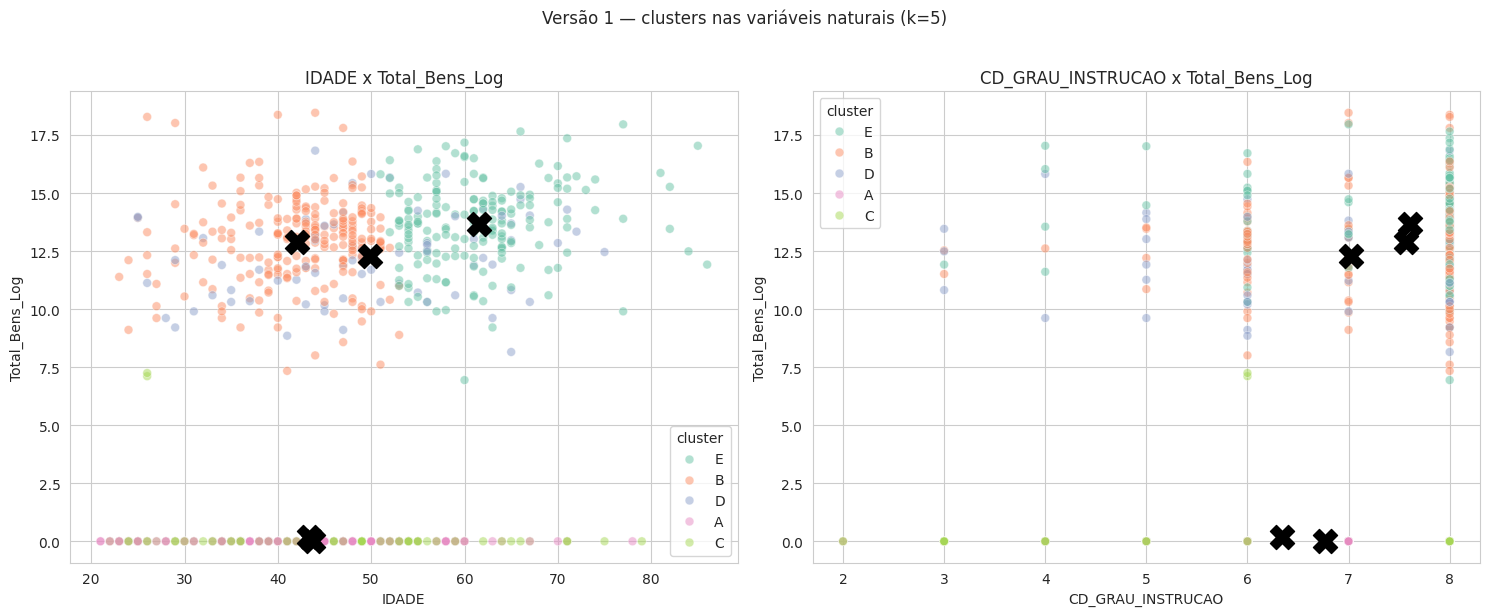

,qtd_candidatos,idade_media,instrucao_media,patrimonio_mediano,despesas_medianas
cluster,,,,,
A,110,43.80,6.80,0.00,"20,750.20"
B,235,42.10,7.60,"465,000.00","123,934.20"
C,86,43.30,6.30,0.00,0.00
D,77,49.90,7.00,"250,000.00",0.00
E,184,61.60,7.60,"920,954.50","133,636.70"


In [228]:
k_v1 = K_KMEANS

kmeans_v1 = KMeans(n_clusters=k_v1, random_state=SEMENTE, n_init=10)
df_cluster_v1['cluster'] = kmeans_v1.fit_predict(X_v1)
df_cluster_v1['cluster'] = df_cluster_v1['cluster'].map(lambda x: chr(65 + x))

centroides_v1 = scaler_v1.inverse_transform(kmeans_v1.cluster_centers_)
df_centroides_v1 = pd.DataFrame(centroides_v1, columns=colunas_driver_v1)
df_centroides_v1.index = [chr(65 + i) for i in range(k_v1)]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(data=df_cluster_v1, x='IDADE', y='Total_Bens_Log', hue='cluster', palette='Set2', alpha=0.5, s=40, ax=axes[0])
axes[0].scatter(df_centroides_v1['IDADE'], df_centroides_v1['Total_Bens_Log'], marker='X', s=300, c='black')
axes[0].set_title('IDADE x Total_Bens_Log')

sns.scatterplot(data=df_cluster_v1, x='CD_GRAU_INSTRUCAO', y='Total_Bens_Log', hue='cluster', palette='Set2', alpha=0.5, s=40, ax=axes[1])
axes[1].scatter(df_centroides_v1['CD_GRAU_INSTRUCAO'], df_centroides_v1['Total_Bens_Log'], marker='X', s=300, c='black')
axes[1].set_title('CD_GRAU_INSTRUCAO x Total_Bens_Log')

plt.suptitle(f'Versão 1 — clusters nas variáveis naturais (k={k_v1})', y=1.02)
plt.tight_layout()
plt.show()

resumo_v1 = df_cluster_v1.groupby('cluster').agg(
    qtd_candidatos=('SQ_CANDIDATO', 'count'),
    idade_media=('IDADE', 'mean'),
    instrucao_media=('CD_GRAU_INSTRUCAO', 'mean'),
    patrimonio_mediano=('Total_Bens', 'median'),
    despesas_medianas=('Total_Gasto_Campanha', 'median'),
).round(1)
display(resumo_v1)

---
# Versão 2 — ajustando a variável e a métrica

Dois ajustes em relação à Versão 1:

1. **Escolaridade como variável intervalar.** `CD_GRAU_INSTRUCAO` é um código **ordinal**, não intervalar: nada garante que o "salto" entre dois códigos consecutivos valha o mesmo em todos os pontos da escala (a diferença entre "lê e escreve" e "fundamental incompleto" não é comparável à diferença entre "superior incompleto" e "superior completo"). Como o K-Means calcula médias e distância Euclidiana, ele *assume* espaçamento igual — então usar o código bruto distorce essa variável. Trocamos pelo proxy padrão em pesquisa social: **anos de escolaridade equivalentes** (mesma lógica usada em censos/pesquisas domiciliares).
2. **Mais métricas para escolher `k`.** Além de WCSS e silhouette, adicionamos Davies-Bouldin e Calinski-Harabasz — quando o cotovelo é ambíguo (como foi o caso), várias métricas concordando é um sinal mais forte do que uma métrica só.

In [229]:
ANOS_ESTUDO_POR_GRAU = {
    'ANALFABETO': 0,
    'LÊ E ESCREVE': 1,
    'ENSINO FUNDAMENTAL INCOMPLETO': 4,
    'ENSINO FUNDAMENTAL COMPLETO': 8,
    'ENSINO MÉDIO INCOMPLETO': 9,
    'ENSINO MÉDIO COMPLETO': 11,
    'SUPERIOR INCOMPLETO': 13,
    'SUPERIOR COMPLETO': 16,
    # 'NÃO DIVULGÁVEL' fica de fora de propósito — não dá pra estimar anos de estudo sem essa informação
}

df['ANOS_ESTUDO'] = df['DS_GRAU_INSTRUCAO'].map(ANOS_ESTUDO_POR_GRAU)

print("Candidatos sem correspondência (NÃO DIVULGÁVEL ou similar):", df['ANOS_ESTUDO'].isna().sum())
df[['DS_GRAU_INSTRUCAO', 'ANOS_ESTUDO']].drop_duplicates().sort_values('ANOS_ESTUDO')

Candidatos sem correspondência (NÃO DIVULGÁVEL ou similar): 0


,DS_GRAU_INSTRUCAO,ANOS_ESTUDO
185,LÊ E ESCREVE,1
72,ENSINO FUNDAMENTAL INCOMPLETO,4
105,ENSINO FUNDAMENTAL COMPLETO,8
34,ENSINO MÉDIO INCOMPLETO,9
26,ENSINO MÉDIO COMPLETO,11
19,SUPERIOR INCOMPLETO,13
0,SUPERIOR COMPLETO,16


> **Alternativa mais rigorosa (fora do escopo desta primeira versão):** distância de **Gower** — que trata variáveis ordinais, nominais e contínuas de forma nativa, sem forçar nenhuma delas a um espaçamento artificial — combinada com **K-Medoids/PAM** em vez de K-Means (Gower não permite calcular "média", só distância entre pontos reais). Fica como comparação futura, ao lado de DBSCAN/hierárquico/Bisecting K-Means.

### V2.1) Outliers e padronização

In [230]:
colunas_driver = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log', 'Total_Gasto_Campanha_Log']

antes = df.shape[0]
df_cluster = df[(df['Total_Bens_Log'] <= limite_superior) & (df['ANOS_ESTUDO'].notna())].copy()
print(f"Removidos {antes - df_cluster.shape[0]} candidatos "
      f"(patrimônio extremo acima de ~R$ {np.expm1(limite_superior):,.0f}, ou escolaridade não divulgada)")
print(f"Base para clusterização: {df_cluster.shape[0]} candidatos")

scaler = MinMaxScaler()
X = scaler.fit_transform(df_cluster[colunas_driver])

df_cluster[colunas_driver].describe()

Removidos 0 candidatos (patrimônio extremo acima de ~R$ 927,725,026,861,692, ou escolaridade não divulgada)
Base para clusterização: 692 candidatos


,IDADE,ANOS_ESTUDO,Total_Bens_Log,Total_Gasto_Campanha_Log
count,692.00,692.00,692.00,692.00
mean,48.57,14.11,9.41,8.58
std,12.51,3.01,6.09,5.03
min,21.00,1.00,0.00,0.00
25%,40.00,13.00,0.00,6.91
50%,48.00,16.00,12.25,10.48
75%,57.00,16.00,13.79,12.30
max,86.00,16.00,18.46,14.88


### V2.2) Escolhendo k (cotovelo + silhouette + Davies-Bouldin + Calinski-Harabasz)

- **Silhouette** (quanto maior, melhor).
- **Davies-Bouldin** (quanto **menor**, melhor): quão parecidos/sobrepostos os clusters são entre si.
- **Calinski-Harabasz** (quanto maior, melhor): razão entre dispersão entre clusters e dispersão dentro dos clusters.

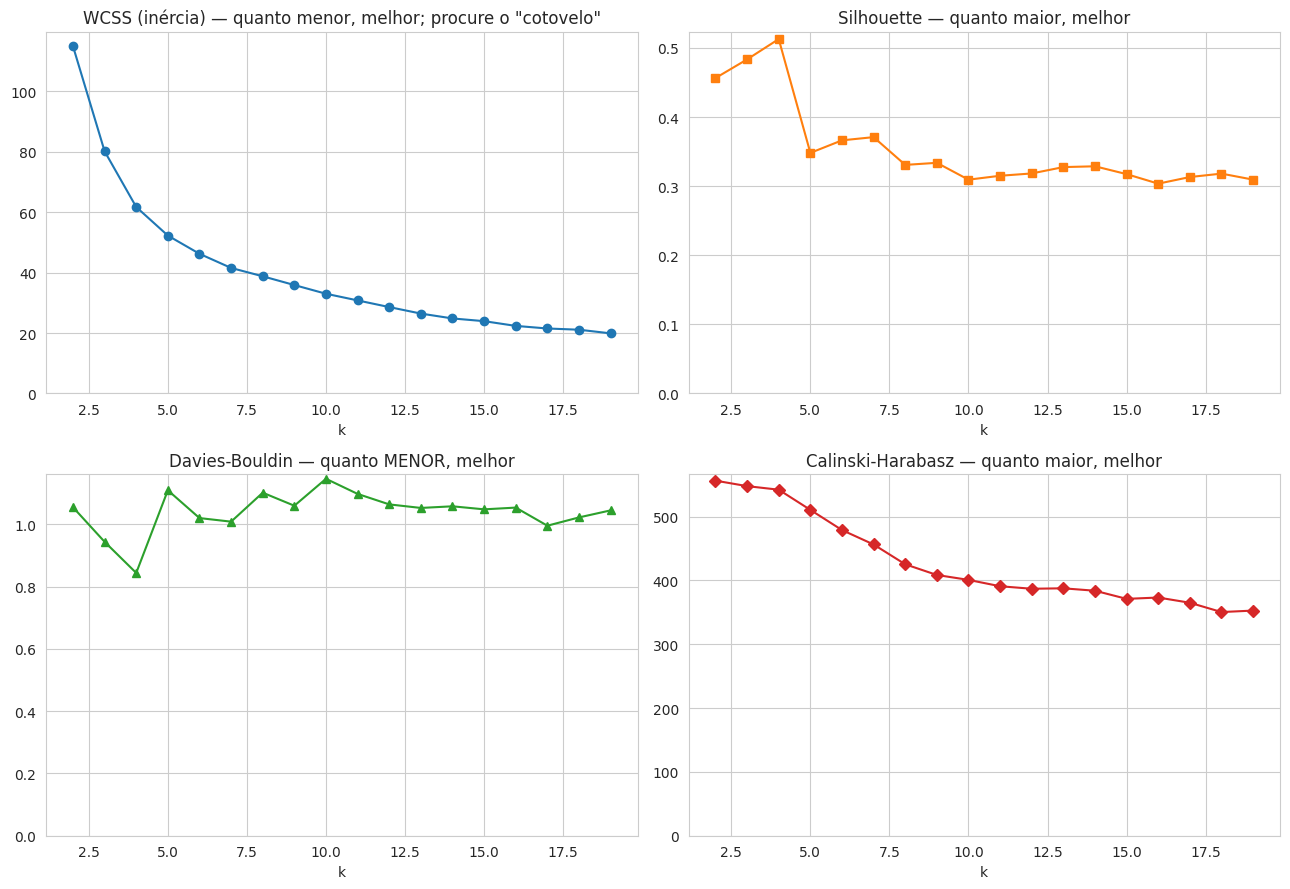

,k,wcss,silhouette,davies_bouldin,calinski_harabasz
0,2,114.97,0.46,1.05,556.45
1,3,80.18,0.48,0.94,547.87
2,4,61.73,0.51,0.84,542.27
3,5,52.27,0.35,1.11,510.64
4,6,46.24,0.37,1.02,479.02
5,7,41.56,0.37,1.01,456.41
6,8,38.80,0.33,1.10,425.37
7,9,35.89,0.33,1.06,408.63
8,10,33.02,0.31,1.15,400.93
9,11,30.81,0.32,1.10,390.97


In [231]:
wcss, sil, db, ch = [], [], [], []

for k in faixa_k:
    km = KMeans(n_clusters=k, random_state=SEMENTE, n_init=10)
    labels = km.fit_predict(X)
    wcss.append(km.inertia_)
    sil.append(silhouette_score(X, labels))
    db.append(davies_bouldin_score(X, labels))
    ch.append(calinski_harabasz_score(X, labels))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].plot(list(faixa_k), wcss, marker='o', color='tab:blue')
axes[0, 0].set_title('WCSS (inércia) — quanto menor, melhor; procure o "cotovelo"')
axes[0, 0].set_ylim(bottom=0)

axes[0, 1].plot(list(faixa_k), sil, marker='s', color='tab:orange')
axes[0, 1].set_title('Silhouette — quanto maior, melhor')
axes[0, 1].set_ylim(bottom=min(0, min(sil)))

axes[1, 0].plot(list(faixa_k), db, marker='^', color='tab:green')
axes[1, 0].set_title('Davies-Bouldin — quanto MENOR, melhor')
axes[1, 0].set_ylim(bottom=0)

axes[1, 1].plot(list(faixa_k), ch, marker='D', color='tab:red')
axes[1, 1].set_title('Calinski-Harabasz — quanto maior, melhor')
axes[1, 1].set_ylim(bottom=0)

# eixo em zero: evita que um eixo cortado exagere visualmente uma quebra que não é tão forte assim
for ax in axes.flatten():
    ax.set_xlabel('k')
    ax.grid(True)

plt.tight_layout()
plt.show()

pd.DataFrame({'k': list(faixa_k), 'wcss': wcss, 'silhouette': sil, 'davies_bouldin': db, 'calinski_harabasz': ch}).round(3)

### V2.3) Ajustando o K-Means

Pela leitura do cotovelo da WCSS e pelo interesse em obter uma segmentação mais detalhada, adotamos **k=5**. Existe um trade-off importante: `k=4` apresenta melhores índices internos (silhouette de 0,513 e Davies-Bouldin de 0,844), enquanto em `k=5` a silhouette cai para 0,348. Portanto, a escolha de cinco grupos privilegia a granularidade e a interpretação dos perfis, e não a maximização isolada da silhouette.

In [232]:
k_final = K_KMEANS

kmeans = KMeans(n_clusters=k_final, random_state=SEMENTE, n_init=10)
df_cluster['cluster'] = kmeans.fit_predict(X)
df_cluster['cluster'] = df_cluster['cluster'].map(lambda x: chr(65 + x))

# Paleta única e fixa por cluster — reaproveitada em TODOS os gráficos daqui pra frente,
# pra cluster A ter sempre a mesma cor, em qualquer tipo de gráfico (scatter, barra, radar...).
clusters_ordenados = sorted(df_cluster['cluster'].unique())
cores_cluster = dict(zip(clusters_ordenados, sns.color_palette('Set2', n_colors=len(clusters_ordenados))))

df_cluster['cluster'].value_counts().sort_index()

,count
cluster,
A,185
B,86
C,234
D,110
E,77


In [233]:
resumo_driver = df_cluster.groupby('cluster').agg(
    qtd_candidatos=('SQ_CANDIDATO', 'count'),
    idade_media=('IDADE', 'mean'),
    anos_estudo_medio=('ANOS_ESTUDO', 'mean'),
    patrimonio_mediano=('Total_Bens', 'median'),
    despesas_medianas=('Total_Gasto_Campanha', 'median'),
).round(1)
display(resumo_driver)

centroides_norm = kmeans.cluster_centers_
centroides_naturais = scaler.inverse_transform(centroides_norm)
df_centroides = pd.DataFrame(centroides_naturais, columns=colunas_driver)
df_centroides.index = [chr(65 + i) for i in range(k_final)]
df_centroides.index.name = 'cluster'
df_centroides.round(1)

,qtd_candidatos,idade_media,anos_estudo_medio,patrimonio_mediano,despesas_medianas
cluster,,,,,
A,185,61.50,15.10,"912,909.10","132,480.40"
B,86,43.30,11.90,0.00,0.00
C,234,42.10,14.90,"471,500.00","124,255.10"
D,110,43.80,12.90,0.00,"20,750.20"
E,77,49.90,13.60,"250,000.00",0.00


,IDADE,ANOS_ESTUDO,Total_Bens_Log,Total_Gasto_Campanha_Log
cluster,,,,
A,61.50,15.10,13.70,11.60
B,43.30,11.90,0.20,0.20
C,42.10,14.90,12.90,11.50
D,43.80,12.90,-0.00,9.80
E,49.90,13.60,12.30,0.10


### Radar: todos os clusters juntos, e depois um a um

Primeiro, todos os clusters sobrepostos no mesmo radar — bom pra comparar formatos de relance. Logo abaixo, o mesmo radar **separado por cluster** — mais fácil de ler o formato de cada um sem o excesso de linhas sobrepostas. As duas versões usam os centróides **na escala padronizada (0 a 1)**, que é o que torna os 4 eixos comparáveis entre si.

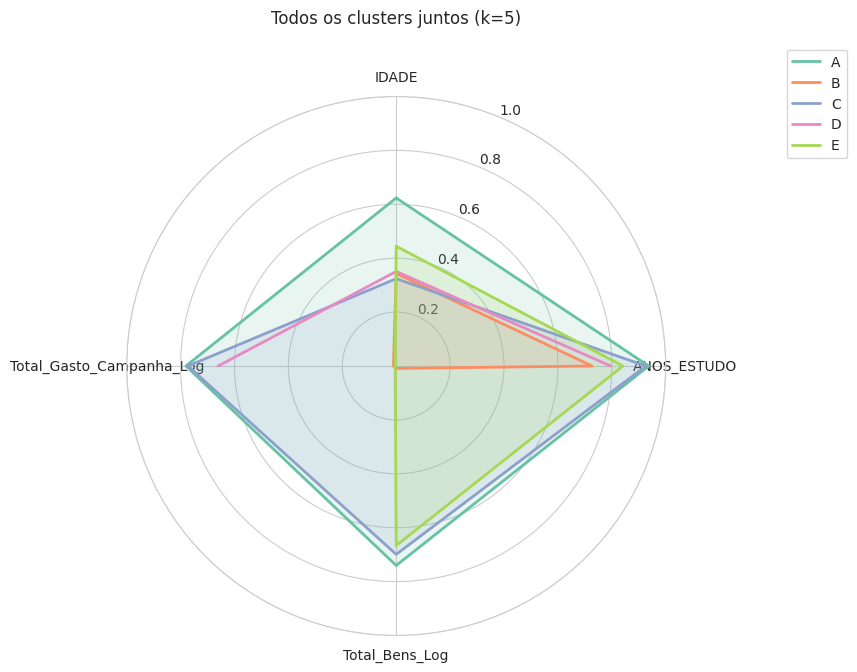

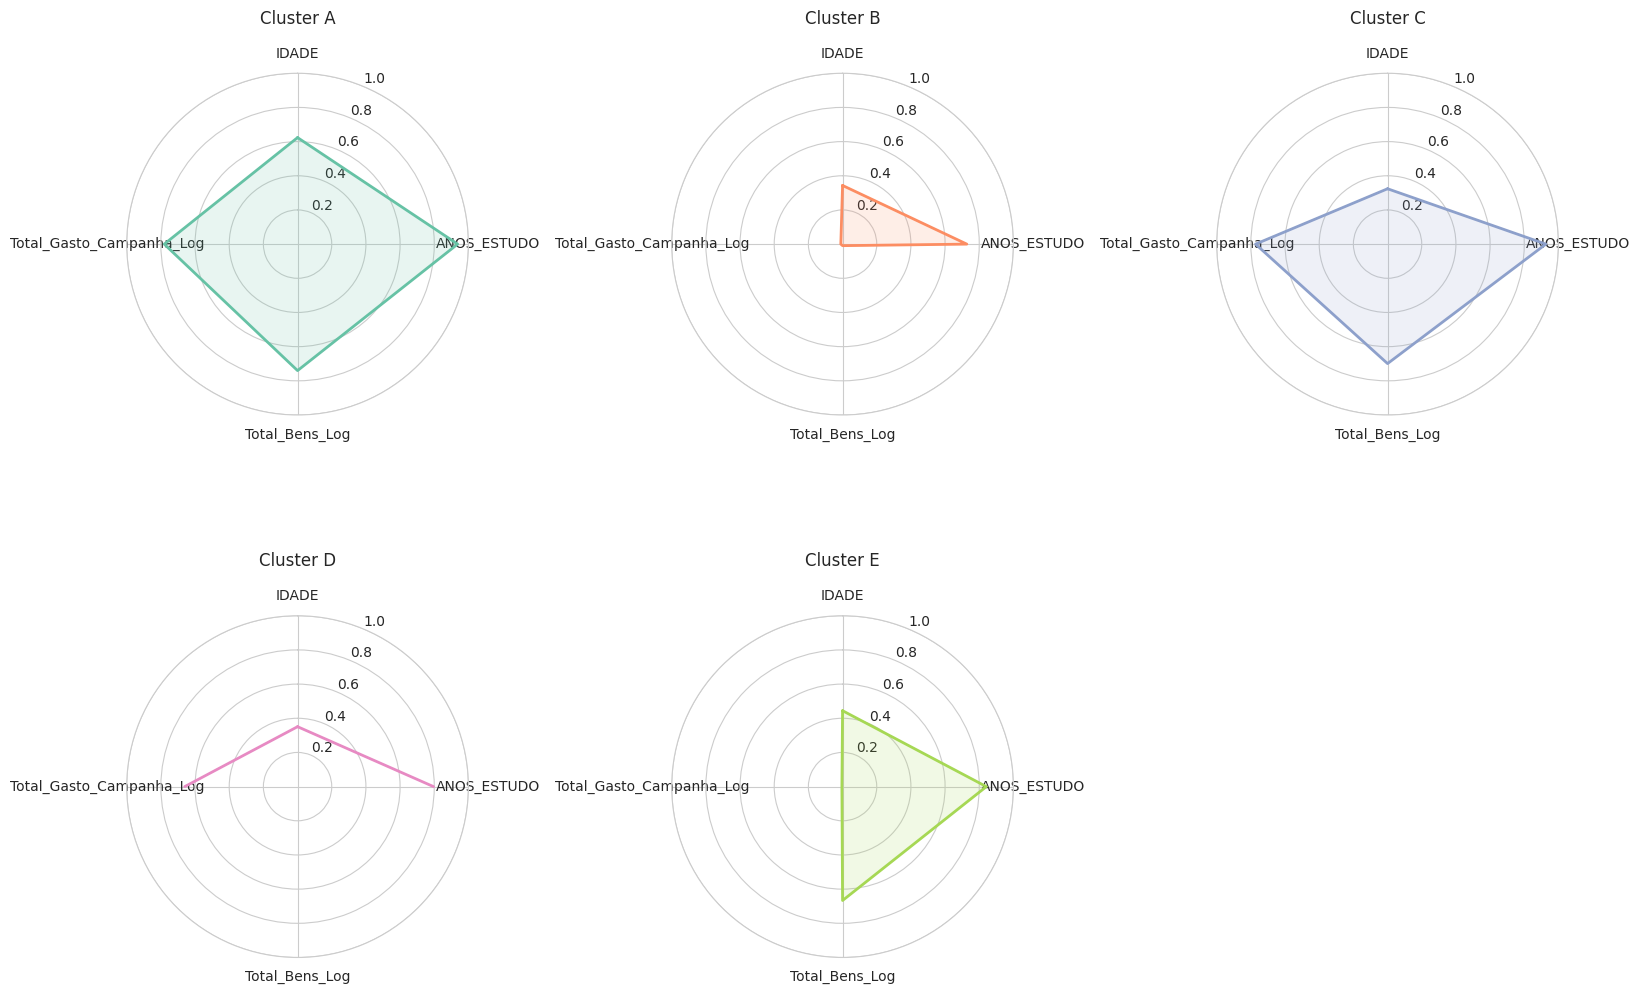

In [234]:
from math import pi

def plot_radar(ax, centros, labels_eixos, labels_series, cores, titulo):
    n_eixos = len(labels_eixos)
    angulos = [n / float(n_eixos) * 2 * pi for n in range(n_eixos)]
    angulos += angulos[:1]

    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)
    ax.set_xticks(angulos[:-1])
    ax.set_xticklabels(labels_eixos)
    ax.set_ylim(0, 1)

    for i, linha in enumerate(centros):
        valores = list(linha) + [linha[0]]
        cor = cores[labels_series[i]]
        ax.plot(angulos, valores, linewidth=2, label=labels_series[i], color=cor)
        ax.fill(angulos, valores, alpha=0.15, color=cor)

    ax.set_title(titulo, y=1.12)

# --- todos juntos ---
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
plot_radar(ax, centroides_norm, colunas_driver, clusters_ordenados, cores_cluster,
           f'Todos os clusters juntos (k={k_final})')
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))
plt.show()

# --- um radar por cluster ---
ncols = min(k_final, 3)
nrows = -(-k_final // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 5.5 * nrows), subplot_kw=dict(polar=True))
axes = axes.flatten() if k_final > 1 else [axes]

for i, cl in enumerate(clusters_ordenados):
    plot_radar(axes[i], [centroides_norm[i]], colunas_driver, [cl], cores_cluster, f'Cluster {cl}')

for j in range(len(clusters_ordenados), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

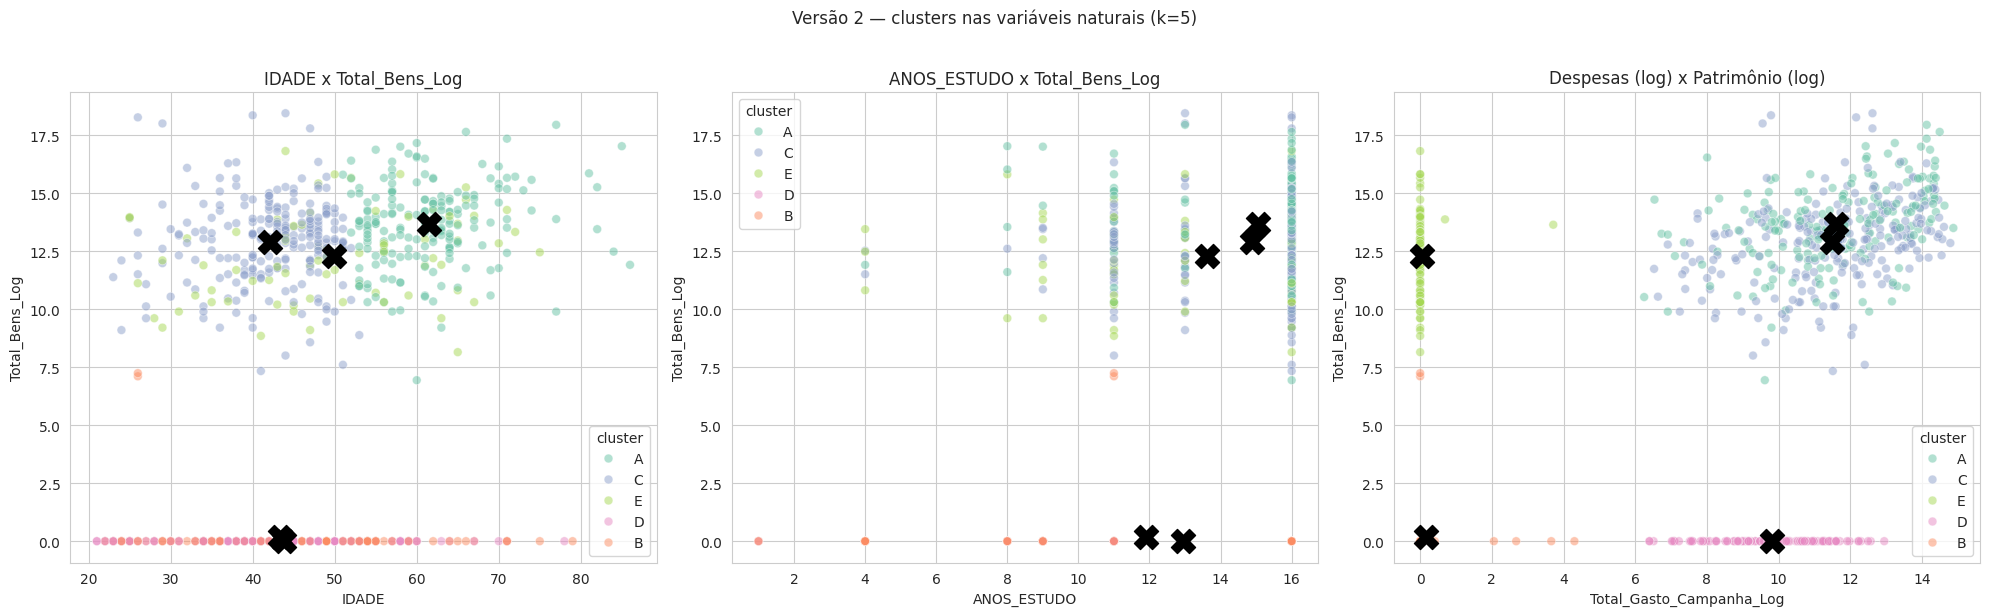

In [235]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.scatterplot(data=df_cluster, x='IDADE', y='Total_Bens_Log', hue='cluster', palette=cores_cluster, alpha=0.5, s=40, ax=axes[0])
axes[0].scatter(df_centroides['IDADE'], df_centroides['Total_Bens_Log'], marker='X', s=300, c='black')
axes[0].set_title('IDADE x Total_Bens_Log')

sns.scatterplot(data=df_cluster, x='ANOS_ESTUDO', y='Total_Bens_Log', hue='cluster', palette=cores_cluster, alpha=0.5, s=40, ax=axes[1])
axes[1].scatter(df_centroides['ANOS_ESTUDO'], df_centroides['Total_Bens_Log'], marker='X', s=300, c='black')
axes[1].set_title('ANOS_ESTUDO x Total_Bens_Log')

sns.scatterplot(data=df_cluster, x='Total_Gasto_Campanha_Log', y='Total_Bens_Log', hue='cluster', palette=cores_cluster, alpha=0.5, s=40, ax=axes[2])
axes[2].scatter(df_centroides['Total_Gasto_Campanha_Log'], df_centroides['Total_Bens_Log'], marker='X', s=300, c='black')
axes[2].set_title('Despesas (log) x Patrimônio (log)')

plt.suptitle(f'Versão 2 — clusters nas variáveis naturais (k={k_final})', y=1.02)
plt.tight_layout()
plt.show()

---
## Comparando Versão 1 x Versão 2

Duas coisas pra olhar lado a lado: a **métrica de qualidade** (silhouette) e o **tamanho dos grupos** — se a distribuição de candidatos por cluster mudou bastante, é sinal de que a troca de variável/métrica realmente importou.

Versão 1 (CD_GRAU_INSTRUCAO bruto), k=5: silhouette = 0.345
Versão 2 (ANOS_ESTUDO),           k=5: silhouette = 0.348


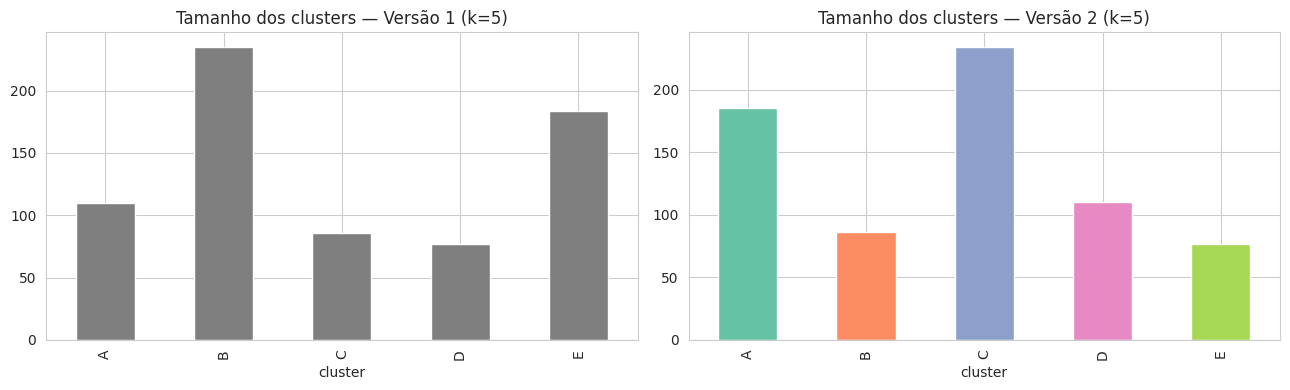

In [236]:
print(f"Versão 1 (CD_GRAU_INSTRUCAO bruto), k={k_v1}: silhouette = {sil_v1[list(faixa_k).index(k_v1)]:.3f}")
print(f"Versão 2 (ANOS_ESTUDO),           k={k_final}: silhouette = {sil[list(faixa_k).index(k_final)]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df_cluster_v1['cluster'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='tab:gray')
axes[0].set_title(f'Tamanho dos clusters — Versão 1 (k={k_v1})')

contagem_v2 = df_cluster['cluster'].value_counts().sort_index()
contagem_v2.plot(kind='bar', ax=axes[1], color=[cores_cluster[c] for c in contagem_v2.index])
axes[1].set_title(f'Tamanho dos clusters — Versão 2 (k={k_final})')

plt.tight_layout()
plt.show()

---
## Perfil demográfico-social de cada cluster

A partir daqui usamos a **Versão 2** (ajustada) como resultado oficial. Primeiro pelas variáveis-driver (já visto acima), agora pelas variáveis de perfil — o que responde de fato a pergunta de negócio.

### Composição demográfica de cada cluster (variáveis de perfil)

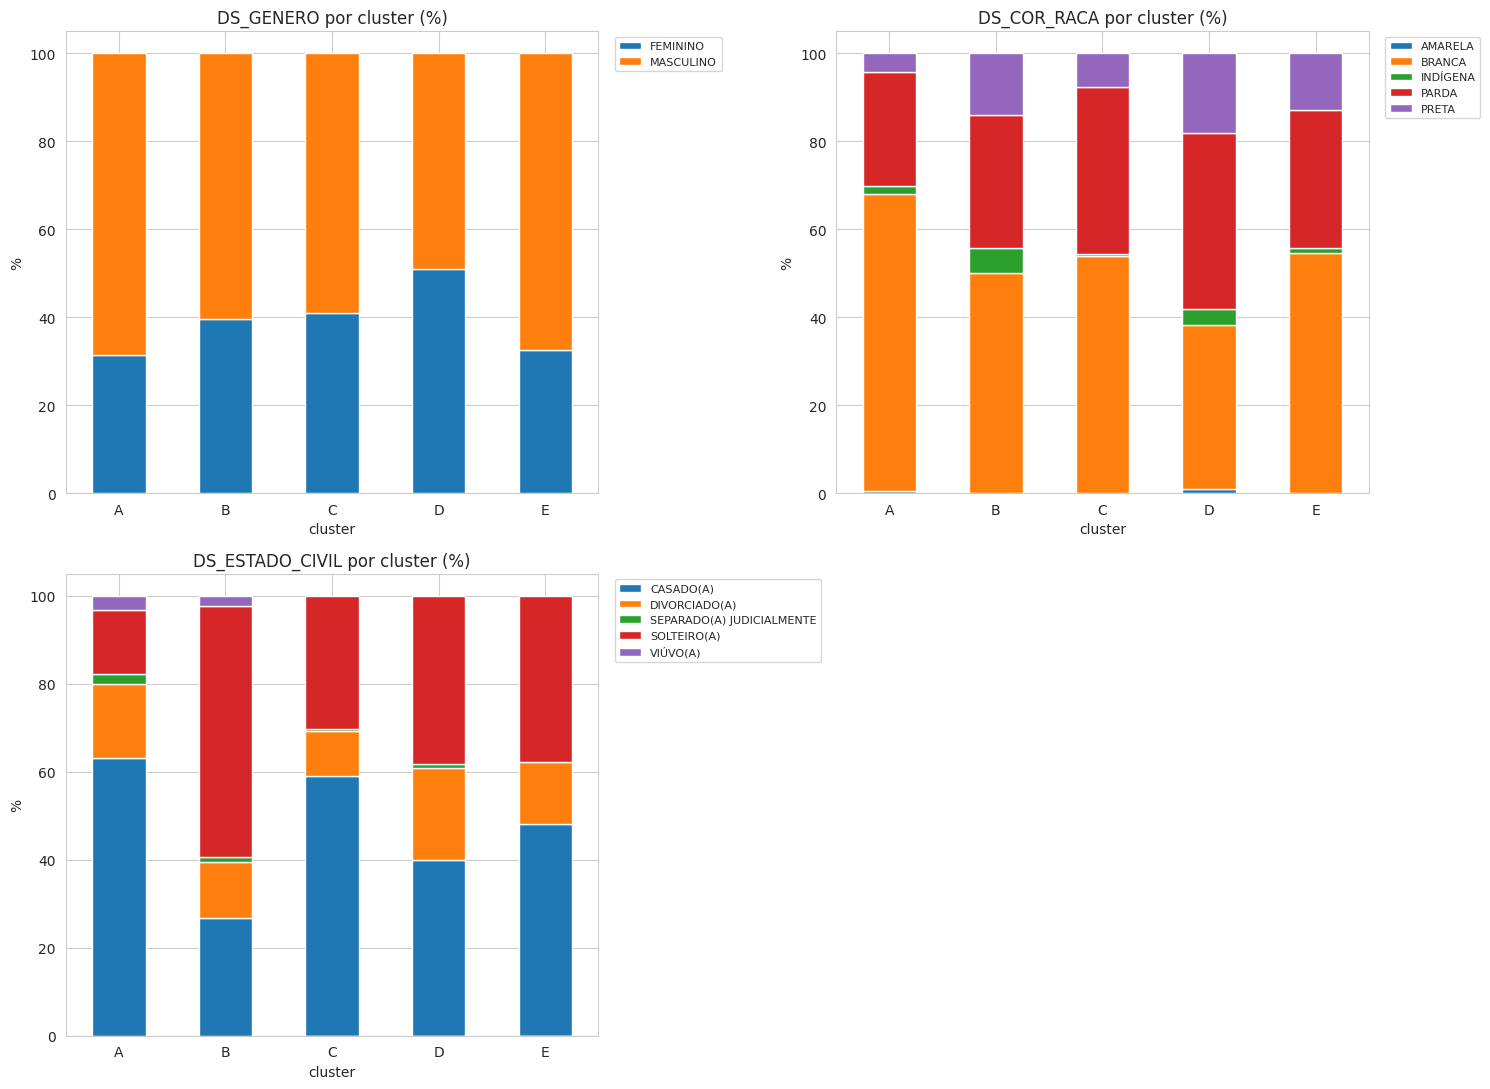

In [237]:
# DS_SIT_TOT_TURNO fica de fora por enquanto — a eleição de 2026 ainda não ocorreu,
# então essa coluna vem toda nula na base atual.
colunas_perfil = ['DS_GENERO', 'DS_COR_RACA', 'DS_ESTADO_CIVIL']
colunas_perfil = [c for c in colunas_perfil if c in df_cluster.columns]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(colunas_perfil):
    pd.crosstab(df_cluster['cluster'], df_cluster[col], normalize='index').mul(100).plot(
        kind='bar', stacked=True, ax=axes[i]
    )
    axes[i].set_title(f'{col} por cluster (%)')
    axes[i].set_ylabel('%')
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Pizza: a composição de cada cluster, isoladamente

As barras acima comparam os clusters entre si — é a leitura mais rigorosa quando o que importa é comparar. As pizzas abaixo mostram a mesma informação de um jeito mais familiar pra quem só quer ver "como é o cluster A por dentro", uma variável e um cluster de cada vez.

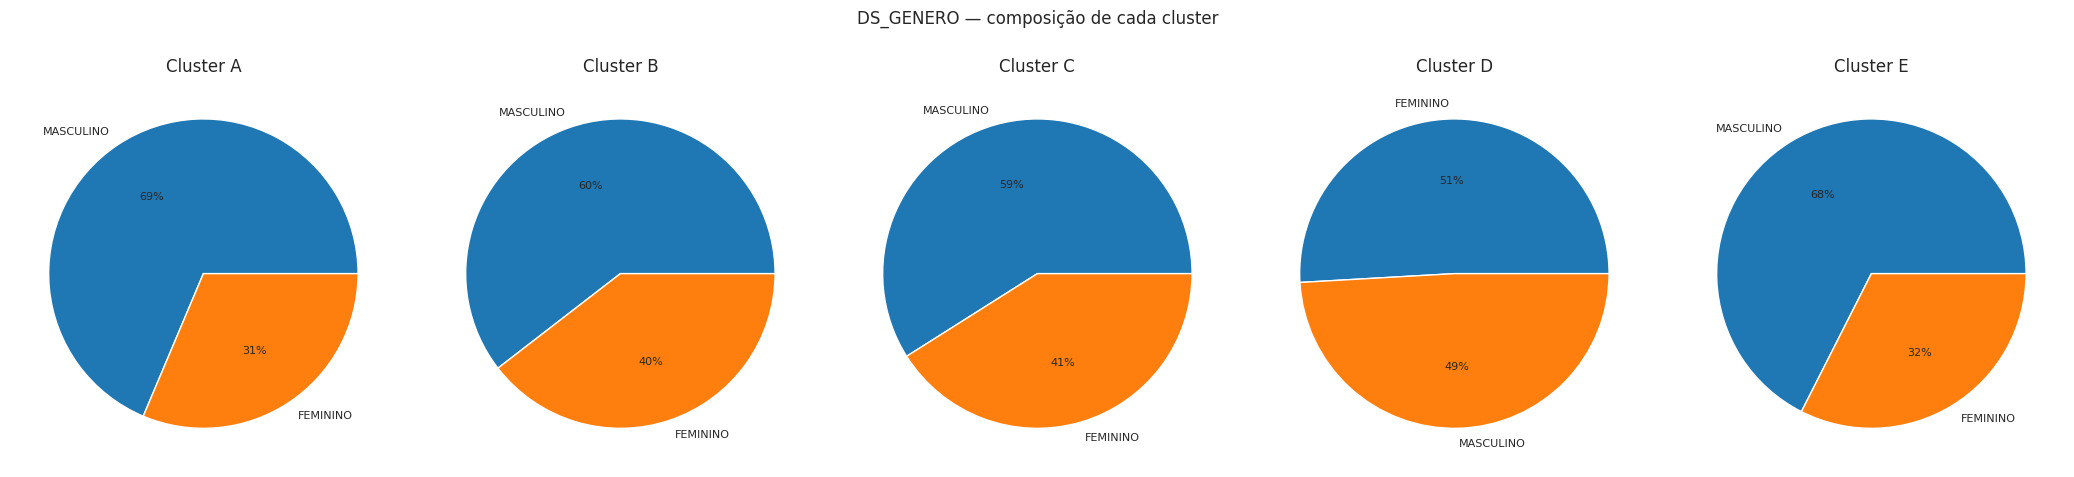

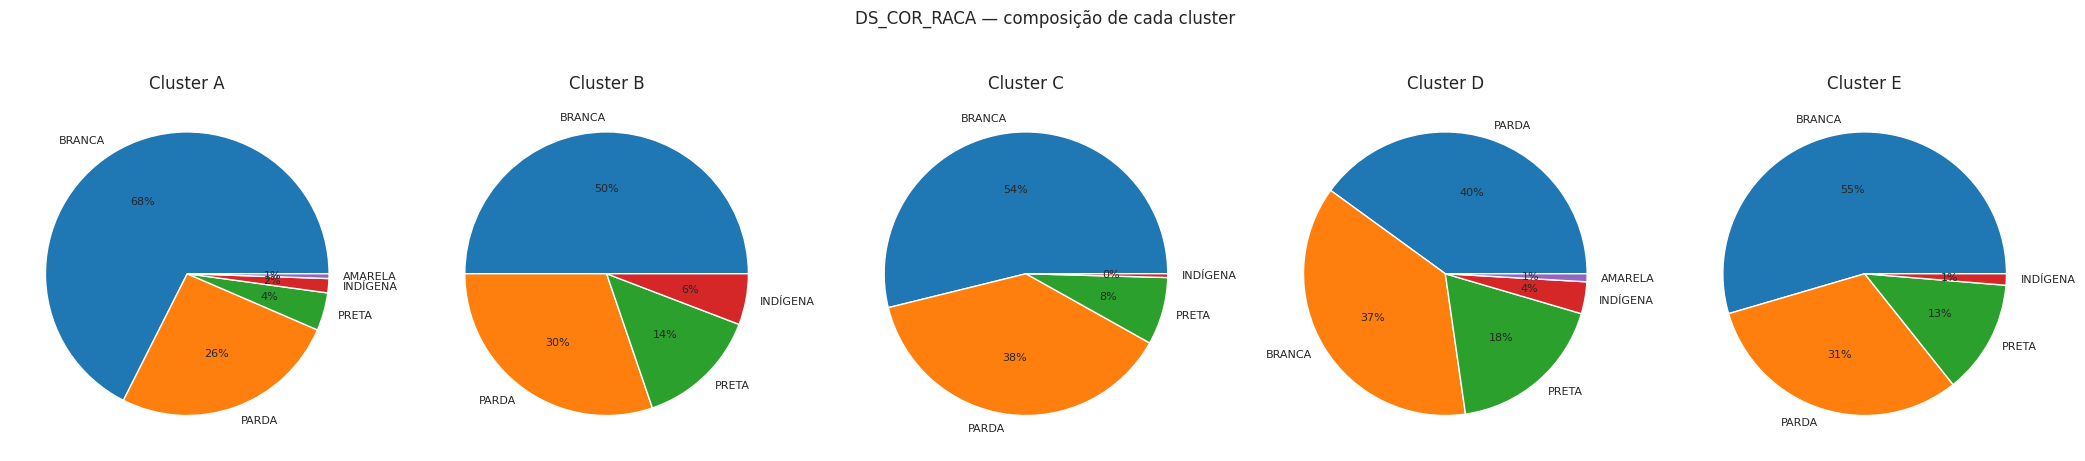

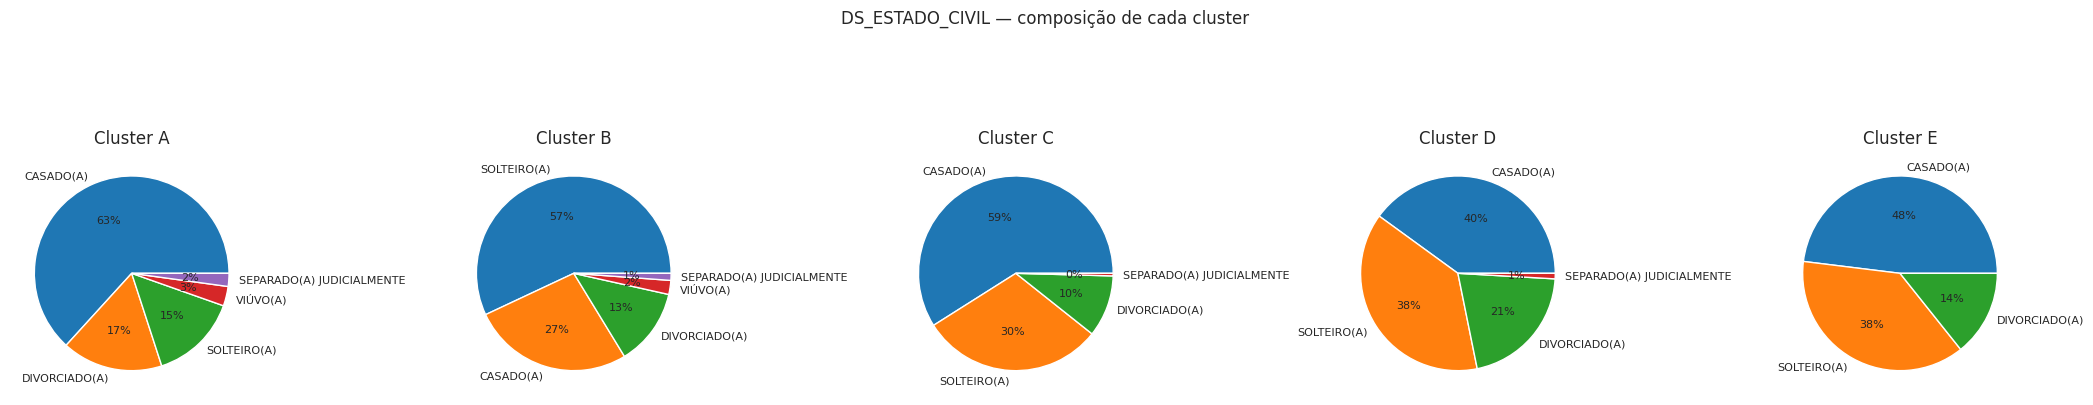

In [238]:
for col in colunas_perfil:
    fig, axes = plt.subplots(1, k_final, figsize=(4.2 * k_final, 4.5))
    if k_final == 1:
        axes = [axes]

    clusters_ordenados = sorted(df_cluster['cluster'].unique())
    for ax, cl in zip(axes, clusters_ordenados):
        contagem = df_cluster.loc[df_cluster['cluster'] == cl, col].value_counts()
        ax.pie(contagem, labels=contagem.index, autopct='%1.0f%%', textprops={'fontsize': 8})
        ax.set_title(f'Cluster {cl}')

    plt.suptitle(f'{col} — composição de cada cluster', y=1.05)
    plt.tight_layout()
    plt.show()

### Direção inversa: onde cada grupo demográfico está distribuído entre os clusters

Até aqui perguntamos "dentro do cluster X, qual a composição por gênero/cor-raça/estado civil?". Agora invertemos: **de todos os candidatos de um determinado grupo (ex.: todos os do gênero masculino), em quais clusters eles estão?** É a mesma tabela de contingência, só trocando o que normaliza — por categoria demográfica em vez de por cluster.

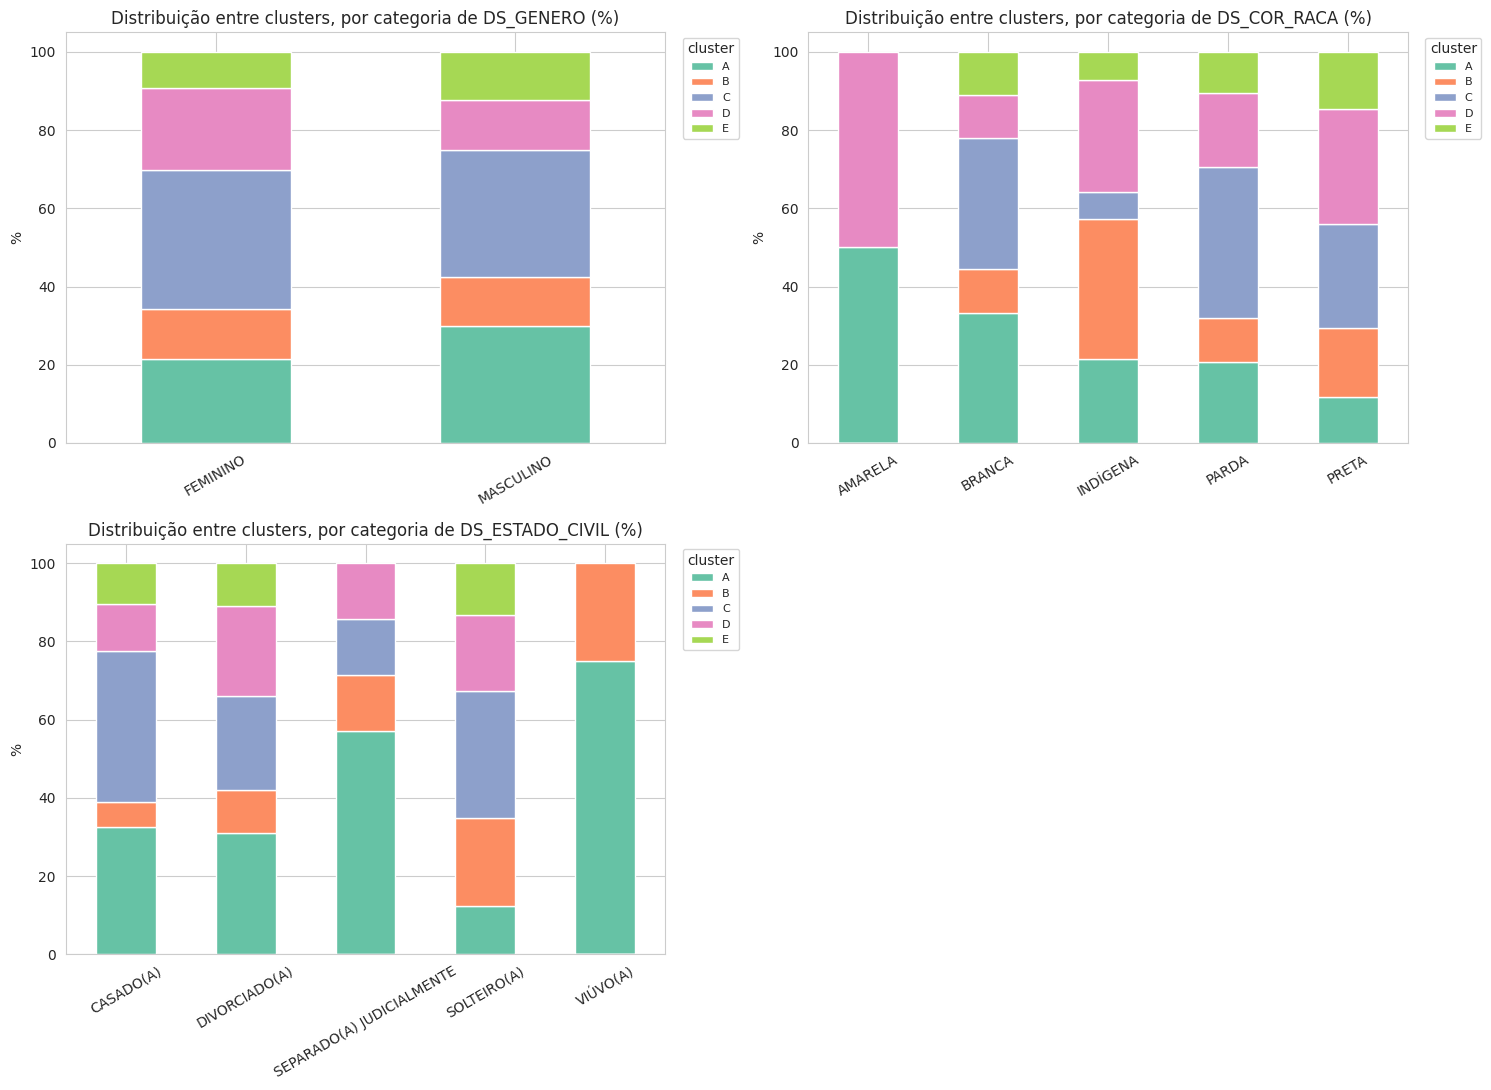

In [239]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(colunas_perfil):
    tabela = pd.crosstab(df_cluster[col], df_cluster['cluster'], normalize='index').mul(100)
    tabela = tabela[clusters_ordenados]  # garante a mesma ordem de colunas de cores_cluster
    tabela.plot(kind='bar', stacked=True, ax=axes[i], color=[cores_cluster[c] for c in tabela.columns])
    axes[i].set_title(f'Distribuição entre clusters, por categoria de {col} (%)')
    axes[i].set_ylabel('%')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].legend(title='cluster', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Comparação por UF

Esta seção roda quando o recorte contém mais de uma UF.

In [240]:
if UF is None or not isinstance(UF, str):
    composicao_uf = pd.crosstab(df_cluster['SG_UF'], df_cluster['cluster'], normalize='index').mul(100).round(1)
    display(composicao_uf)
else:
    print(f"UF = {UF!r} — seção não se aplica (dados já filtrados para uma única UF).")

cluster,A,B,C,D,E
SG_UF,,,,,
DF,31.40,13.00,29.00,17.20,9.50
GO,24.80,10.30,36.60,16.40,11.80
MS,30.10,17.10,26.80,17.10,8.90
MT,21.70,11.60,40.60,12.30,13.80


---
## Respondendo à pergunta de negócio: nomeando os clusters

Esta é a etapa mais importante de toda a análise — é aqui que o K-Means (que só enxerga números) vira uma resposta que faz sentido pra gente. Três ferramentas de apoio, dos números pro nome:

1. **Ficha técnica**: uma tabela única por cluster, juntando drivers e perfil.
2. **O que destaca cada cluster**: um heatmap mostrando só o que foge da média geral — o "diferencial" de cada grupo.
3. **Rascunho automático**: um parágrafo gerado a partir da ficha técnica, pra vocês editarem em vez de escreverem do zero.

### 1) Ficha técnica por cluster

In [241]:
ficha = df_cluster.groupby('cluster').agg(
    qtd=('SQ_CANDIDATO', 'count'),
    idade_media=('IDADE', 'mean'),
    anos_estudo_medio=('ANOS_ESTUDO', 'mean'),
    patrimonio_mediano=('Total_Bens', 'median'),
    despesas_medianas=('Total_Gasto_Campanha', 'median'),
).round(1)
ficha['pct_do_total'] = (ficha['qtd'] / ficha['qtd'].sum() * 100).round(1)

colunas_ficha = colunas_perfil + ['DS_OCUPACAO']
for col in colunas_ficha:
    ficha[f'{col}_predominante'] = df_cluster.groupby('cluster')[col].agg(lambda s: s.mode().iat[0])
    ficha[f'{col}_pct'] = df_cluster.groupby('cluster')[col].apply(
        lambda s: (s == s.mode().iat[0]).mean() * 100
    ).round(1)

ficha

,qtd,idade_media,anos_estudo_medio,patrimonio_mediano,despesas_medianas,pct_do_total,DS_GENERO_predominante,DS_GENERO_pct,DS_COR_RACA_predominante,DS_COR_RACA_pct,DS_ESTADO_CIVIL_predominante,DS_ESTADO_CIVIL_pct,DS_OCUPACAO_predominante,DS_OCUPACAO_pct
cluster,,,,,,,,,,,,,,
A,185,61.50,15.10,"912,909.10","132,480.40",26.70,MASCULINO,68.60,BRANCA,67.60,CASADO(A),63.20,ADVOGADO,10.30
B,86,43.30,11.90,0.00,0.00,12.40,MASCULINO,60.50,BRANCA,50.00,SOLTEIRO(A),57.00,OUTROS,26.70
C,234,42.10,14.90,"471,500.00","124,255.10",33.80,MASCULINO,59.00,BRANCA,53.80,CASADO(A),59.00,EMPRESÁRIO,12.80
D,110,43.80,12.90,0.00,"20,750.20",15.90,FEMININO,50.90,PARDA,40.00,CASADO(A),40.00,EMPRESÁRIO,11.80
E,77,49.90,13.60,"250,000.00",0.00,11.10,MASCULINO,67.50,BRANCA,54.50,CASADO(A),48.10,EMPRESÁRIO,16.90


### 2) O que destaca cada cluster (desvio em relação à média geral)

Quanto mais forte a cor (positiva ou negativa), mais aquele cluster se afasta da média geral de candidatos naquela variável — é isso que normalmente vira o "nome" do cluster.

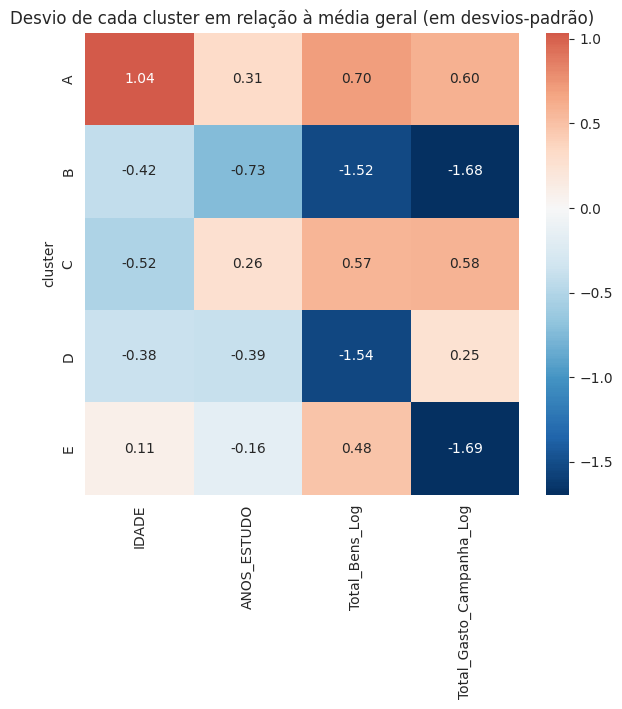

In [242]:
medias_gerais = df_cluster[colunas_driver].mean()
desvios_gerais = df_cluster[colunas_driver].std()
medias_cluster = df_cluster.groupby('cluster')[colunas_driver].mean()

zscore_cluster = (medias_cluster - medias_gerais) / desvios_gerais

plt.figure(figsize=(7, 1 + k_final))
sns.heatmap(zscore_cluster, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Desvio de cada cluster em relação à média geral (em desvios-padrão)')
plt.xlabel('')
plt.ylabel('cluster')
plt.show()

### 3) Rascunho automático — editem à vontade

In [243]:
for cl in clusters_ordenados:
    linha = ficha.loc[cl]
    print(f"Cluster {cl}  ({linha['qtd']:.0f} candidatos, {linha['pct_do_total']:.0f}% do total)")
    print(f"  Idade média: {linha['idade_media']:.0f} anos | Escolaridade média: {linha['anos_estudo_medio']:.0f} anos de estudo "
          f"| Patrimônio mediano: R$ {linha['patrimonio_mediano']:,.0f} | Despesas medianas: R$ {linha['despesas_medianas']:,.0f}")
    for col in colunas_ficha:
        print(f"  Predominância em {col}: {linha[f'{col}_predominante']} ({linha[f'{col}_pct']:.0f}%)")
    print(f"  >> Nome sugerido: _______________________")
    print()

Cluster A  (185 candidatos, 27% do total)
  Idade média: 62 anos | Escolaridade média: 15 anos de estudo | Patrimônio mediano: R$ 912,909 | Despesas medianas: R$ 132,480
  Predominância em DS_GENERO: MASCULINO (69%)
  Predominância em DS_COR_RACA: BRANCA (68%)
  Predominância em DS_ESTADO_CIVIL: CASADO(A) (63%)
  Predominância em DS_OCUPACAO: ADVOGADO (10%)
  >> Nome sugerido: _______________________

Cluster B  (86 candidatos, 12% do total)
  Idade média: 43 anos | Escolaridade média: 12 anos de estudo | Patrimônio mediano: R$ 0 | Despesas medianas: R$ 0
  Predominância em DS_GENERO: MASCULINO (60%)
  Predominância em DS_COR_RACA: BRANCA (50%)
  Predominância em DS_ESTADO_CIVIL: SOLTEIRO(A) (57%)
  Predominância em DS_OCUPACAO: OUTROS (27%)
  >> Nome sugerido: _______________________

Cluster C  (234 candidatos, 34% do total)
  Idade média: 42 anos | Escolaridade média: 15 anos de estudo | Patrimônio mediano: R$ 471,500 | Despesas medianas: R$ 124,255
  Predominância em DS_GENERO: MAS

### Nomes finais dos clusters (K-Means)

Com base nas quatro variáveis-driver e nas variáveis de perfil:

- **Cluster A:** Veteranos patrimonializados e com campanha ativa.
- **Cluster B:** Jovens com baixa estrutura declarada.
- **Cluster C:** Patrimonializados mais jovens e com campanha ativa.
- **Cluster D:** Campanha ativa sem patrimônio.
- **Cluster E:** Patrimonializados sem despesas declaradas.

---
# Parte 2 — Bisecting K-Means

**A ideia:** em vez de escolher um `k` e rodar o K-Means uma vez, o Bisecting K-Means começa com **1 cluster (todo mundo)** e vai dividindo em 2 repetidamente — a cada passo, escolhe **um** cluster já existente e o quebra em 2, aumentando `k` em 1 de cada vez (1→2→3→4→...).

O scikit-learn tem `BisectingKMeans`, mas ele só devolve o resultado final — não expõe **qual cluster foi escolhido em cada divisão**, que é exatamente o que você quer enxergar. Por isso implementamos o algoritmo manualmente aqui: a cada passo, guardamos qual cluster foi dividido, o tamanho dele e sua inércia média, o que nos dá:

1. **A árvore de divisões** — literalmente o que você pediu para enxergar.
2. **Um critério de parada visual**: enquanto o algoritmo estiver dividindo clusters **grandes**, cada divisão ainda separa bastante gente diferente — informação nova. Quando ele passa a dividir clusters **pequenos**, é sinal de que os grupos grandes e relevantes já foram encontrados, e o que resta é só "aparar as bordas". O gráfico de tamanho por nível, abaixo, mostra exatamente esse ponto de virada.

Usamos a mesma base da Versão 2 (`X`, já padronizada e sem outliers) para ficar diretamente comparável ao K-Means.

### 1) Implementação manual, guardando o histórico de divisões

In [244]:
def bisecting_kmeans_com_historico(X, k_max, criterio='inercia', random_state=SEMENTE):
    """
    Roda o Bisecting K-Means manualmente até k_max clusters, guardando o histórico
    de cada divisão (qual cluster foi escolhido, tamanho, inércia).

    criterio:
      'tamanho'  -> a cada passo, divide o cluster com MAIS pontos
      'inercia'  -> a cada passo, divide o cluster com MAIOR inércia MÉDIA (dispersão por
                    ponto, não a soma) — assim o critério não fica enviesado pra clusters
                    grandes só por terem mais pontos somando distância. Note que isso é
                    diferente do padrão do sklearn.cluster.BisectingKMeans ('biggest_inertia'),
                    que usa a soma total: a soma tende a crescer com o tamanho do cluster
                    quase por definição, então na prática quase sempre escolhe o maior
                    cluster disponível — o que não é o que queremos aqui.
    """
    def inercia(indices):
        if len(indices) < 2:
            return 0.0
        pontos = X[indices]
        centro = pontos.mean(axis=0)
        # média por ponto (não soma) — decisivo pra o critério não virar um proxy de tamanho
        return float(((pontos - centro) ** 2).sum(axis=1).mean())

    clusters = {0: np.arange(X.shape[0])}   # cluster raiz = todos os pontos
    historico = []
    proximo_id = 1

    for nivel in range(1, k_max):
        if criterio == 'tamanho':
            id_escolhido = max(clusters, key=lambda cid: len(clusters[cid]))
        else:
            id_escolhido = max(clusters, key=lambda cid: inercia(clusters[cid]))

        indices_pai = clusters[id_escolhido]
        if len(indices_pai) < 2:
            break

        km2 = KMeans(n_clusters=2, random_state=random_state, n_init=10)
        labels2 = km2.fit_predict(X[indices_pai])
        filho_a = indices_pai[labels2 == 0]
        filho_b = indices_pai[labels2 == 1]

        id_a, id_b = proximo_id, proximo_id + 1
        proximo_id += 2

        historico.append({
            'k_resultante': nivel + 1,
            'pai_id': id_escolhido, 'pai_tamanho': len(indices_pai), 'pai_inercia': inercia(indices_pai),
            'filho_a_id': id_a, 'filho_a_tamanho': len(filho_a),
            'filho_b_id': id_b, 'filho_b_tamanho': len(filho_b),
        })

        del clusters[id_escolhido]
        clusters[id_a] = filho_a
        clusters[id_b] = filho_b

    return clusters, historico

k_max_bisecting = max(faixa_k) + 1  # mesma faixa usada no K-Means (até 20)
clusters_finais, historico_bisecting = bisecting_kmeans_com_historico(X, k_max_bisecting, criterio='inercia')

print(f"Divisões realizadas: {len(historico_bisecting)}  (de k=1 até k={k_max_bisecting})")

Divisões realizadas: 19  (de k=1 até k=20)


### 2) Quando parar? Tamanho e inércia do cluster escolhido, a cada nível

Procure o ponto em que a curva despenca — é onde o algoritmo para de dividir clusters relevantes e passa a dividir sobras.

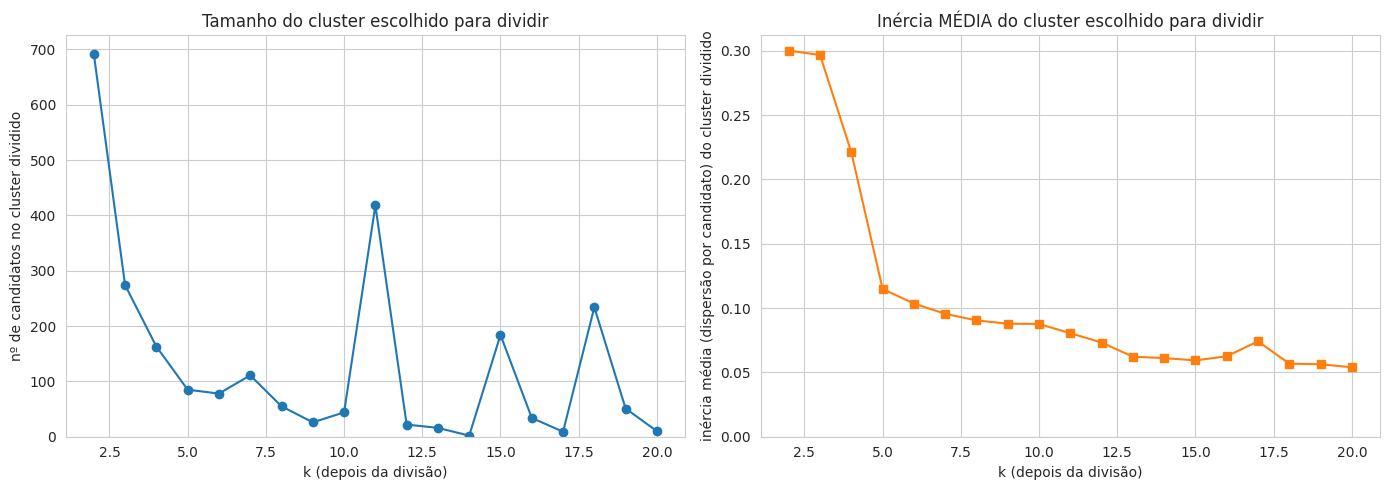

In [245]:
k_resultante = [h['k_resultante'] for h in historico_bisecting]
tamanho_escolhido = [h['pai_tamanho'] for h in historico_bisecting]
inercia_escolhida = [h['pai_inercia'] for h in historico_bisecting]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_resultante, tamanho_escolhido, marker='o')
axes[0].set_title('Tamanho do cluster escolhido para dividir')
axes[0].set_xlabel('k (depois da divisão)')
axes[0].set_ylabel('nº de candidatos no cluster dividido')
axes[0].set_ylim(bottom=0)
axes[0].grid(True)

axes[1].plot(k_resultante, inercia_escolhida, marker='s', color='tab:orange')
axes[1].set_title('Inércia MÉDIA do cluster escolhido para dividir')
axes[1].set_xlabel('k (depois da divisão)')
axes[1].set_ylabel('inércia média (dispersão por candidato) do cluster dividido')
axes[1].set_ylim(bottom=0)
axes[1].grid(True)

plt.tight_layout()
plt.show()

### 3) A árvore de divisões

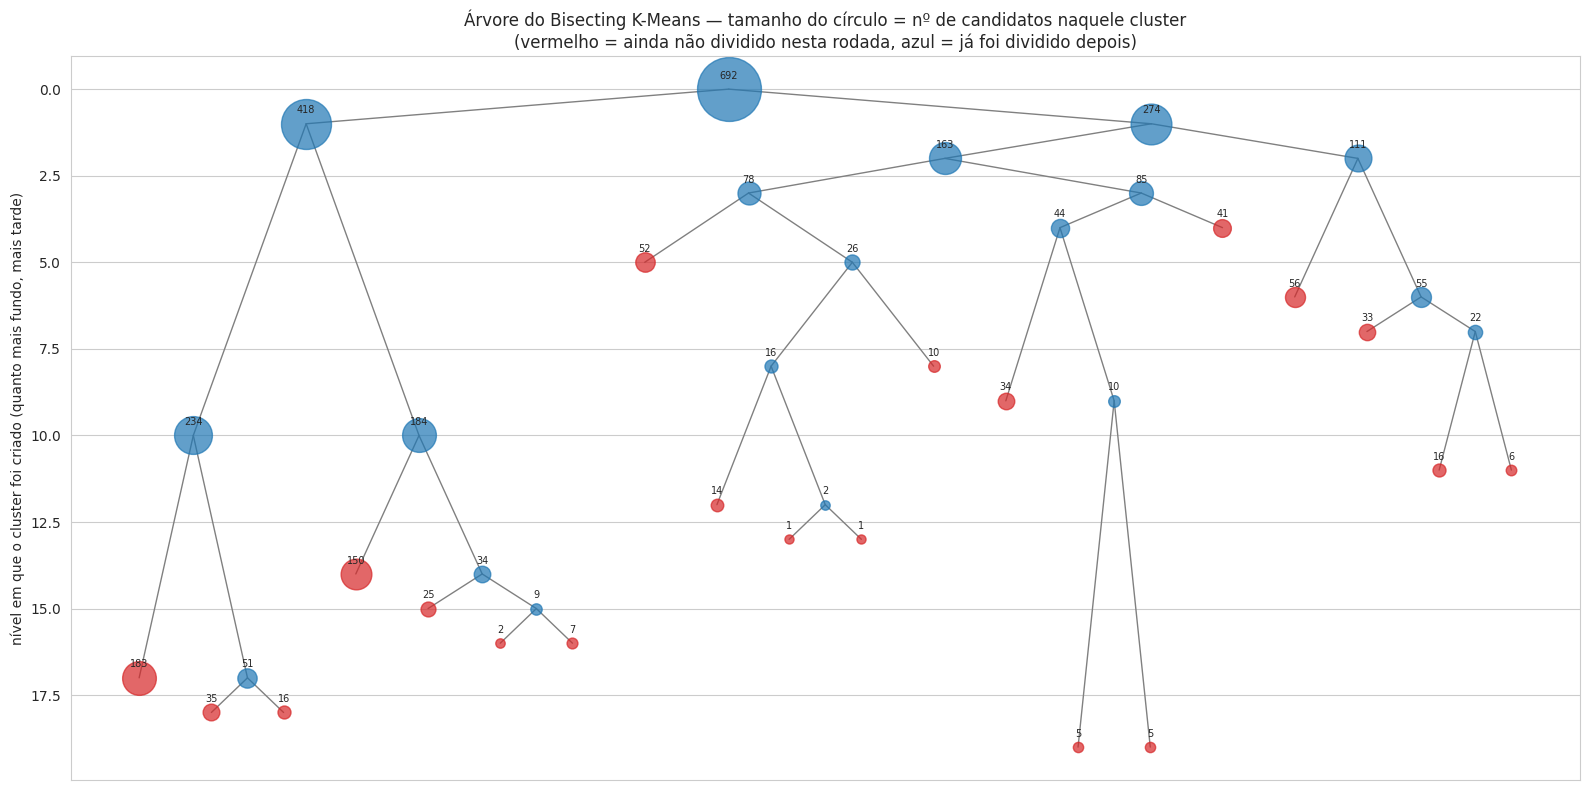

In [246]:
nos = {0: {'pai': None, 'nivel': 0, 'tamanho': X.shape[0], 'filhos': None}}
for h in historico_bisecting:
    nos[h['pai_id']]['filhos'] = [h['filho_a_id'], h['filho_b_id']]
    nos[h['filho_a_id']] = {'pai': h['pai_id'], 'nivel': h['k_resultante'] - 1, 'tamanho': h['filho_a_tamanho'], 'filhos': None}
    nos[h['filho_b_id']] = {'pai': h['pai_id'], 'nivel': h['k_resultante'] - 1, 'tamanho': h['filho_b_tamanho'], 'filhos': None}

# posição horizontal: folhas em ordem, nós internos = média dos filhos (layout clássico de árvore)
posicoes = {}
_x = [0]

def atribuir_x(no_id):
    filhos = nos[no_id]['filhos']
    if filhos is None:
        posicoes[no_id] = _x[0]
        _x[0] += 1
    else:
        for f in filhos:
            atribuir_x(f)
        posicoes[no_id] = sum(posicoes[f] for f in filhos) / len(filhos)

atribuir_x(0)

plt.figure(figsize=(16, 8))
for no_id, info in nos.items():
    if info['filhos']:
        for f in info['filhos']:
            plt.plot([posicoes[no_id], posicoes[f]], [info['nivel'], nos[f]['nivel']],
                      color='gray', linewidth=1, zorder=1)

for no_id, info in nos.items():
    e_folha = info['filhos'] is None
    plt.scatter(posicoes[no_id], info['nivel'], s=40 + info['tamanho'] * 3,
                color='tab:red' if e_folha else 'tab:blue', alpha=0.7, zorder=2)
    plt.text(posicoes[no_id], info['nivel'] - 0.3, str(info['tamanho']), ha='center', fontsize=7)

plt.gca().invert_yaxis()
plt.ylabel('nível em que o cluster foi criado (quanto mais fundo, mais tarde)')
plt.xticks([])
plt.title('Árvore do Bisecting K-Means — tamanho do círculo = nº de candidatos naquele cluster\n(vermelho = ainda não dividido nesta rodada, azul = já foi dividido depois)')
plt.tight_layout()
plt.show()

### 3.1) Animação: a árvore crescendo, nível a nível

A árvore estática fica poluída com muitos níveis de uma vez. Esta animação mostra **a mesma árvore**, mas revelando um nível por vez — a cada frame, um nó vermelho (folha ainda não dividida) "explode" em dois, e vira azul. As posições dos nós são as mesmas da árvore estática (calculadas uma vez só), então nada pula de lugar entre frames — só aparece o que é novo.

In [247]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

historico_por_k = {h['k_resultante']: h for h in historico_bisecting}
ks_disponiveis = list(range(1, max(historico_por_k) + 1))

def estado_arvore_no_k(k):
    """Quais nós já existem, e quais deles ainda são folha (não foram divididos), no frame k."""
    existentes = [nid for nid, info in nos.items() if info['nivel'] <= k - 1]
    set_existentes = set(existentes)
    folhas = []
    for nid in existentes:
        filhos = nos[nid]['filhos']
        if filhos is None or filhos[0] not in set_existentes:
            folhas.append(nid)
    return existentes, set(folhas)

max_nivel = max(info['nivel'] for info in nos.values())
x_min, x_max = min(posicoes.values()), max(posicoes.values())

fig, ax = plt.subplots(figsize=(16, 8))

def desenhar_frame_arvore(k):
    ax.clear()
    existentes, folhas = estado_arvore_no_k(k)
    set_existentes = set(existentes)

    for nid in existentes:
        filhos = nos[nid]['filhos']
        if filhos:
            for f in filhos:
                if f in set_existentes:
                    ax.plot([posicoes[nid], posicoes[f]], [nos[nid]['nivel'], nos[f]['nivel']],
                            color='gray', linewidth=1, zorder=1)

    for nid in existentes:
        info = nos[nid]
        cor = 'tab:red' if nid in folhas else 'tab:blue'
        ax.scatter(posicoes[nid], info['nivel'], s=40 + info['tamanho'] * 3, color=cor, alpha=0.7, zorder=2)
        ax.text(posicoes[nid], info['nivel'] - 0.3, str(info['tamanho']), ha='center', fontsize=7)

    ax.set_xlim(x_min - 1, x_max + 1)
    ax.set_ylim(max_nivel + 1, -1)  # eixo fixo e invertido (raiz no topo), sem "pulos" entre frames
    ax.set_xticks([])
    ax.set_ylabel('nível em que o cluster foi criado')
    if k in historico_por_k:
        h = historico_por_k[k]
        ax.set_title(f'Árvore do Bisecting K-Means — k={k}  (dividiu um cluster de {h["pai_tamanho"]} candidatos)')
    else:
        ax.set_title(f'Árvore do Bisecting K-Means — k={k} (estado inicial, 1 cluster só)')

anim = FuncAnimation(fig, desenhar_frame_arvore, frames=ks_disponiveis, interval=800, repeat=True)
plt.close(fig)  # evita mostrar também uma figura estática duplicada, além da animação
HTML(anim.to_jshtml())

> Se a animação demorar pra renderizar (muitos frames), aumente `interval` (ela roda mais devagar) ou reduza `k_max_bisecting` mais acima. Pra usar fora do notebook (ex.: num slide): `anim.save('arvore_bisecting.gif', writer='pillow')`.

### 4) Explorando diferentes k, na prática

Antes de fechar num único `k`, vale ver como os clusters realmente mudam à medida que o Bisecting K-Means continua dividindo — os dois gráficos anteriores (tamanho/inércia por nível, e a árvore) só sugerem isso de forma indireta. Reconstruímos a partição em `k=2, 3, 4` e `5`, mostrando a ficha resumida e o radar (reaproveitando a mesma `plot_radar` da Parte 1) de cada uma.

Como o Bisecting K-Means não calcula um centróide final único (ele só guarda os centros de cada divisão de 2 em 2, não da partição completa em k clusters), usamos a média das variáveis-driver padronizadas dentro de cada cluster como "centróide de fato" para o radar — mesma ideia de sempre.


--- Bisecting K-Means, k=2 ---


,qtd_candidatos,idade_media,anos_estudo_medio,patrimonio_mediano,despesas_medianas
cluster,,,,,
A,418,50.70,15.00,"643,810.20","127,893.00"
B,274,45.40,12.80,0.00,0.00


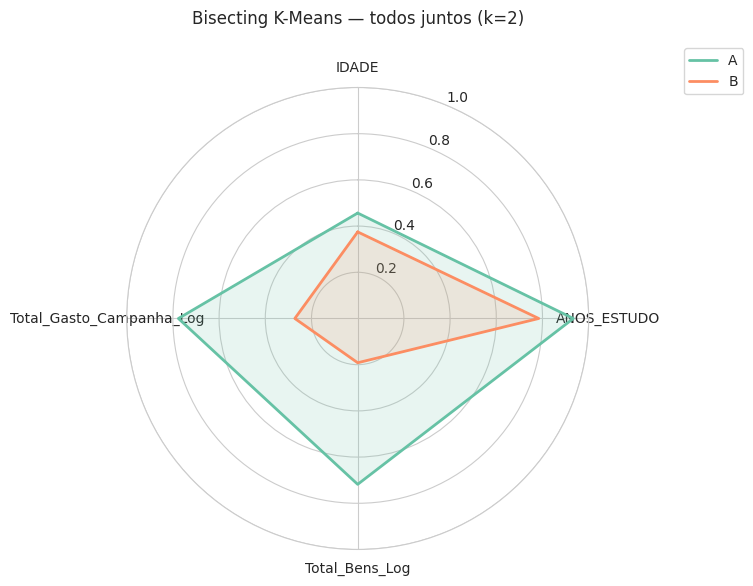

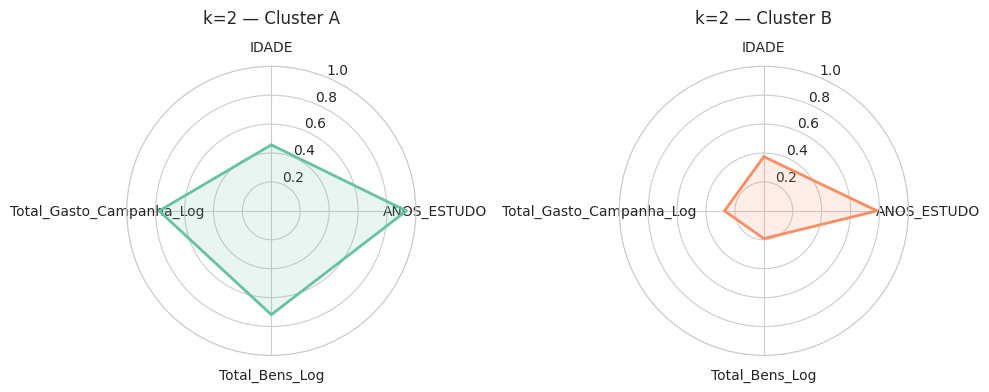

--- Bisecting K-Means, k=3 ---


,qtd_candidatos,idade_media,anos_estudo_medio,patrimonio_mediano,despesas_medianas
cluster,,,,,
A,418,50.70,15.00,"643,810.20","127,893.00"
B,163,46.50,12.60,0.00,0.00
C,111,43.70,12.90,0.00,"20,000.00"


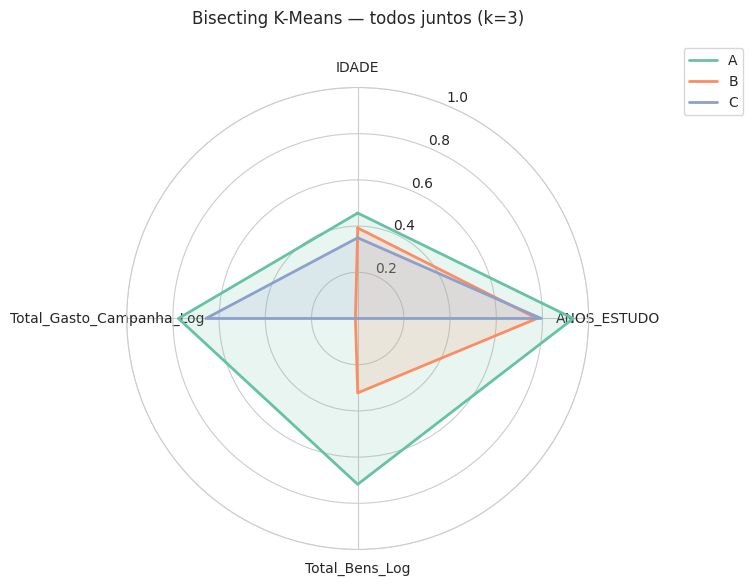

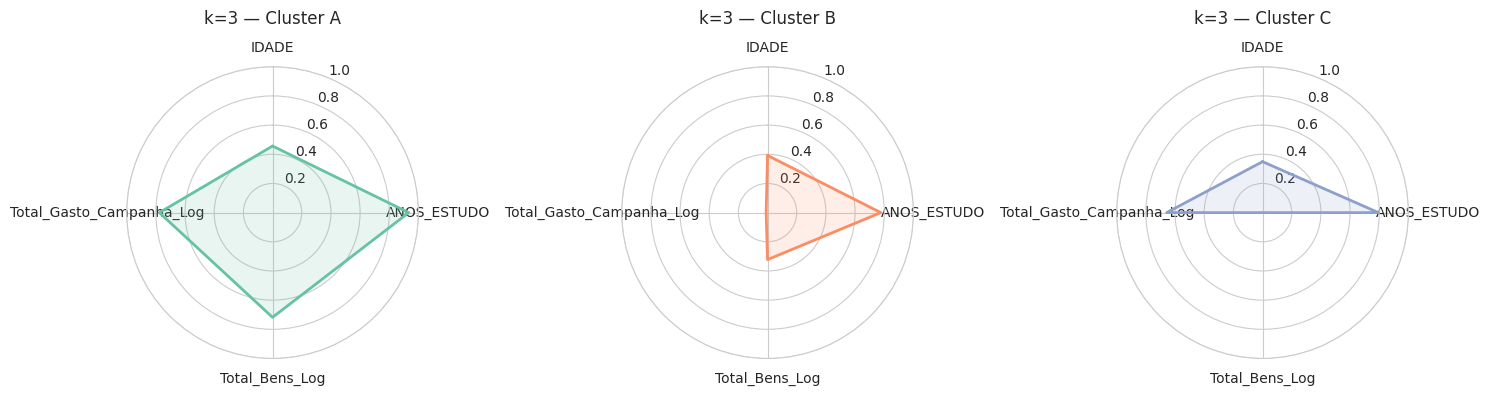

--- Bisecting K-Means, k=4 ---


,qtd_candidatos,idade_media,anos_estudo_medio,patrimonio_mediano,despesas_medianas
cluster,,,,,
A,418,50.70,15.00,"643,810.20","127,893.00"
B,111,43.70,12.90,0.00,"20,000.00"
C,85,43.40,11.90,0.00,0.00
D,78,49.80,13.40,"203,000.00",0.00


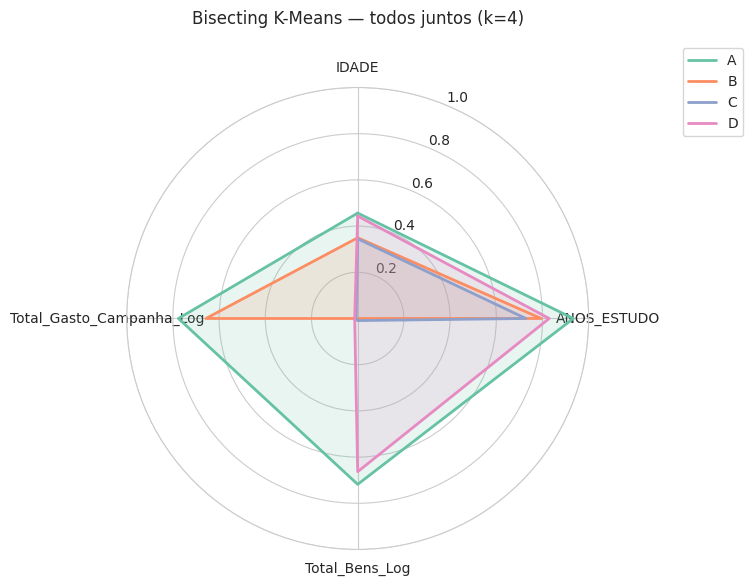

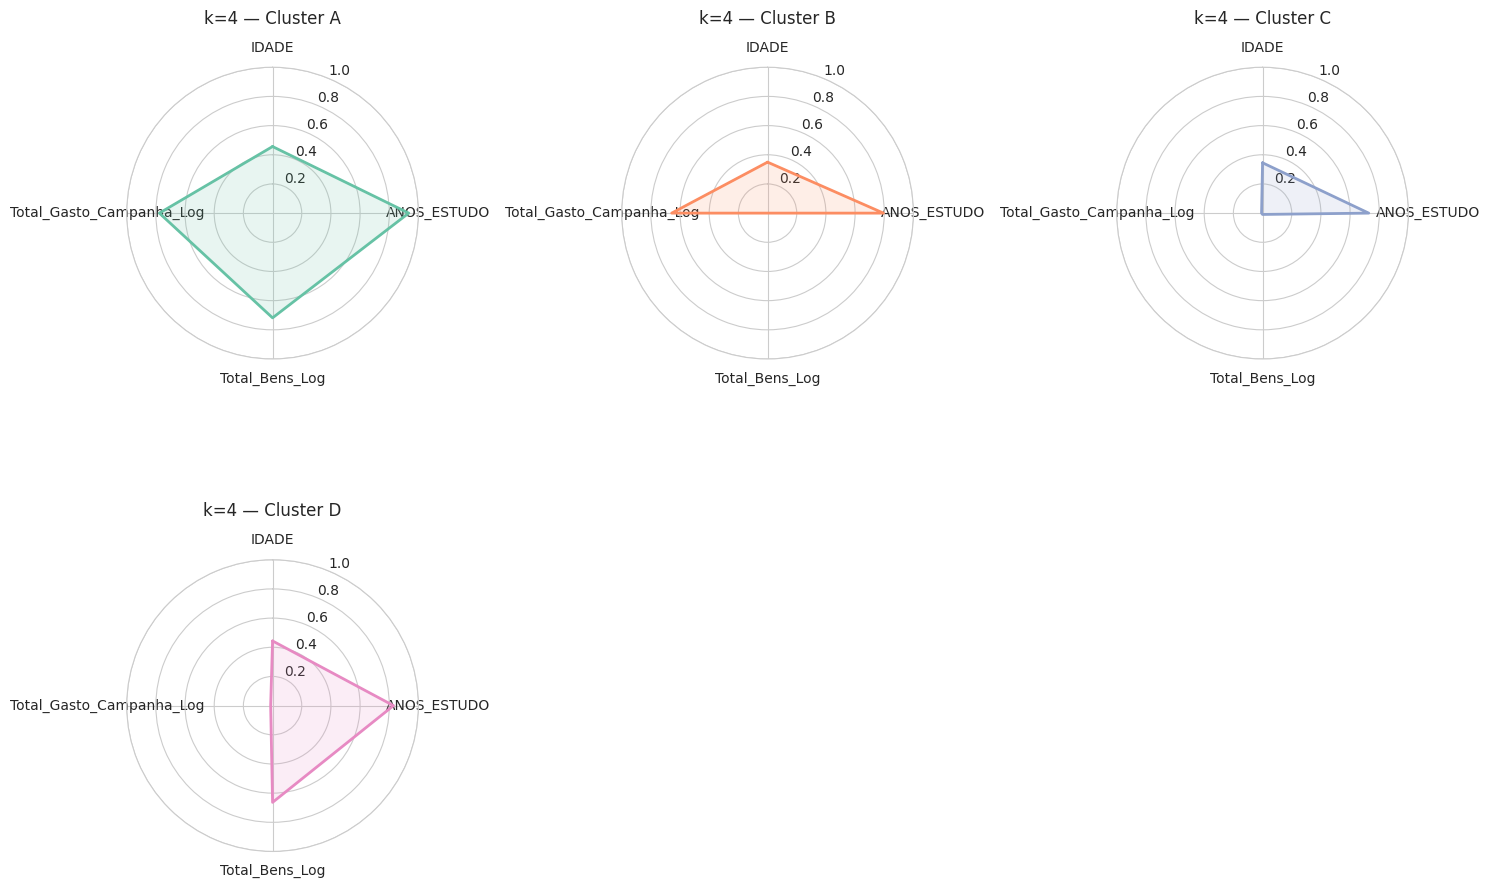

--- Bisecting K-Means, k=5 ---


,qtd_candidatos,idade_media,anos_estudo_medio,patrimonio_mediano,despesas_medianas
cluster,,,,,
A,418,50.70,15.00,"643,810.20","127,893.00"
B,111,43.70,12.90,0.00,"20,000.00"
C,78,49.80,13.40,"203,000.00",0.00
D,44,37.10,9.30,0.00,0.00
E,41,50.20,14.80,0.00,0.00


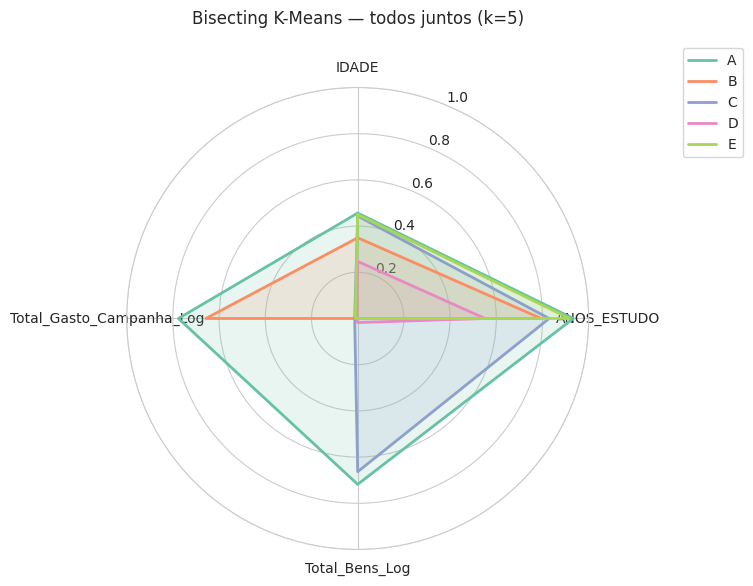

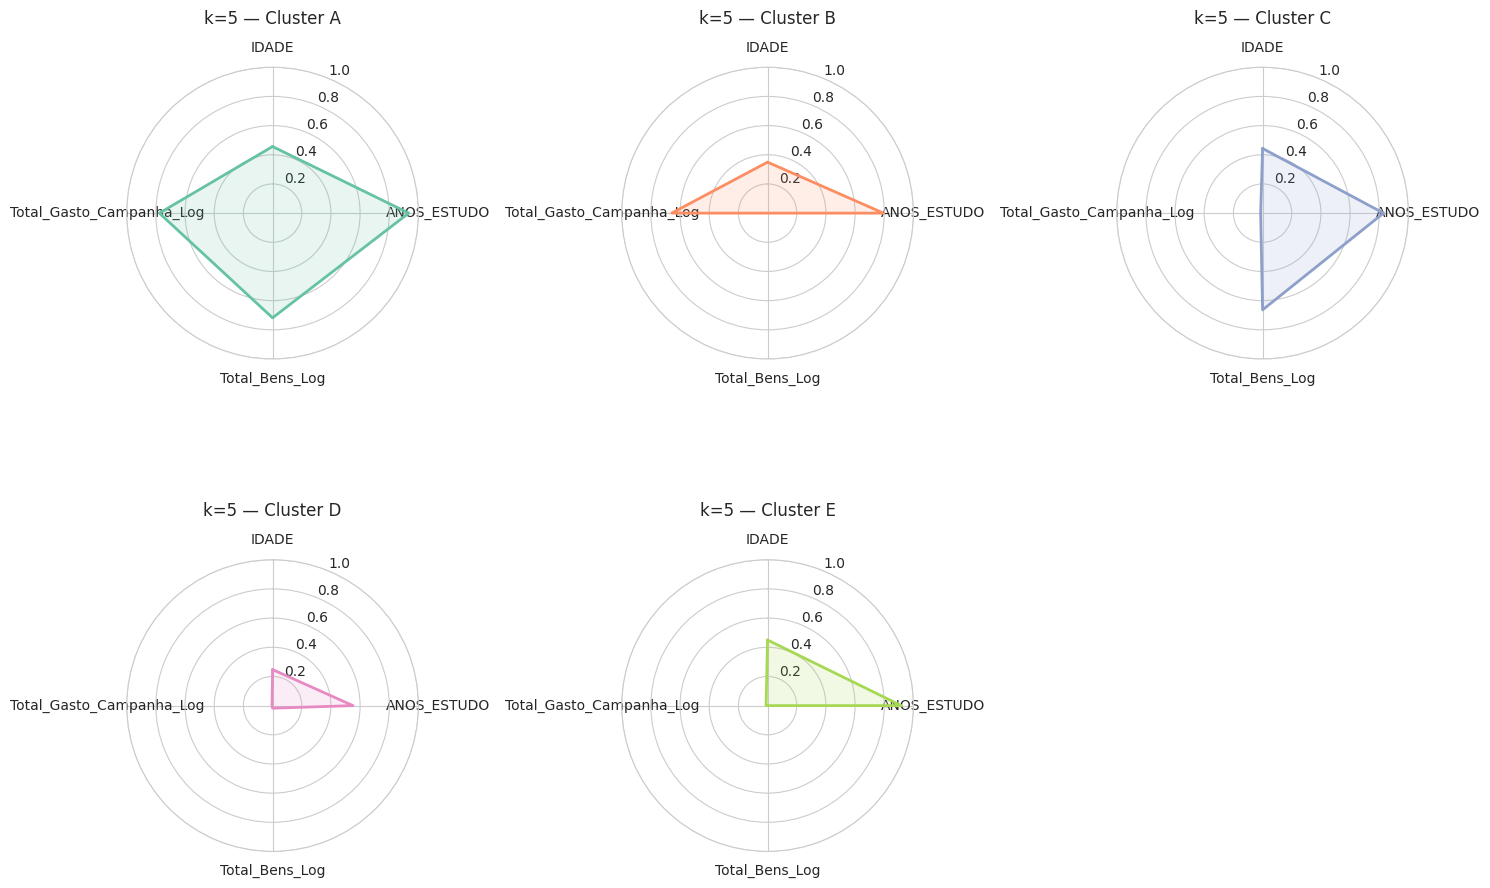

In [248]:
def clusters_bisecting_em_k(k):
    """Reconstrói a partição do Bisecting K-Means em k clusters, refazendo as divisões
    do histórico até esse ponto. Refazer o KMeans(n_clusters=2) é determinístico (mesma
    SEMENTE, mesmos dados de entrada), então reproduz exatamente a divisão já registrada —
    sem precisar guardar todos os índices no histórico."""
    clusters_no_k = {0: np.arange(X.shape[0])}
    for h in historico_bisecting:
        if h['k_resultante'] > k:
            break
        indices_pai = clusters_no_k.pop(h['pai_id'])
        km2 = KMeans(n_clusters=2, random_state=SEMENTE, n_init=10)
        labels2 = km2.fit_predict(X[indices_pai])
        clusters_no_k[h['filho_a_id']] = indices_pai[labels2 == 0]
        clusters_no_k[h['filho_b_id']] = indices_pai[labels2 == 1]

    # rótulos por ordem de tamanho (A = maior cluster, ...), mesma convenção usada em todo o notebook
    ids_por_tamanho = sorted(clusters_no_k, key=lambda cid: len(clusters_no_k[cid]), reverse=True)
    rotulos = np.empty(X.shape[0], dtype=object)
    for letra, cid in zip([chr(65 + i) for i in range(len(ids_por_tamanho))], ids_por_tamanho):
        rotulos[clusters_no_k[cid]] = letra
    return rotulos


for k in [2, 3, 4, 5]:
    rotulos_k = clusters_bisecting_em_k(k)
    clusters_k = sorted(set(rotulos_k))
    cores_k = dict(zip(clusters_k, sns.color_palette('Set2', n_colors=k)))

    print(f"--- Bisecting K-Means, k={k} ---")
    resumo_k = pd.DataFrame({
        'cluster': rotulos_k,
        'IDADE': df_cluster['IDADE'].values,
        'ANOS_ESTUDO': df_cluster['ANOS_ESTUDO'].values,
        'Total_Bens': df_cluster['Total_Bens'].values,
        'Total_Gasto_Campanha': df_cluster['Total_Gasto_Campanha'].values,
    }).groupby('cluster').agg(
        qtd_candidatos=('IDADE', 'count'),
        idade_media=('IDADE', 'mean'),
        anos_estudo_medio=('ANOS_ESTUDO', 'mean'),
        patrimonio_mediano=('Total_Bens', 'median'),
        despesas_medianas=('Total_Gasto_Campanha', 'median'),
    ).round(1)
    display(resumo_k)

    # "centróide" = média de cada cluster nas variáveis-driver padronizadas (ver explicação acima)
    centroides_k_norm = np.array([X[rotulos_k == cl].mean(axis=0) for cl in clusters_k])

    fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
    plot_radar(ax, centroides_k_norm, colunas_driver, clusters_k, cores_k, f'Bisecting K-Means — todos juntos (k={k})')
    ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))
    plt.show()

    ncols = min(k, 3)
    nrows = -(-k // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), subplot_kw=dict(polar=True))
    axes = axes.flatten() if k > 1 else [axes]
    for i, cl in enumerate(clusters_k):
        plot_radar(axes[i], [centroides_k_norm[i]], colunas_driver, [cl], cores_k, f'k={k} — Cluster {cl}')
    for j in range(len(clusters_k), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


### 5) Escolhendo k final e extraindo o resultado

Com base no gráfico de tamanho/inércia, na árvore e na exploração de `k=2` a `5`, fixamos **k=5**. A silhouette cresce de 0,457 (k=2) para 0,483 (k=3), atinge 0,511 em k=4 e permanece próxima em k=5 (0,488). O quinto corte também produz uma distinção interpretável dentro do grupo de baixa estrutura: candidatos mais jovens e menos escolarizados são separados dos mais velhos e escolarizados. Assim, aceitamos a pequena redução da silhouette em troca de um perfil adicional substantivamente útil.


In [249]:
k_bisecting = K_BISECTING

df_cluster['cluster_bisecting'] = clusters_bisecting_em_k(k_bisecting)
df_cluster['cluster_bisecting'].value_counts().sort_index()


,count
cluster_bisecting,
A,418
B,111
C,78
D,44
E,41


### 6) Comparando com o K-Means (Versão 2)

Silhouette — K-Means (V2, k=5):        0.348
Silhouette — Bisecting K-Means (k=5): 0.488


,qtd_candidatos,idade_media,anos_estudo_medio,patrimonio_mediano,despesas_medianas
cluster_bisecting,,,,,
A,418,50.70,15.00,"643,810.20","127,893.00"
B,111,43.70,12.90,0.00,"20,000.00"
C,78,49.80,13.40,"203,000.00",0.00
D,44,37.10,9.30,0.00,0.00
E,41,50.20,14.80,0.00,0.00


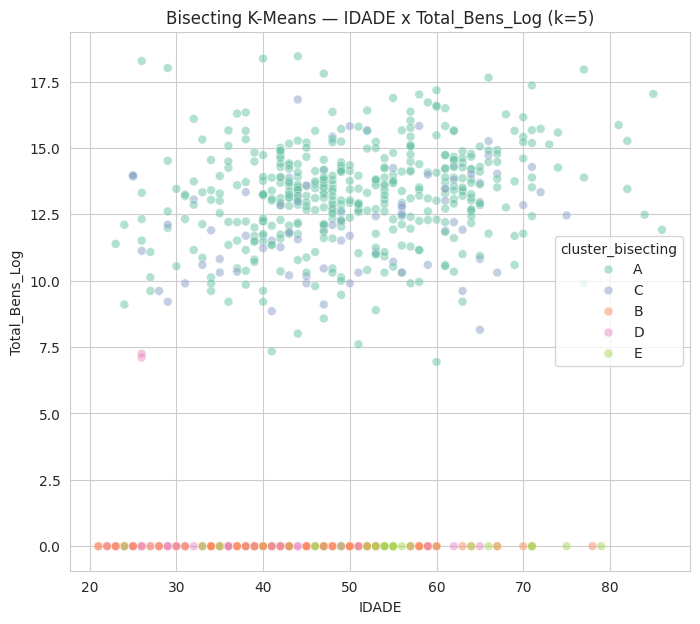

In [250]:
labels_bisecting = df_cluster['cluster_bisecting'].values
print(f"Silhouette — K-Means (V2, k={k_final}):        {silhouette_score(X, df_cluster['cluster']):.3f}")
print(f"Silhouette — Bisecting K-Means (k={k_bisecting}): {silhouette_score(X, labels_bisecting):.3f}")

resumo_bisecting = df_cluster.groupby('cluster_bisecting').agg(
    qtd_candidatos=('SQ_CANDIDATO', 'count'),
    idade_media=('IDADE', 'mean'),
    anos_estudo_medio=('ANOS_ESTUDO', 'mean'),
    patrimonio_mediano=('Total_Bens', 'median'),
    despesas_medianas=('Total_Gasto_Campanha', 'median'),
).round(1)
display(resumo_bisecting)

clusters_bisecting_ordenados = sorted(df_cluster['cluster_bisecting'].unique())
cores_bisecting = dict(zip(clusters_bisecting_ordenados, sns.color_palette('Set2', n_colors=len(clusters_bisecting_ordenados))))

plt.figure(figsize=(8, 7))
sns.scatterplot(data=df_cluster, x='IDADE', y='Total_Bens_Log', hue='cluster_bisecting', palette=cores_bisecting, alpha=0.5, s=40)
plt.title(f'Bisecting K-Means — IDADE x Total_Bens_Log (k={k_bisecting})')
plt.show()

**Interpretação:** compare o `resumo_bisecting` com o `resumo_driver` do K-Means e a silhouette dos dois. Se os grupos ficarem parecidos, é um bom sinal de que a estrutura é real (dois algoritmos diferentes concordando); se ficarem bem diferentes, vale a pena entender por quê — o K-Means busca uma solução global pra todo o `k` de uma vez, enquanto o Bisecting constrói de forma incremental, e pode ficar "preso" a decisões tomadas em níveis anteriores.

Agora aplicamos de verdade o mesmo kit de nomeação da Parte 1 (ficha técnica, heatmap de desvio, rascunho automático) para os clusters do Bisecting — e ampliamos a leitura demográfica com partido e UF, que a Parte 1 não cobriu.


### 7) Ficha técnica por cluster (Bisecting K-Means)


In [251]:
ficha_bisecting = df_cluster.groupby('cluster_bisecting').agg(
    qtd=('SQ_CANDIDATO', 'count'),
    idade_media=('IDADE', 'mean'),
    anos_estudo_medio=('ANOS_ESTUDO', 'mean'),
    patrimonio_medio=('Total_Bens', 'mean'),
    patrimonio_mediano=('Total_Bens', 'median'),
    despesas_medianas=('Total_Gasto_Campanha', 'median'),
).round(1)
ficha_bisecting['pct_do_total'] = (ficha_bisecting['qtd'] / ficha_bisecting['qtd'].sum() * 100).round(1)
ficha_bisecting['pct_sem_bens'] = df_cluster.groupby('cluster_bisecting')['Total_Bens'].apply(
    lambda s: (s == 0).mean() * 100
).round(1)
ficha_bisecting['pct_sem_despesas'] = df_cluster.groupby('cluster_bisecting')['Total_Gasto_Campanha'].apply(
    lambda s: (s == 0).mean() * 100
).round(1)

for col in colunas_ficha:
    ficha_bisecting[f'{col}_predominante'] = df_cluster.groupby('cluster_bisecting')[col].agg(lambda s: s.mode().iat[0])
    ficha_bisecting[f'{col}_pct'] = df_cluster.groupby('cluster_bisecting')[col].apply(
        lambda s: (s == s.mode().iat[0]).mean() * 100
    ).round(1)

ficha_bisecting


,qtd,idade_media,anos_estudo_medio,patrimonio_medio,patrimonio_mediano,despesas_medianas,pct_do_total,pct_sem_bens,pct_sem_despesas,DS_GENERO_predominante,DS_GENERO_pct,DS_COR_RACA_predominante,DS_COR_RACA_pct,DS_ESTADO_CIVIL_predominante,DS_ESTADO_CIVIL_pct,DS_OCUPACAO_predominante,DS_OCUPACAO_pct
cluster_bisecting,,,,,,,,,,,,,,,,,
A,418,50.70,15.00,"3,039,491.90","643,810.20","127,893.00",60.40,0.00,0.00,MASCULINO,63.20,BRANCA,60.00,CASADO(A),61.00,EMPRESÁRIO,11.50
B,111,43.70,12.90,0.00,0.00,"20,000.00",16.00,100.00,0.00,FEMININO,50.50,PARDA,39.60,CASADO(A),40.50,EMPRESÁRIO,11.70
C,78,49.80,13.40,"1,024,180.80","203,000.00",0.00,11.30,0.00,96.20,MASCULINO,67.90,BRANCA,53.80,CASADO(A),47.40,EMPRESÁRIO,16.70
D,44,37.10,9.30,59.70,0.00,0.00,6.40,95.50,95.50,FEMININO,54.50,PARDA,45.50,SOLTEIRO(A),77.30,OUTROS,40.90
E,41,50.20,14.80,0.00,0.00,0.00,5.90,100.00,95.10,MASCULINO,75.60,BRANCA,68.30,CASADO(A),36.60,EMPRESÁRIO,14.60


### 8) O que destaca cada cluster (desvio em relação à média geral)


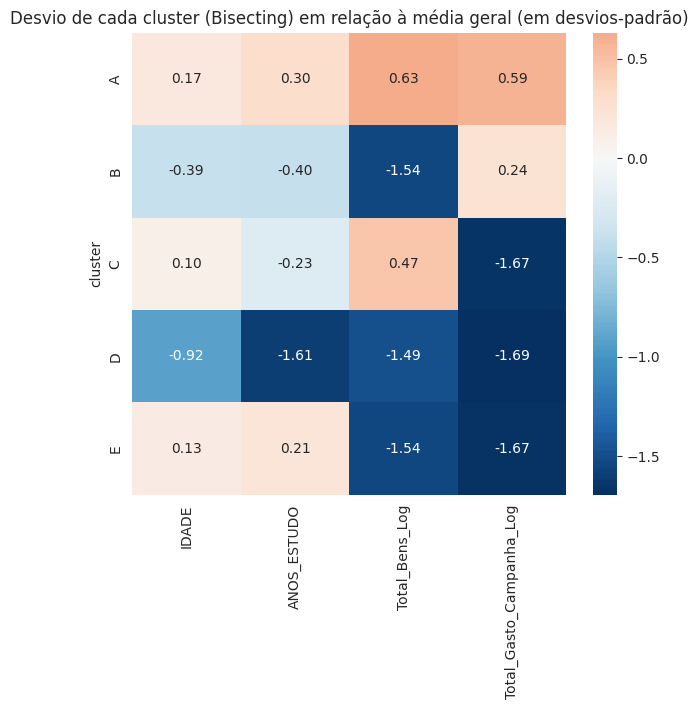

In [252]:
medias_cluster_bisecting = df_cluster.groupby('cluster_bisecting')[colunas_driver].mean()
zscore_cluster_bisecting = (medias_cluster_bisecting - medias_gerais) / desvios_gerais

plt.figure(figsize=(7, 1 + k_bisecting))
sns.heatmap(zscore_cluster_bisecting, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Desvio de cada cluster (Bisecting) em relação à média geral (em desvios-padrão)')
plt.xlabel('')
plt.ylabel('cluster')
plt.show()


In [253]:
NOMES_CLUSTER_BISECTING = {
    'A': 'Patrimonializados, escolarizados e com campanha ativa',
    # 418 candidatos (60,4%). Maior patrimônio e despesas elevadas, 15 anos médios de estudo e idade média de 50,7 anos.
    'B': 'Campanha ativa sem patrimônio',
    # 111 candidatos (16%). Todos sem bens declarados, mas todos com despesas de campanha. Gênero praticamente equilibrado.
    'C': 'Patrimonializados sem despesas declaradas',
    # 78 candidatos (11,3%). Patrimônio mediano de R$ 203 mil, mas 96,2% sem despesas no snapshot.
    'D': 'Jovens com baixa estrutura declarada',
    # 44 candidatos (6,4%). Grupo mais jovem, menor escolaridade, 95,5% sem bens e sem despesas. Predominantemente solteiros, pardos e ligeiramente feminino.
    'E': 'Escolarizados sem bens nem despesas'
    # 41 candidatos (5,9%). Mais velhos e escolarizados que o Cluster D, mas 100% sem patrimônio e 95,1% sem despesas. Predominantemente masculino e branco.
}
df_cluster['nome_cluster_bisecting'] = df_cluster['cluster_bisecting'].map(NOMES_CLUSTER_BISECTING)
df_cluster[['cluster_bisecting', 'nome_cluster_bisecting']].value_counts().sort_index()

,,count
cluster_bisecting,nome_cluster_bisecting,
A,"Patrimonializados, escolarizados e com campanha ativa",418
B,Campanha ativa sem patrimônio,111
C,Patrimonializados sem despesas declaradas,78
D,Jovens com baixa estrutura declarada,44
E,Escolarizados sem bens nem despesas,41


In [254]:
nomes_bisecting_ordenados = [NOMES_CLUSTER_BISECTING[c] for c in clusters_bisecting_ordenados]
cores_nome_bisecting = {NOMES_CLUSTER_BISECTING[c]: cor for c, cor in cores_bisecting.items()}


### 9) Composição demográfica: gênero, cor/raça, estado civil


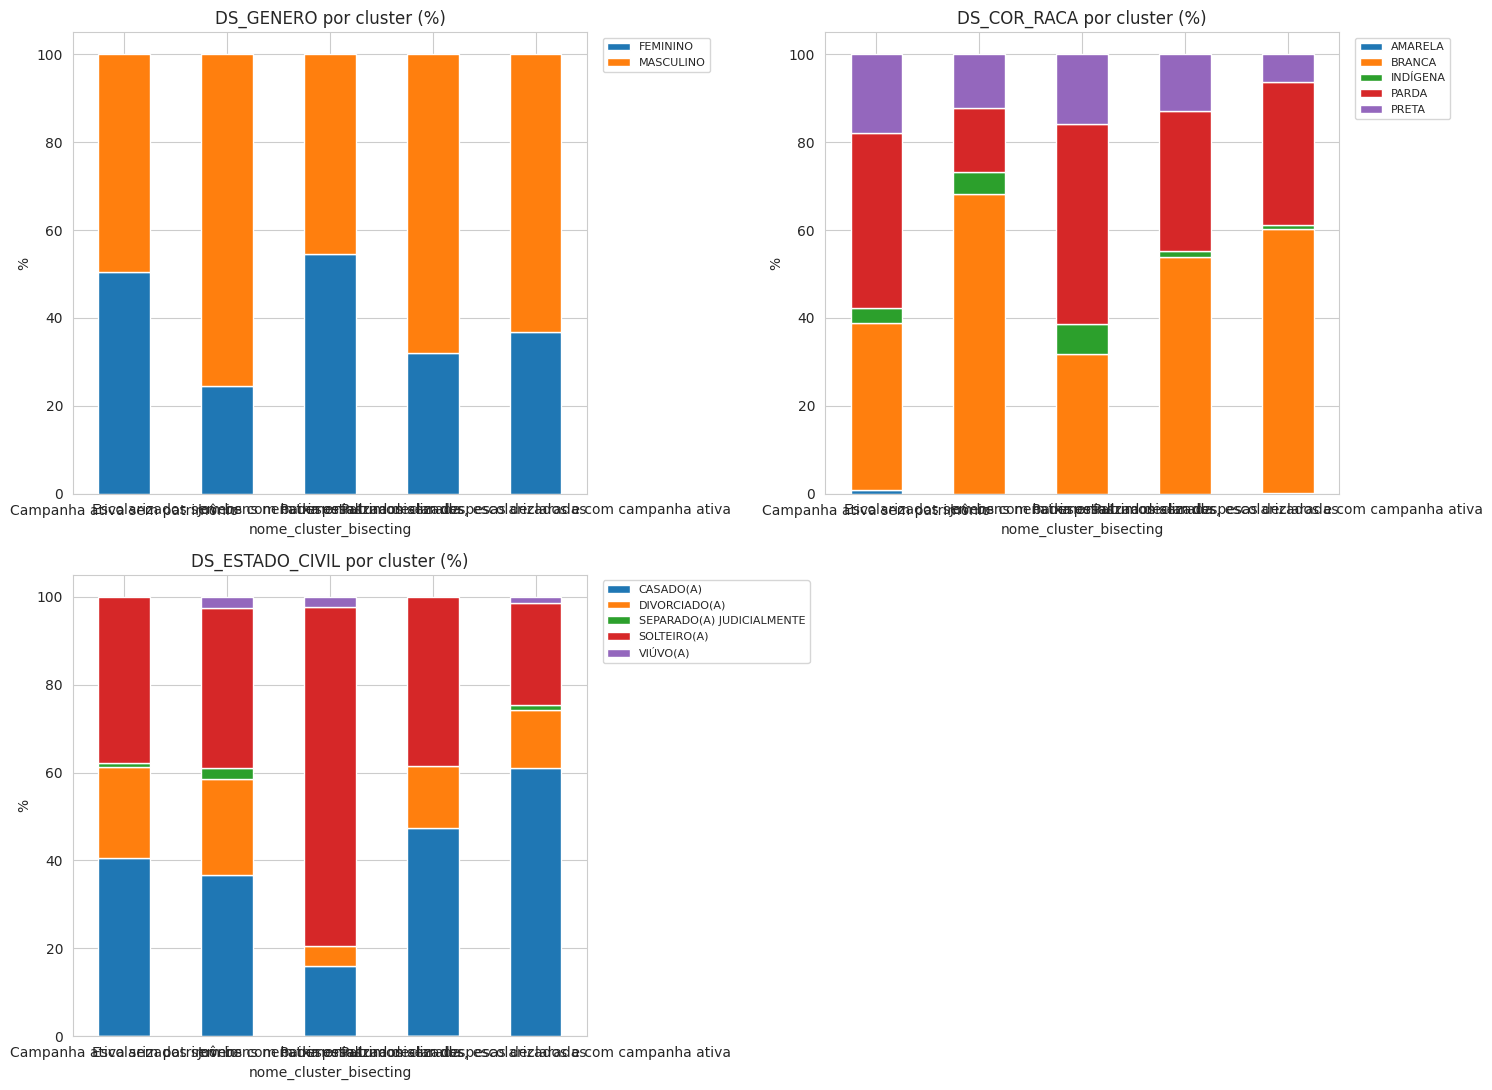

In [255]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(colunas_perfil):
    pd.crosstab(df_cluster['nome_cluster_bisecting'], df_cluster[col], normalize='index').mul(100).plot(
        kind='bar', stacked=True, ax=axes[i]
    )
    axes[i].set_title(f'{col} por cluster (%)')
    axes[i].set_ylabel('%')
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


### Direção inversa: onde cada grupo demográfico está distribuído entre os clusters

Até aqui perguntamos "dentro do cluster X, qual a composição por gênero/cor-raça/estado civil?". Agora invertemos: **de todos os candidatos de um determinado grupo, em qual cluster eles estão?** Mesma tabela de contingência, só trocando o que normaliza — mesma lógica já usada na Parte 1.


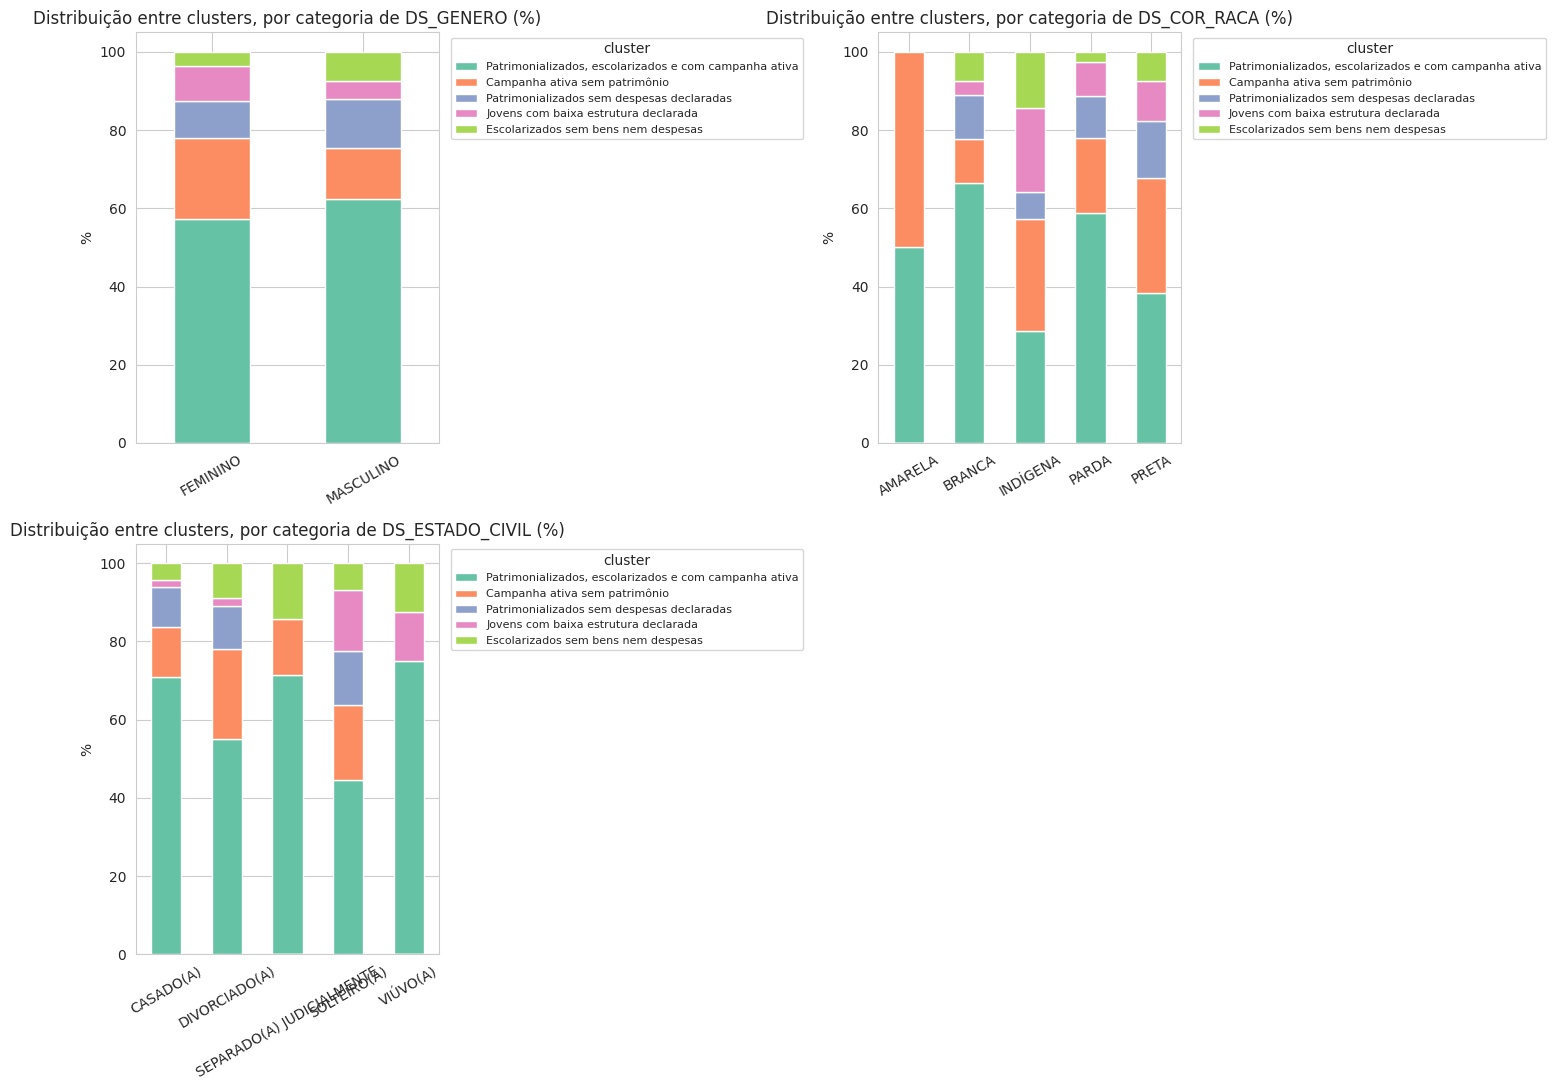

In [256]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(colunas_perfil):
    tabela = pd.crosstab(df_cluster[col], df_cluster['nome_cluster_bisecting'], normalize='index').mul(100)
    tabela = tabela[nomes_bisecting_ordenados]  # garante a mesma ordem de colunas de cores_nome_bisecting
    tabela.plot(kind='bar', stacked=True, ax=axes[i], color=[cores_nome_bisecting[c] for c in tabela.columns])
    axes[i].set_title(f'Distribuição entre clusters, por categoria de {col} (%)')
    axes[i].set_ylabel('%')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].legend(title='cluster', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


### 10) Partidos: quais legendas dominam cada cluster

A Parte 1 não olhou partido — mas como boa parte do que diferencia os clusters aqui é "declarou patrimônio ou não", vale ver se isso também aparece na legenda: candidaturas de partidos pequenos costumam ser mais simbólicas, com menos estrutura (e menos bens declarados) por trás.


In [257]:
for nome in nomes_bisecting_ordenados:
    sub = df_cluster[df_cluster['nome_cluster_bisecting'] == nome]
    top5 = (sub['SG_PARTIDO'].value_counts(normalize=True) * 100).round(1).head(5)
    print(f"{nome} ({len(sub)} candidatos) — partidos mais frequentes:")
    for partido, pct in top5.items():
        print(f"  {partido}: {pct:.1f}%")
    print()


Patrimonializados, escolarizados e com campanha ativa (418 candidatos) — partidos mais frequentes:
  PL: 10.0%
  REPUBLICANOS: 9.1%
  PSDB: 7.4%
  MDB: 6.7%
  PT: 6.7%

Campanha ativa sem patrimônio (111 candidatos) — partidos mais frequentes:
  PDT: 16.2%
  PSOL: 12.6%
  NOVO: 11.7%
  MISSÃO: 10.8%
  DC: 4.5%

Patrimonializados sem despesas declaradas (78 candidatos) — partidos mais frequentes:
  DC: 20.5%
  PODE: 10.3%
  PRD: 7.7%
  PSB: 7.7%
  REPUBLICANOS: 6.4%

Jovens com baixa estrutura declarada (44 candidatos) — partidos mais frequentes:
  DC: 20.5%
  MISSÃO: 11.4%
  AGIR: 11.4%
  PCO: 9.1%
  PODE: 9.1%

Escolarizados sem bens nem despesas (41 candidatos) — partidos mais frequentes:
  DC: 24.4%
  AVANTE: 7.3%
  AGIR: 7.3%
  PSDB: 7.3%
  NOVO: 7.3%



### 11) Existe um padrão regional?

Esta seção compara as UFs sempre que o recorte contém mais de uma sigla — mesma lógica da Parte 1. Preferimos duas visualizações: uma olhando de dentro de cada cluster ("desse grupo, de onde vêm os candidatos?"), outra de dentro de cada UF ("nesse estado, qual a mistura de clusters?").


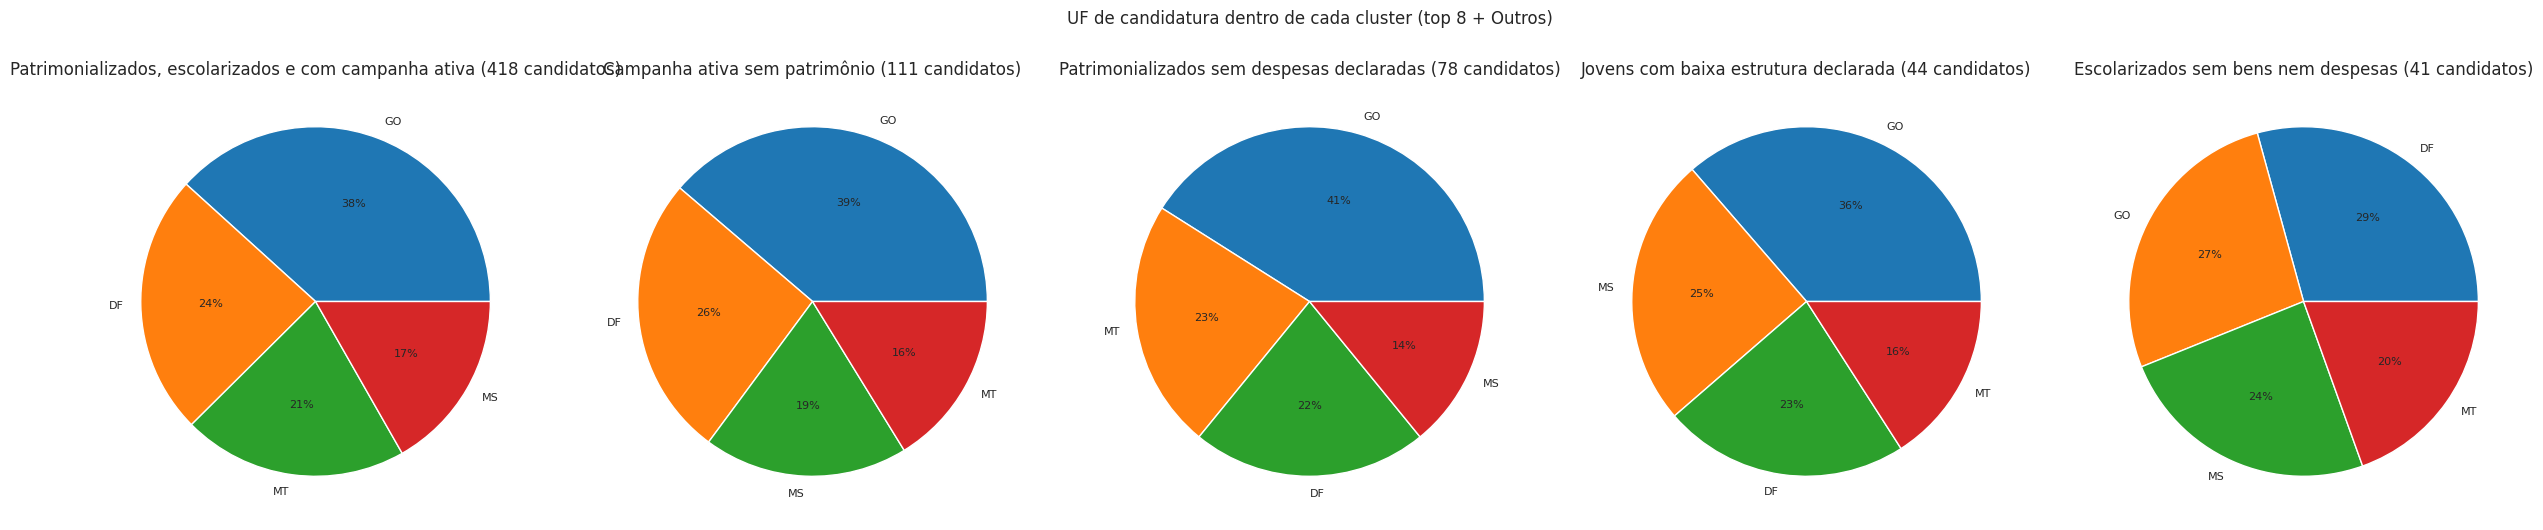

In [258]:
def contagem_top_n(serie, top_n=8, rotulo_outros='Outros'):
    """Série de contagens com só as `top_n` categorias mais frequentes; o resto vira uma
    única fatia `rotulo_outros—pra pizza não virar um mosaico de fatias minúsculas
    (relevante aqui: SG_UF tem 27 valores possíveis)."""
    contagem = serie.value_counts()
    if len(contagem) <= top_n:
        return contagem
    principais = contagem.head(top_n).copy()
    resto = contagem.iloc[top_n:].sum()
    if resto > 0:
        principais[rotulo_outros] = resto
    return principais


if UF is None or not isinstance(UF, str):
    fig, axes = plt.subplots(1, len(nomes_bisecting_ordenados), figsize=(5 * len(nomes_bisecting_ordenados), 5))
    for ax, nome in zip(axes, nomes_bisecting_ordenados):
        sub = df_cluster[df_cluster['nome_cluster_bisecting'] == nome]
        contagem = contagem_top_n(sub['SG_UF'], top_n=8)
        ax.pie(contagem, labels=contagem.index, autopct='%1.0f%%', textprops={'fontsize': 8})
        ax.set_title(f'{nome} ({len(sub)} candidatos)')
    plt.suptitle('UF de candidatura dentro de cada cluster (top 8 + Outros)', y=1.05)
    plt.tight_layout()
    plt.show()
else:
    print(f"UF = {UF!r} — seção não se aplica (dados já filtrados para uma única UF).")


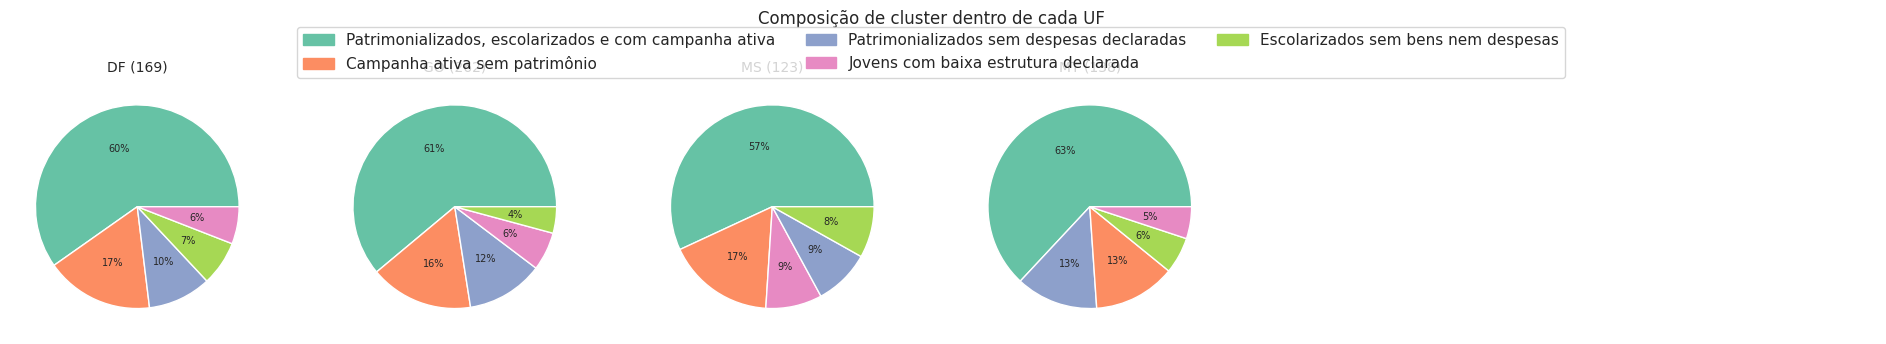

In [259]:
if UF is None or not isinstance(UF, str):
    ufs_ordenadas = sorted(df_cluster['SG_UF'].unique())
    ncols = 6
    nrows = -(-len(ufs_ordenadas) // ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.2 * nrows))
    axes = axes.flatten()

    for ax, uf in zip(axes, ufs_ordenadas):
        sub = df_cluster[df_cluster['SG_UF'] == uf]
        contagem = sub['nome_cluster_bisecting'].value_counts()
        cores_fatias = [cores_nome_bisecting[nome] for nome in contagem.index]
        ax.pie(contagem, labels=None, autopct=lambda p: f'{p:.0f}%' if p > 0 else '',
               colors=cores_fatias, textprops={'fontsize': 7})
        ax.set_title(f'{uf} ({len(sub)})', fontsize=10)

    for ax in axes[len(ufs_ordenadas):]:
        ax.axis('off')

    handles = [plt.Rectangle((0, 0), 1, 1, color=cores_nome_bisecting[nome]) for nome in nomes_bisecting_ordenados]
    fig.legend(handles, nomes_bisecting_ordenados, loc='upper center', bbox_to_anchor=(0.5, 1.03), ncol=3, fontsize=11)
    plt.suptitle('Composição de cluster dentro de cada UF', y=1.06)
    plt.tight_layout()
    plt.show()
else:
    print(f"UF = {UF!r} — seção não se aplica (dados já filtrados para uma única UF).")


### 12) Rascunho automático — editem à vontade


In [260]:
for cl in clusters_bisecting_ordenados:
    linha = ficha_bisecting.loc[cl]
    print(f"Cluster {cl}  ({linha['qtd']:.0f} candidatos, {linha['pct_do_total']:.0f}% do total)")
    print(f"  Idade média: {linha['idade_media']:.0f} anos | Escolaridade média: {linha['anos_estudo_medio']:.0f} anos de estudo")
    print(f"  Patrimônio mediano: R$ {linha['patrimonio_mediano']:,.0f} | {linha['pct_sem_bens']:.0f}% declaram patrimônio zero")
    print(f"  Despesas medianas: R$ {linha['despesas_medianas']:,.0f} | {linha['pct_sem_despesas']:.0f}% sem despesas declaradas")
    for col in colunas_ficha:
        print(f"  Predominância em {col}: {linha[f'{col}_predominante']} ({linha[f'{col}_pct']:.0f}%)")
    print(f"  >> Nome sugerido: _______________________")
    print()


Cluster A  (418 candidatos, 60% do total)
  Idade média: 51 anos | Escolaridade média: 15 anos de estudo
  Patrimônio mediano: R$ 643,810 | 0% declaram patrimônio zero
  Despesas medianas: R$ 127,893 | 0% sem despesas declaradas
  Predominância em DS_GENERO: MASCULINO (63%)
  Predominância em DS_COR_RACA: BRANCA (60%)
  Predominância em DS_ESTADO_CIVIL: CASADO(A) (61%)
  Predominância em DS_OCUPACAO: EMPRESÁRIO (12%)
  >> Nome sugerido: _______________________

Cluster B  (111 candidatos, 16% do total)
  Idade média: 44 anos | Escolaridade média: 13 anos de estudo
  Patrimônio mediano: R$ 0 | 100% declaram patrimônio zero
  Despesas medianas: R$ 20,000 | 0% sem despesas declaradas
  Predominância em DS_GENERO: FEMININO (50%)
  Predominância em DS_COR_RACA: PARDA (40%)
  Predominância em DS_ESTADO_CIVIL: CASADO(A) (40%)
  Predominância em DS_OCUPACAO: EMPRESÁRIO (12%)
  >> Nome sugerido: _______________________

Cluster C  (78 candidatos, 11% do total)
  Idade média: 50 anos | Escolarid

### Nomes finais dos clusters (Bisecting K-Means, k=5)

A partir da ficha técnica e das composições acima, os cinco clusters se leem assim:

- **Cluster A** (418 candidatos, 60,4%): idade média de 50,7 anos, 15 anos de estudo em média, patrimônio mediano de R$ 643,8 mil e despesas medianas de R$ 127,9 mil. → **Patrimonializados, escolarizados e com campanha ativa**.
- **Cluster B** (111 candidatos, 16,0%): todos sem patrimônio declarado, mas todos com despesas de campanha; a mediana das despesas é R$ 20 mil. → **Campanha ativa sem patrimônio**.
- **Cluster C** (78 candidatos, 11,3%): patrimônio mediano de R$ 203 mil, porém 96,2% sem despesas no snapshot. → **Patrimonializados sem despesas declaradas**.
- **Cluster D** (44 candidatos, 6,4%): grupo mais jovem e de menor escolaridade; 95,5% não declararam bens nem despesas. → **Jovens com baixa estrutura declarada**.
- **Cluster E** (41 candidatos, 5,9%): mais velhos e escolarizados que o Cluster D, mas todos sem patrimônio e 95,1% sem despesas. → **Escolarizados sem bens nem despesas**.

Os nomes sintetizam tendências dos grupos, não classificações individuais. O quinto cluster permite distinguir dois perfis que compartilham bens e despesas próximos de zero, mas diferem principalmente em idade, escolaridade, gênero, cor/raça e estado civil.


In [261]:
# nomes já aplicados mais acima (logo depois da seção 8), reaproveitados em toda a análise
# demográfica/partidária/regional desta parte — aqui só o recap final:
df_cluster[['cluster_bisecting', 'nome_cluster_bisecting']].value_counts().sort_index()


,,count
cluster_bisecting,nome_cluster_bisecting,
A,"Patrimonializados, escolarizados e com campanha ativa",418
B,Campanha ativa sem patrimônio,111
C,Patrimonializados sem despesas declaradas,78
D,Jovens com baixa estrutura declarada,44
E,Escolarizados sem bens nem despesas,41


### 13) Caracterização por gênero, cor/raça e estado civil

Esta seção consolida a composição demográfica dos clusters finais do Bisecting K-Means. Os percentuais são calculados **dentro de cada cluster**, permitindo comparar os perfis mesmo quando os grupos têm tamanhos diferentes.

--- Gênero por cluster (%) ---


,DS_GENERO,FEMININO,MASCULINO
cluster_bisecting,nome_cluster_bisecting,,
A,"Patrimonializados, escolarizados e com campanha ativa",36.80,63.20
B,Campanha ativa sem patrimônio,50.50,49.50
C,Patrimonializados sem despesas declaradas,32.10,67.90
D,Jovens com baixa estrutura declarada,54.50,45.50
E,Escolarizados sem bens nem despesas,24.40,75.60


--- Cor/raça por cluster (%) ---


,DS_COR_RACA,AMARELA,BRANCA,INDÍGENA,PARDA,PRETA
cluster_bisecting,nome_cluster_bisecting,,,,,
A,"Patrimonializados, escolarizados e com campanha ativa",0.20,60.00,1.00,32.50,6.20
B,Campanha ativa sem patrimônio,0.90,37.80,3.60,39.60,18.00
C,Patrimonializados sem despesas declaradas,0.00,53.80,1.30,32.10,12.80
D,Jovens com baixa estrutura declarada,0.00,31.80,6.80,45.50,15.90
E,Escolarizados sem bens nem despesas,0.00,68.30,4.90,14.60,12.20


--- Estado civil por cluster (%) ---


,DS_ESTADO_CIVIL,CASADO(A),DIVORCIADO(A),SEPARADO(A) JUDICIALMENTE,SOLTEIRO(A),VIÚVO(A)
cluster_bisecting,nome_cluster_bisecting,,,,,
A,"Patrimonializados, escolarizados e com campanha ativa",61.00,13.20,1.20,23.20,1.40
B,Campanha ativa sem patrimônio,40.50,20.70,0.90,37.80,0.00
C,Patrimonializados sem despesas declaradas,47.40,14.10,0.00,38.50,0.00
D,Jovens com baixa estrutura declarada,15.90,4.50,0.00,77.30,2.30
E,Escolarizados sem bens nem despesas,36.60,22.00,2.40,36.60,2.40


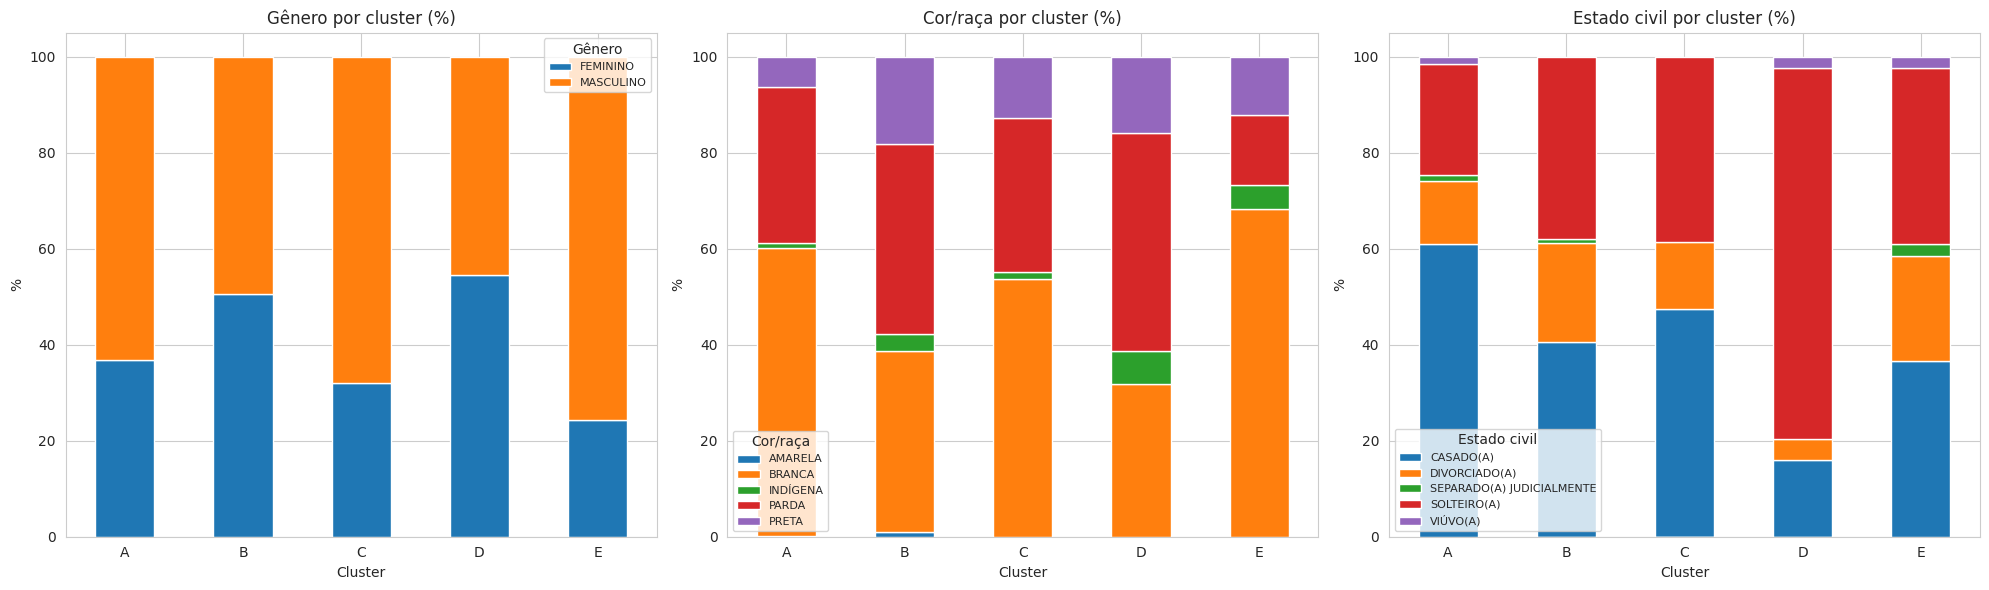

In [262]:
variaveis_caracterizacao = {
    'DS_GENERO': 'Gênero',
    'DS_COR_RACA': 'Cor/raça',
    'DS_ESTADO_CIVIL': 'Estado civil',
}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, (coluna, titulo) in zip(axes, variaveis_caracterizacao.items()):
    tabela = pd.crosstab(
        [df_cluster['cluster_bisecting'], df_cluster['nome_cluster_bisecting']],
        df_cluster[coluna],
        normalize='index'
    ).mul(100).round(1)

    print(f'--- {titulo} por cluster (%) ---')
    display(tabela)

    tabela.droplevel('nome_cluster_bisecting').plot(
        kind='bar', stacked=True, ax=ax
    )
    ax.set_title(f'{titulo} por cluster (%)')
    ax.set_xlabel('Cluster')
    ax.set_ylabel('%')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title=titulo, fontsize=8)

plt.tight_layout()
plt.show()

---
## Fechamento e próximos passos

Duas famílias de algoritmo até aqui:

- **K-Means (Parte 1)**, em duas rodadas — mostrando o efeito de tratar uma variável ordinal como intervalar, e de usar mais de uma métrica pra escolher `k`.
- **Bisecting K-Means (Parte 2)** — construção incremental e visual, com uma árvore mostrando a ordem das divisões, avaliação de k e cinco clusters finais (k=5): **Patrimonializados, escolarizados e com campanha ativa**, **Campanha ativa sem patrimônio**, **Patrimonializados sem despesas declaradas**, **Jovens com baixa estrutura declarada** e **Escolarizados sem bens nem despesas**.

Continua em `02_clusterizacao_outros.ipynb`: **DBSCAN** e **clusterização hierárquica**, reaproveitando a mesma base e a mesma pergunta de negócio.

# Fase 3 — Regras de Associação: Candidatos 2026 (TSE)

## Pergunta de negócio

> **Que combinações de características dos candidatos aparecem juntas com mais frequência do que se fossem independentes? Em particular: quais atributos (partido, gênero, escolaridade, cor/raça, UF de nascimento e quartis das variáveis contínuas) estão associados a cada perfil identificado na Fase 2 — e, assim que a eleição ocorrer, a ser eleito?**

Até aqui, a clusterização (Fase 2) agrupou candidatos por **distância** em quatro variáveis numéricas (idade, tempo de estudo, patrimônio e despesas). Regras de associação fazem uma pergunta diferente: em vez de "quem está perto de quem", **quais combinações de atributos categóricos aparecem juntas com mais frequência do que o acaso explicaria**? A técnica clássica pra isso é o **Apriori**, que originalmente resolve o problema da "cesta de compras" (que produtos são comprados juntos) — aqui, cada candidato é uma cesta, e cada valor de cada variável categórica (partido, gênero, escolaridade...) é um item dessa cesta.


## Configuração

Use os **mesmos valores** que você usou nas Fases 0/1/2, para carregar o arquivo certo.


In [263]:
CARGO = "DEPUTADO FEDERAL"
UF = ['DF', 'GO', 'MS', 'MT']
ANO_ELEICAO = 2026
K_BISECTING = 5


## Preparando a base — reconstituindo os clusters nomeados da Fase 2

Apriori precisa de **itens categóricos**, não de distância — mas queremos incluir o cluster da Fase 2 como mais um item da cesta. Na Fase 2 (`02_clusterizacao.ipynb`), o **Bisecting K-Means com k=5** (critério de inércia média) foi o resultado final escolhido, e os cinco clusters foram batizados a partir da ficha técnica e da composição demográfica/partidária:

- **Patrimonializados, escolarizados e com campanha ativa**.
- **Campanha ativa sem patrimônio**.
- **Patrimonializados sem despesas declaradas**.
- **Jovens com baixa estrutura declarada**.
- **Escolarizados sem bens nem despesas**.

Recalculamos aqui, rapidamente, a mesma partição (mesma `SEMENTE`, mesmo critério, mesmos nomes) — mesma lógica de auto-suficiência já usada no `02_clusterizacao_outros.ipynb`.


In [264]:
!pip install pyvis -q

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from mlxtend.frequent_patterns import apriori, association_rules
from pyvis.network import Network
from IPython.display import IFrame

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)  # não truncar antecedents/consequents nas tabelas

SEMENTE = 42
np.random.seed(SEMENTE)  # mesmo racional de reprodutibilidade defensiva dos notebooks anteriores

nome_uf = str(UF) if UF is not None else 'BRASIL'
nome_cargo = CARGO.replace(' ', '_')
arquivo = f"/dados/candidatos_{nome_cargo}_{nome_uf}_{ANO_ELEICAO}.csv"

df = pd.read_csv(arquivo)
print(f"Carregado: {arquivo}  ->  {df.shape[0]} candidatos, {df.shape[1]} colunas")
df.head()

Carregado: /dados/candidatos_DEPUTADO_FEDERAL_['DF', 'GO', 'MS', 'MT']_2026.csv  ->  692 candidatos, 59 colunas


,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,SG_UF,SG_UE,NM_UE,CD_CARGO,DS_CARGO,SQ_CANDIDATO,NR_CANDIDATO,NM_CANDIDATO,NM_URNA_CANDIDATO,NM_SOCIAL_CANDIDATO,NR_CPF_CANDIDATO,DS_EMAIL,CD_SITUACAO_CANDIDATURA,DS_SITUACAO_CANDIDATURA,TP_AGREMIACAO,NR_PARTIDO,SG_PARTIDO,NM_PARTIDO,NR_FEDERACAO,NM_FEDERACAO,SG_FEDERACAO,DS_COMPOSICAO_FEDERACAO,SQ_COLIGACAO,NM_COLIGACAO,DS_COMPOSICAO_COLIGACAO,SG_UF_NASCIMENTO,DT_NASCIMENTO,NR_TITULO_ELEITORAL_CANDIDATO,CD_GENERO,DS_GENERO,CD_GRAU_INSTRUCAO,DS_GRAU_INSTRUCAO,CD_ESTADO_CIVIL,DS_ESTADO_CIVIL,CD_COR_RACA,DS_COR_RACA,CD_OCUPACAO,DS_OCUPACAO,CD_SIT_TOT_TURNO,DS_SIT_TOT_TURNO,BENS IMÓVEIS,BENS MÓVEIS,DINHEIRO,INVESTIMENTOS RENDA FIXA,INVESTIMENTOS RENDA VARIÁVEL,OUTROS BENS,Total_Bens,Total_Bens_Log,IDADE
0,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532001,3022,ALESSANDRA ALMEIDA CHIANELLI DUTRA,ALE CHIANELLI,#NULO,58442472134,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,DF,1972-11-28,11236642070,4,FEMININO,8,SUPERIOR COMPLETO,9,DIVORCIADO(A),1,BRANCA,171,JORNALISTA E REDATOR,-1,#NULO,0.00,"130,000.00",0.00,0.00,0.00,0.00,"130,000.00",11.78,53
1,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532002,3012,PAULO CESAR ECHEBARRIA DE CARVALHO,PAULO ECHEBARRIA,#NULO,37959077134,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,GO,1965-10-20,7033782089,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),1,BRANCA,171,JORNALISTA E REDATOR,-1,#NULO,0.00,"380,000.00",0.00,0.00,0.00,"15,000,000.00","15,380,000.00",16.55,60
2,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532003,3004,FLAVIO HENRIQUE TORMINN FLEURY,FLAVIO FLEURY,#NULO,88847560144,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,GO,1981-09-01,46935651074,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),1,BRANCA,114,FISIOTERAPEUTA E TERAPEUTA OCUPACIONAL,-1,#NULO,0.00,"53,000.00",0.00,0.00,0.00,0.00,"53,000.00",10.88,45
3,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532004,3030,CARINE TEIXEIRA MARQUES,CARINE TEIXEIRA,#NULO,1642767182,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,GO,1986-08-25,52572671066,4,FEMININO,8,SUPERIOR COMPLETO,3,CASADO(A),2,PRETA,257,EMPRESÁRIO,-1,#NULO,0.00,0.00,0.00,0.00,"120,000.00",0.00,"120,000.00",11.70,40
4,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532005,3010,EMILIO KERBER FILHO,EMILIO KERBER,#NULO,92759130053,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,PR,1976-08-31,263044410167,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),1,BRANCA,185,ESCRITOR E CRÍTICO,-1,#NULO,"1,380,000.00",0.00,0.00,0.00,0.00,0.00,"1,380,000.00",14.14,50


In [265]:
ANOS_ESTUDO_POR_GRAU = {
    'ANALFABETO': 0,
    'LÊ E ESCREVE': 1,
    'ENSINO FUNDAMENTAL INCOMPLETO': 4,
    'ENSINO FUNDAMENTAL COMPLETO': 8,
    'ENSINO MÉDIO INCOMPLETO': 9,
    'ENSINO MÉDIO COMPLETO': 11,
    'SUPERIOR INCOMPLETO': 13,
    'SUPERIOR COMPLETO': 16,
    # 'NÃO DIVULGÁVEL' fica de fora de propósito — mesma decisão da Versão 2 do notebook de clusterização
}

df['ANOS_ESTUDO'] = df['DS_GRAU_INSTRUCAO'].map(ANOS_ESTUDO_POR_GRAU)

# Mesma integração de despesas usada nas Fases 1 e 2.
arquivos_despesas = [
    Path(f'/dados/despesas_contratadas_candidatos_{ANO_ELEICAO}_{uf}.csv')
    for uf in UF
]
arquivos_ausentes = [str(p) for p in arquivos_despesas if not p.exists()]
if arquivos_ausentes:
    raise FileNotFoundError('Arquivos de despesas ausentes: ' + ', '.join(arquivos_ausentes))

partes_despesas = []
for caminho in arquivos_despesas:
    parte = pd.read_csv(
        caminho, sep=';', encoding='latin-1',
        usecols=['DS_CARGO', 'SQ_CANDIDATO', 'VR_DESPESA_CONTRATADA'],
        dtype={'SQ_CANDIDATO': 'int64'}
    )
    parte = parte[parte['DS_CARGO'].str.upper() == CARGO.upper()].copy()
    parte['VR_DESPESA_CONTRATADA'] = pd.to_numeric(
        parte['VR_DESPESA_CONTRATADA'].astype(str)
        .str.replace('.', '', regex=False).str.replace(',', '.', regex=False),
        errors='coerce'
    )
    partes_despesas.append(parte)

gasto_por_candidato = (
    pd.concat(partes_despesas, ignore_index=True)
    .groupby('SQ_CANDIDATO', as_index=False)['VR_DESPESA_CONTRATADA'].sum(min_count=1)
    .rename(columns={'VR_DESPESA_CONTRATADA': 'Total_Gasto_Campanha'})
)
df = df.merge(gasto_por_candidato, on='SQ_CANDIDATO', how='left')
df['Total_Gasto_Campanha'] = df['Total_Gasto_Campanha'].fillna(0)
df['Total_Gasto_Campanha_Log'] = np.log1p(df['Total_Gasto_Campanha'])


In [266]:
colunas_driver = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log', 'Total_Gasto_Campanha_Log']

Q1, Q3 = df['Total_Bens_Log'].quantile([0.25, 0.75])
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

df_cluster = df[(df['Total_Bens_Log'] <= limite_superior) & (df['ANOS_ESTUDO'].notna())].copy()
print(f"Base para clusterização/regras: {df_cluster.shape[0]} candidatos "
      f"(descartados {df.shape[0] - df_cluster.shape[0]} por patrimônio extremo ou escolaridade não divulgada)")

scaler = MinMaxScaler()
X = scaler.fit_transform(df_cluster[colunas_driver])


Base para clusterização/regras: 692 candidatos (descartados 0 por patrimônio extremo ou escolaridade não divulgada)


In [267]:
def inercia(indices):
    if len(indices) < 2:
        return 0.0
    pontos = X[indices]
    centro = pontos.mean(axis=0)
    return float(((pontos - centro) ** 2).sum(axis=1).mean())


def bisecting_kmeans_ate_k(X, k_max, random_state=SEMENTE):
    """Mesma lógica do 02_clusterizacao.ipynb (Parte 2, critério de inércia média) — mas só
    devolve a partição final em k_max clusters, sem guardar o histórico de divisões (essa
    exploração já foi feita e documentada lá)."""
    clusters = {0: np.arange(X.shape[0])}
    proximo_id = 1
    for _ in range(1, k_max):
        id_escolhido = max(clusters, key=lambda cid: inercia(clusters[cid]))
        indices_pai = clusters[id_escolhido]
        if len(indices_pai) < 2:
            break
        km2 = KMeans(n_clusters=2, random_state=random_state, n_init=10)
        labels2 = km2.fit_predict(X[indices_pai])
        id_a, id_b = proximo_id, proximo_id + 1
        proximo_id += 2
        del clusters[id_escolhido]
        clusters[id_a] = indices_pai[labels2 == 0]
        clusters[id_b] = indices_pai[labels2 == 1]
    return clusters


k_bisecting = K_BISECTING

clusters_finais = bisecting_kmeans_ate_k(X, k_bisecting)
ids_por_tamanho = sorted(clusters_finais, key=lambda cid: len(clusters_finais[cid]), reverse=True)

rotulos = np.empty(X.shape[0], dtype=object)
for letra, cid in zip([chr(65 + i) for i in range(len(ids_por_tamanho))], ids_por_tamanho):
    rotulos[clusters_finais[cid]] = letra
df_cluster['cluster_bisecting'] = rotulos

# mesmos nomes definidos no 02_clusterizacao.ipynb, a partir da mesma ficha técnica
NOMES_CLUSTER_BISECTING = {
    'A': 'Patrimonializados, escolarizados e com campanha ativa',
    'B': 'Campanha ativa sem patrimônio',
    'C': 'Patrimonializados sem despesas declaradas',
    'D': 'Jovens com baixa estrutura declarada',
    'E': 'Escolarizados sem bens nem despesas',
}
df_cluster['cluster'] = df_cluster['cluster_bisecting'].map(NOMES_CLUSTER_BISECTING)

df_cluster['cluster'].value_counts()


,count
cluster,
"Patrimonializados, escolarizados e com campanha ativa",418
Campanha ativa sem patrimônio,111
Patrimonializados sem despesas declaradas,78
Jovens com baixa estrutura declarada,44
Escolarizados sem bens nem despesas,41


## Montando a "cesta" de itens

Apriori não trabalha com números contínuos como o K-Means — ele precisa de **itens binários** (presente/ausente), do mesmo jeito que "pão" e "leite" são itens numa cesta de supermercado. Cada linha vira uma "cesta" (um candidato), e cada valor de cada variável categórica vira um "item" via one-hot encoding (`SG_PARTIDO=PT`, `DS_GENERO=FEMININO`, `cluster=Campanha ativa sem patrimônio`, ...).

Variáveis escolhidas:
- `SG_PARTIDO`, `DS_GENERO`, `DS_GRAU_INSTRUCAO`, `DS_ESTADO_CIVIL`, `DS_COR_RACA`, `SG_UF_NASCIMENTO` — perfil do candidato.
- `cluster` — o nome do cluster da Fase 2 (Bisecting K-Means, k=5), recalculado acima. Incluir o cluster como item deixa a pergunta "o que caracteriza cada cluster?" ser respondida de novo do ponto de vista de regras — e permite achar combinações de 2+ variáveis que sozinhas não bastariam.
- Quartis de `IDADE`, `ANOS_ESTUDO`, `Total_Bens` e `Total_Gasto_Campanha` — as quatro variáveis contínuas usadas na clusterização, transformadas em itens de Q1 (menores valores) a Q4 (maiores valores). Empates são distribuídos de forma determinística para manter quatro faixas.
- `SG_UF` — entra porque o recorte reúne quatro UFs; só ficaria de fora num recorte de UF única.
- `DS_SIT_TOT_TURNO` (eleito ou não) — só entra depois que a eleição de fato ocorrer (a coluna hoje vem toda com o mesmo valor, `#NULO`). A seção que usa isso fica pronta, mas roda condicionalmente lá na frente.

`DS_OCUPACAO` fica de fora por ora porque possui muitas categorias; várias ocupações teriam suporte baixo demais para regras confiáveis. Fica como exercício agrupá-las em categorias maiores (ex.: "política", "direito", "saúde", "educação", "empresário") e testar.


In [268]:
colunas_apriori = ['SG_PARTIDO', 'DS_GENERO', 'DS_GRAU_INSTRUCAO', 'DS_ESTADO_CIVIL',
                   'DS_COR_RACA', 'SG_UF_NASCIMENTO', 'cluster']

variaveis_quartis = {
    'IDADE': 'IDADE_QUARTIL',
    'ANOS_ESTUDO': 'ANOS_ESTUDO_QUARTIL',
    'Total_Bens': 'TOTAL_BENS_QUARTIL',
    'Total_Gasto_Campanha': 'TOTAL_DESPESAS_QUARTIL',
}
rotulos_quartis = ['Q1', 'Q2', 'Q3', 'Q4']
for coluna, coluna_quartil in variaveis_quartis.items():
    df_cluster[coluna_quartil] = pd.qcut(
        df_cluster[coluna].rank(method='first'), q=4, labels=rotulos_quartis
    )

colunas_apriori.extend(variaveis_quartis.values())

if UF is None or not isinstance(UF, str):
    colunas_apriori.append('SG_UF')

# a eleição de 2026 ainda não ocorreu -> DS_SIT_TOT_TURNO vem toda com o mesmo valor por enquanto
usar_resultado_eleicao = df_cluster['DS_SIT_TOT_TURNO'].nunique() > 1
if usar_resultado_eleicao:
    colunas_apriori.append('DS_SIT_TOT_TURNO')

cesta_base = df_cluster[['SQ_CANDIDATO'] + colunas_apriori].copy()
cesta = pd.get_dummies(cesta_base, columns=colunas_apriori, prefix_sep='=')
cesta = cesta.set_index('SQ_CANDIDATO')

print(f"{cesta.shape[0]} candidatos (cestas) x {cesta.shape[1]} itens possíveis (um por valor de cada variável)")
cesta_base.head()


692 candidatos (cestas) x 97 itens possíveis (um por valor de cada variável)


,SQ_CANDIDATO,SG_PARTIDO,DS_GENERO,DS_GRAU_INSTRUCAO,DS_ESTADO_CIVIL,DS_COR_RACA,SG_UF_NASCIMENTO,cluster,IDADE_QUARTIL,ANOS_ESTUDO_QUARTIL,TOTAL_BENS_QUARTIL,TOTAL_DESPESAS_QUARTIL,SG_UF
0,70002532001,NOVO,FEMININO,SUPERIOR COMPLETO,DIVORCIADO(A),BRANCA,DF,"Patrimonializados, escolarizados e com campanha ativa",Q3,Q2,Q2,Q3,DF
1,70002532002,NOVO,MASCULINO,SUPERIOR COMPLETO,CASADO(A),BRANCA,GO,"Patrimonializados, escolarizados e com campanha ativa",Q4,Q2,Q4,Q2,DF
2,70002532003,NOVO,MASCULINO,SUPERIOR COMPLETO,CASADO(A),BRANCA,GO,"Patrimonializados, escolarizados e com campanha ativa",Q2,Q2,Q2,Q2,DF
3,70002532004,NOVO,FEMININO,SUPERIOR COMPLETO,CASADO(A),PRETA,GO,"Patrimonializados, escolarizados e com campanha ativa",Q1,Q2,Q2,Q2,DF
4,70002532005,NOVO,MASCULINO,SUPERIOR COMPLETO,CASADO(A),BRANCA,PR,"Patrimonializados, escolarizados e com campanha ativa",Q3,Q2,Q4,Q2,DF


## Itens frequentes: o que aparece sozinho, com que frequência

O Apriori funciona em duas etapas. Primeiro, encontra **itemsets frequentes** — combinações de 1, 2, 3... itens que aparecem juntas em pelo menos `min_suporte` das cestas. Só depois, na segunda etapa, ele vira **regras** (`A → B`). Começamos pelos itemsets de um item só — a frequência "crua" de cada valor, antes de cruzar qualquer coisa.


In [269]:
min_suporte = 0.02  # ~14 candidatos; ajuste se quiser regras mais raras (menor) ou mais comuns (maior)

itens_frequentes = apriori(cesta, min_support=min_suporte, use_colnames=True, max_len=3)
print(f"{len(itens_frequentes)} itemsets frequentes (min_suporte={min_suporte})")

individuais = itens_frequentes[itens_frequentes['itemsets'].apply(lambda x: len(x) == 1)].copy()
individuais['item'] = individuais['itemsets'].apply(lambda x: next(iter(x)))
individuais['qtd_candidatos'] = (individuais['support'] * len(cesta)).round().astype(int)
individuais.sort_values('support', ascending=False)[['item', 'support', 'qtd_candidatos']].head(15)


3532 itemsets frequentes (min_suporte=0.02)


,item,support,qtd_candidatos
26,DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,0.65,451
21,DS_GENERO=MASCULINO,0.61,423
49,"cluster=Patrimonializados, escolarizados e com campanha ativa",0.60,418
31,DS_COR_RACA=BRANCA,0.54,377
28,DS_ESTADO_CIVIL=CASADO(A),0.52,359
20,DS_GENERO=FEMININO,0.39,269
67,SG_UF=GO,0.38,262
33,DS_COR_RACA=PARDA,0.33,231
30,DS_ESTADO_CIVIL=SOLTEIRO(A),0.32,218
37,SG_UF_NASCIMENTO=GO,0.27,188


### Suporte, confiança e lift — o que cada métrica mede

Regras de associação têm o formato **"se A, então B"** (A = antecedente, B = consequente), e três números resumem o quão forte é essa relação:

- **Suporte** — fração de candidatos em que A e B aparecem juntos: `suporte(A→B) = P(A e B)`. Mede o quão comum é a combinação; suporte baixo (poucos candidatos) é terreno fértil pra coincidência.
- **Confiança** — entre os candidatos que têm A, qual fração também tem B: `confiança(A→B) = P(B | A) = suporte(A e B) / suporte(A)`. É a "taxa de acerto" da regra.
- **Lift** — o quanto a confiança da regra é maior (ou menor) do que se A e B fossem independentes: `lift(A→B) = confiança(A→B) / suporte(B)`. `lift = 1` → A e B são independentes (a regra não diz nada); `lift > 1` → aparecem juntos mais do que o esperado ao acaso; `lift < 1` → aparecem juntos menos do que o esperado.

**Um cuidado importante nesta base:** são 692 candidatos distribuídos por muitos partidos e quatro UFs. Algumas categorias continuam pequenas, então poucas coincidências podem produzir lift alto sem representar um padrão estável. Por isso toda tabela de regras abaixo vem com uma coluna `qtd_candidatos` — sempre olhem ela antes de confiar num lift alto.


In [270]:
regras = association_rules(itens_frequentes, metric='lift', min_threshold=1)
regras['qtd_candidatos'] = (regras['support'] * len(cesta)).round().astype(int)
regras = regras.sort_values('confidence', ascending=False)


def formatar_regras(df_regras):
    """Troca antecedents/consequents (frozenset) por texto legível, só pra exibição —
    os dados originais (usados pra filtrar/ordenar) continuam intactos."""
    df_fmt = df_regras.copy()
    df_fmt['antecedents'] = df_fmt['antecedents'].apply(lambda x: ', '.join(sorted(str(i) for i in x)))
    df_fmt['consequents'] = df_fmt['consequents'].apply(lambda x: ', '.join(sorted(str(i) for i in x)))
    return df_fmt


print(f"{len(regras)} regras (lift >= 1)")
formatar_regras(regras[['antecedents', 'consequents', 'qtd_candidatos', 'support', 'confidence', 'lift']].head(10))


12080 regras (lift >= 1)


,antecedents,consequents,qtd_candidatos,support,confidence,lift
10886,"ANOS_ESTUDO_QUARTIL=Q3, TOTAL_DESPESAS_QUARTIL=Q4","cluster=Patrimonializados, escolarizados e com campanha ativa",58,0.08,1.00,1.66
1884,"ANOS_ESTUDO_QUARTIL=Q4, DS_GENERO=FEMININO",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,68,0.10,1.00,1.53
1880,"ANOS_ESTUDO_QUARTIL=Q3, DS_GENERO=FEMININO",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,66,0.10,1.00,1.53
7403,"DS_ESTADO_CIVIL=DIVORCIADO(A), TOTAL_DESPESAS_QUARTIL=Q4","cluster=Patrimonializados, escolarizados e com campanha ativa",17,0.02,1.00,1.66
980,"DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO, SG_PARTIDO=DC",ANOS_ESTUDO_QUARTIL=Q1,14,0.02,1.00,4.00
10406,"TOTAL_BENS_QUARTIL=Q1, TOTAL_DESPESAS_QUARTIL=Q2",cluster=Campanha ativa sem patrimônio,61,0.09,1.00,6.23
10403,"ANOS_ESTUDO_QUARTIL=Q3, cluster=Campanha ativa sem patrimônio",TOTAL_BENS_QUARTIL=Q1,16,0.02,1.00,4.00
10457,"ANOS_ESTUDO_QUARTIL=Q2, cluster=Escolarizados sem bens nem despesas",TOTAL_DESPESAS_QUARTIL=Q1,15,0.02,1.00,4.00
8332,"DS_COR_RACA=BRANCA, cluster=Jovens com baixa estrutura declarada",TOTAL_DESPESAS_QUARTIL=Q1,14,0.02,1.00,4.00
8327,"DS_COR_RACA=BRANCA, cluster=Escolarizados sem bens nem despesas",TOTAL_DESPESAS_QUARTIL=Q1,28,0.04,1.00,4.00


### Cuidado: suporte pequeno infla o lift

Vamos ver isso na prática: as regras de maior lift da base inteira, sem nenhum filtro de suporte, comparadas às regras de maior lift **exigindo pelo menos 10 candidatos** por trás delas.


In [271]:
regras_1_consequente = regras[regras['consequents'].apply(lambda x: len(x) == 1)].copy()
colunas_exibir = ['antecedents', 'consequents', 'qtd_candidatos', 'confidence', 'lift']

print("--- Maior lift, sem filtro de suporte ---")
display(formatar_regras(regras_1_consequente.sort_values('lift', ascending=False)[colunas_exibir].head(5)))

print("--- Maior lift, exigindo qtd_candidatos >= 10 ---")
display(formatar_regras(regras_1_consequente[regras_1_consequente['qtd_candidatos'] >= 10]
        .sort_values('lift', ascending=False)[colunas_exibir].head(5)))


--- Maior lift, sem filtro de suporte ---


,antecedents,consequents,qtd_candidatos,confidence,lift
6326,"ANOS_ESTUDO_QUARTIL=Q2, SG_UF=GO",DS_GRAU_INSTRUCAO=SUPERIOR INCOMPLETO,31,1.00,9.61
1140,"IDADE_QUARTIL=Q1, TOTAL_DESPESAS_QUARTIL=Q2",SG_PARTIDO=MISSÃO,20,0.42,9.30
10582,"TOTAL_BENS_QUARTIL=Q4, TOTAL_DESPESAS_QUARTIL=Q1",cluster=Patrimonializados sem despesas declaradas,18,0.95,8.40
10498,"ANOS_ESTUDO_QUARTIL=Q1, TOTAL_DESPESAS_QUARTIL=Q1",cluster=Jovens com baixa estrutura declarada,37,0.52,8.20
10470,"TOTAL_BENS_QUARTIL=Q1, TOTAL_DESPESAS_QUARTIL=Q1",cluster=Escolarizados sem bens nem despesas,36,0.48,8.10


--- Maior lift, exigindo qtd_candidatos >= 10 ---


,antecedents,consequents,qtd_candidatos,confidence,lift
6326,"ANOS_ESTUDO_QUARTIL=Q2, SG_UF=GO",DS_GRAU_INSTRUCAO=SUPERIOR INCOMPLETO,31,1.00,9.61
1140,"IDADE_QUARTIL=Q1, TOTAL_DESPESAS_QUARTIL=Q2",SG_PARTIDO=MISSÃO,20,0.42,9.30
10582,"TOTAL_BENS_QUARTIL=Q4, TOTAL_DESPESAS_QUARTIL=Q1",cluster=Patrimonializados sem despesas declaradas,18,0.95,8.40
10498,"ANOS_ESTUDO_QUARTIL=Q1, TOTAL_DESPESAS_QUARTIL=Q1",cluster=Jovens com baixa estrutura declarada,37,0.52,8.20
10470,"TOTAL_BENS_QUARTIL=Q1, TOTAL_DESPESAS_QUARTIL=Q1",cluster=Escolarizados sem bens nem despesas,36,0.48,8.10


No primeiro grupo, categorias raras de partido, nascimento ou perfil podem produzir lift muito alto com poucos candidatos. No segundo grupo, com um piso de candidatos por trás da regra, sobram combinações mais estáveis e interessantes (ex.: quartis das variáveis contínuas e características cadastrais prevendo cluster). Essa é a leitura que vamos seguir usando daqui pra frente.

### Filtrando pra regras que valem a pena olhar


In [272]:
suporte_pratico = 0.03    # ~21 candidatos
confianca_pratica = 0.5

regras_simples = regras[
    regras['antecedents'].apply(lambda x: len(x) <= 2) & regras['consequents'].apply(lambda x: len(x) == 1)
]
regras_confiaveis = regras_simples[
    (regras_simples['support'] >= suporte_pratico) & (regras_simples['confidence'] >= confianca_pratica)
]

print(f"{len(regras_confiaveis)} regras com suporte >= {suporte_pratico} e confiança >= {confianca_pratica}")
formatar_regras(regras_confiaveis.sort_values('confidence', ascending=False)[colunas_exibir].head(15))


1777 regras com suporte >= 0.03 e confiança >= 0.5


,antecedents,consequents,qtd_candidatos,confidence,lift
10886,"ANOS_ESTUDO_QUARTIL=Q3, TOTAL_DESPESAS_QUARTIL=Q4","cluster=Patrimonializados, escolarizados e com campanha ativa",58,1.00,1.66
8406,"DS_COR_RACA=BRANCA, TOTAL_DESPESAS_QUARTIL=Q4","cluster=Patrimonializados, escolarizados e com campanha ativa",121,1.00,1.66
10282,"SG_UF_NASCIMENTO=MT, TOTAL_DESPESAS_QUARTIL=Q2",SG_UF=MT,21,1.00,5.01
10487,"IDADE_QUARTIL=Q1, cluster=Jovens com baixa estrutura declarada",TOTAL_DESPESAS_QUARTIL=Q1,27,1.00,4.00
10469,"TOTAL_BENS_QUARTIL=Q1, cluster=Escolarizados sem bens nem despesas",TOTAL_DESPESAS_QUARTIL=Q1,36,1.00,4.00
4920,"ANOS_ESTUDO_QUARTIL=Q4, DS_ESTADO_CIVIL=CASADO(A)",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,107,1.00,1.53
5022,"ANOS_ESTUDO_QUARTIL=Q3, DS_ESTADO_CIVIL=DIVORCIADO(A)",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,31,1.00,1.53
4914,"ANOS_ESTUDO_QUARTIL=Q3, DS_ESTADO_CIVIL=CASADO(A)",DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,96,1.00,1.53
10784,"IDADE_QUARTIL=Q4, TOTAL_DESPESAS_QUARTIL=Q4","cluster=Patrimonializados, escolarizados e com campanha ativa",59,1.00,1.66
10729,"IDADE_QUARTIL=Q3, TOTAL_DESPESAS_QUARTIL=Q4","cluster=Patrimonializados, escolarizados e com campanha ativa",39,1.00,1.66


## O que prediz o cluster de um candidato?

Filtramos as regras cujo **consequente é um único item de cluster** — ou seja, "se o candidato tem tais características, ele cai no cluster X". É a mesma pergunta que a Fase 2 respondeu via ficha técnica, agora vista pelo ângulo de combinações de atributos categóricos.

Um cuidado extra aqui: os cinco clusters do Bisecting K-Means são desbalanceados — o maior reúne 418 candidatos, enquanto os dois menores têm 44 e 41. Ordenar apenas por confiança faria o grupo majoritário dominar a tabela; usar um piso alto e fixo poderia esconder os grupos menores. Por isso pegamos as regras de **maior lift dentro de cada cluster**, separadamente — assim os cinco aparecem e podemos comparar a força relativa de cada um.


In [273]:
def regras_para_consequente(regras_completas, prefixo, n_por_valor=6, min_suporte=min_suporte, max_antecedentes=2):
    """
    Entre as regras cujo único item consequente comece com `prefixo` (ex.: 'cluster='),
    devolve as `n_por_valor` de MAIOR LIFT pra CADA valor distinto do consequente — sem piso
    de confiança fixo, porque um valor raro (poucos candidatos) não sustenta regras de
    confiança alta mesmo quando o lift é forte; ordenar só por confiança deixaria os valores
    mais comuns dominando a tabela inteira (ver célula anterior).
    """
    candidatas = regras_completas[
        regras_completas['consequents'].apply(lambda x: len(x) == 1 and next(iter(x)).startswith(prefixo))
        & regras_completas['antecedents'].apply(lambda x: len(x) <= max_antecedentes)
        & (regras_completas['support'] >= min_suporte)
    ].copy()
    candidatas['alvo'] = candidatas['consequents'].apply(lambda x: next(iter(x)))
    resultado = (candidatas.sort_values('lift', ascending=False)
                            .groupby('alvo', group_keys=False)
                            .head(n_por_valor)
                            .sort_values(['alvo', 'lift'], ascending=[True, False]))
    return resultado.drop(columns='alvo')


regras_cluster = regras_para_consequente(regras, 'cluster=')
print(f"{len(regras_cluster)} regras (até 6 por cluster, ordenadas por lift dentro de cada um)")
formatar_regras(regras_cluster[colunas_exibir])


30 regras (até 6 por cluster, ordenadas por lift dentro de cada um)


,antecedents,consequents,qtd_candidatos,confidence,lift
10412,"TOTAL_BENS_QUARTIL=Q1, TOTAL_DESPESAS_QUARTIL=Q3",cluster=Campanha ativa sem patrimônio,34,1.00,6.23
10406,"TOTAL_BENS_QUARTIL=Q1, TOTAL_DESPESAS_QUARTIL=Q2",cluster=Campanha ativa sem patrimônio,61,1.00,6.23
1592,"SG_PARTIDO=PSOL, TOTAL_BENS_QUARTIL=Q1",cluster=Campanha ativa sem patrimônio,14,0.88,5.45
10402,"ANOS_ESTUDO_QUARTIL=Q3, TOTAL_BENS_QUARTIL=Q1",cluster=Campanha ativa sem patrimônio,16,0.80,4.99
7354,"DS_ESTADO_CIVIL=DIVORCIADO(A), TOTAL_BENS_QUARTIL=Q1",cluster=Campanha ativa sem patrimônio,23,0.74,4.63
6680,"DS_ESTADO_CIVIL=CASADO(A), TOTAL_BENS_QUARTIL=Q1",cluster=Campanha ativa sem patrimônio,41,0.68,4.26
10470,"TOTAL_BENS_QUARTIL=Q1, TOTAL_DESPESAS_QUARTIL=Q1",cluster=Escolarizados sem bens nem despesas,36,0.48,8.10
10463,"ANOS_ESTUDO_QUARTIL=Q4, TOTAL_DESPESAS_QUARTIL=Q1",cluster=Escolarizados sem bens nem despesas,16,0.47,7.94
5596,"DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO, TOTAL_DESPESAS_QUARTIL=Q1",cluster=Escolarizados sem bens nem despesas,28,0.36,6.06
10458,"ANOS_ESTUDO_QUARTIL=Q2, TOTAL_DESPESAS_QUARTIL=Q1",cluster=Escolarizados sem bens nem despesas,15,0.36,6.03


### Visualizando como grafo

Uma tabela com dezenas de regras é difícil de escanear — um grafo interativo ajuda a ver de relance quais itens aparecem mais como "explicação" (antecedentes) e quais aparecem mais como "resultado" (consequentes). Cada item vira um nó (`SG_PARTIDO=PCO`, `cluster=D`, ...); cada regra vira uma seta do antecedente pro consequente, com espessura proporcional à confiança. Os nós que começam com `cluster=` ficam destacados em vermelho e maiores, pra serem fáceis de achar no meio dos outros itens. Passe o mouse sobre uma seta pra ver confiança, lift e quantos candidatos sustentam aquela regra — e arraste os nós se a rede ficar embaralhada.


In [274]:
def grafo_regras_html(regras_plot, arquivo_html, titulo, prefixo_destaque='cluster='):
    """
    Desenha as regras como uma rede interativa (pyvis) e grava em `arquivo_html`. Cada REGRA
    vira um nó de antecedente e um nó de consequente (quando o antecedente tem mais de um
    item, eles aparecem juntos no mesmo nó, separados por "+") ligados por UMA única aresta
    — nunca uma aresta por item isolado, pra não sugerir que um item sozinho sustenta a
    confiança/lift de uma regra que na verdade depende da combinação inteira (era isso que
    causava setas duplicadas entre o mesmo par de nós). Nós que contêm algum item começando
    com `prefixo_destaque` (por padrão, os clusters da Fase 2) ficam destacados em vermelho e
    maiores. Espessura da aresta = confiança da regra; passe o mouse pra ver confiança, lift
    e quantos candidatos a sustentam. Os controles de física (embaixo do grafo) deixam
    ajustar a repulsão/gravidade entre os nós ao vivo.

    Retorna um IFrame carregando o arquivo — se aparecer em branco/preto aqui embaixo (alguns
    ambientes bloqueiam o JavaScript de saídas de célula em notebooks "não confiáveis"), abra
    `arquivo_html` direto no navegador; o grafo é o mesmo.
    """
    print(titulo)
    net = Network(height='600px', width='100%', bgcolor='#222222', font_color='white',
                  notebook=True, directed=True, cdn_resources='in_line')

    nos_adicionados = set()
    for _, row in regras_plot.iterrows():
        antecedente = ' + '.join(sorted(str(item) for item in row['antecedents']))
        consequente = ' + '.join(sorted(str(item) for item in row['consequents']))

        for label, itemset in [(antecedente, row['antecedents']), (consequente, row['consequents'])]:
            if label in nos_adicionados:
                continue
            destaque = any(str(item).startswith(prefixo_destaque) for item in itemset)
            net.add_node(
                label, label, title=label,
                color='#e41a1c' if destaque else '#1f78b4',
                size=30 if destaque else 12,
                font={'size': 22 if destaque else 14},
            )
            nos_adicionados.add(label)

        titulo_aresta = (f"Confiança: {row['confidence']:.2f} | Lift: {row['lift']:.2f} | "
                          f"{row['qtd_candidatos']} candidatos")
        net.add_edge(antecedente, consequente, value=row['confidence'], title=titulo_aresta)

    net.show_buttons(filter_=['physics'])
    net.save_graph(arquivo_html)
    print(f"Grafo salvo em: {arquivo_html} — se não aparecer abaixo, abra esse arquivo no navegador.")
    return IFrame(arquivo_html, width='100%', height=750)


grafo_regras_html(regras_cluster.head(20), 'grafo_regras_cluster.html', 'O que prediz o cluster de um candidato?')


O que prediz o cluster de um candidato?
Grafo salvo em: grafo_regras_cluster.html — se não aparecer abaixo, abra esse arquivo no navegador.


## O que caracteriza quem já é de um cluster?

A seção anterior fixou o **consequente** (`cluster=X`) e perguntou o que o prediz. Agora invertemos: fixamos o **antecedente** — "dado que o candidato é do cluster X, ..." — e olhamos pra que outros itens aparecem como consequente com lift alto. É uma pergunta diferente, não a mesma coisa ao contrário: uma regra `A → B` de lift alto não garante que `B → A` também tenha lift alto (confiança e suporte de cada lado são diferentes), então vale olhar as duas direções separadamente.


In [275]:
def regras_para_antecedente(regras_completas, item_fixo, n=8, min_suporte=min_suporte, max_consequentes=1):
    """
    Entre as regras cujo antecedente é EXATAMENTE {item_fixo} (um único item), devolve as
    `n` de maior lift. Direção oposta de `regras_para_consequente`: lá fixamos o "efeito"
    (o consequente) e procurávamos o que o prediz; aqui fixamos a "causa" (o antecedente) e
    olhamos o que ela prediz.
    """
    candidatas = regras_completas[
        regras_completas['antecedents'].apply(lambda x: len(x) == 1 and next(iter(x)) == item_fixo)
        & regras_completas['consequents'].apply(lambda x: len(x) <= max_consequentes)
        & (regras_completas['support'] >= min_suporte)
    ]
    return candidatas.sort_values('lift', ascending=False).head(n)


itens_cluster = [f'cluster={nome}' for nome in NOMES_CLUSTER_BISECTING.values()]
regras_por_cluster_fixo = {
    item: regras_para_antecedente(regras, item)
    for item in itens_cluster
}

for item_fixo, subset in regras_por_cluster_fixo.items():
    print(f"--- {item_fixo} ({len(subset)} regras) ---")
    display(formatar_regras(subset[colunas_exibir]))


--- cluster=Patrimonializados, escolarizados e com campanha ativa (8 regras) ---


,antecedents,consequents,qtd_candidatos,confidence,lift
786,"cluster=Patrimonializados, escolarizados e com campanha ativa",TOTAL_DESPESAS_QUARTIL=Q4,170,0.41,1.63
110,"cluster=Patrimonializados, escolarizados e com campanha ativa",SG_PARTIDO=PL,42,0.10,1.55
203,"cluster=Patrimonializados, escolarizados e com campanha ativa",SG_PARTIDO=PT,28,0.07,1.55
238,"cluster=Patrimonializados, escolarizados e com campanha ativa",SG_PARTIDO=UNIÃO,21,0.05,1.51
782,"cluster=Patrimonializados, escolarizados e com campanha ativa",TOTAL_BENS_QUARTIL=Q4,155,0.37,1.48
780,"cluster=Patrimonializados, escolarizados e com campanha ativa",TOTAL_BENS_QUARTIL=Q3,153,0.37,1.46
166,"cluster=Patrimonializados, escolarizados e com campanha ativa",SG_PARTIDO=PSD,25,0.06,1.38
218,"cluster=Patrimonializados, escolarizados e com campanha ativa",SG_PARTIDO=REPUBLICANOS,38,0.09,1.34


--- cluster=Campanha ativa sem patrimônio (8 regras) ---


,antecedents,consequents,qtd_candidatos,confidence,lift
721,cluster=Campanha ativa sem patrimônio,TOTAL_BENS_QUARTIL=Q1,102,0.92,3.68
193,cluster=Campanha ativa sem patrimônio,SG_PARTIDO=PSOL,14,0.13,2.91
87,cluster=Campanha ativa sem patrimônio,SG_PARTIDO=PDT,18,0.16,2.44
723,cluster=Campanha ativa sem patrimônio,TOTAL_DESPESAS_QUARTIL=Q2,67,0.60,2.41
587,cluster=Campanha ativa sem patrimônio,DS_COR_RACA=PRETA,20,0.18,1.83
411,cluster=Campanha ativa sem patrimônio,DS_GRAU_INSTRUCAO=SUPERIOR INCOMPLETO,20,0.18,1.73
715,cluster=Campanha ativa sem patrimônio,IDADE_QUARTIL=Q1,44,0.40,1.59
717,cluster=Campanha ativa sem patrimônio,ANOS_ESTUDO_QUARTIL=Q1,44,0.40,1.59


--- cluster=Patrimonializados sem despesas declaradas (8 regras) ---


,antecedents,consequents,qtd_candidatos,confidence,lift
762,cluster=Patrimonializados sem despesas declaradas,TOTAL_DESPESAS_QUARTIL=Q1,76,0.97,3.90
18,cluster=Patrimonializados sem despesas declaradas,SG_PARTIDO=DC,16,0.21,3.30
759,cluster=Patrimonializados sem despesas declaradas,TOTAL_BENS_QUARTIL=Q2,40,0.51,2.05
755,cluster=Patrimonializados sem despesas declaradas,ANOS_ESTUDO_QUARTIL=Q1,26,0.33,1.33
752,cluster=Patrimonializados sem despesas declaradas,IDADE_QUARTIL=Q4,24,0.31,1.23
503,cluster=Patrimonializados sem despesas declaradas,DS_ESTADO_CIVIL=SOLTEIRO(A),30,0.38,1.22
766,cluster=Patrimonializados sem despesas declaradas,SG_UF=MT,18,0.23,1.16
631,cluster=Patrimonializados sem despesas declaradas,SG_UF_NASCIMENTO=GO,24,0.31,1.13


--- cluster=Jovens com baixa estrutura declarada (8 regras) ---


,antecedents,consequents,qtd_candidatos,confidence,lift
749,cluster=Jovens com baixa estrutura declarada,TOTAL_DESPESAS_QUARTIL=Q1,44,1.00,4.00
745,cluster=Jovens com baixa estrutura declarada,ANOS_ESTUDO_QUARTIL=Q1,37,0.84,3.36
747,cluster=Jovens com baixa estrutura declarada,TOTAL_BENS_QUARTIL=Q1,35,0.80,3.18
341,cluster=Jovens com baixa estrutura declarada,DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO,19,0.43,2.69
743,cluster=Jovens com baixa estrutura declarada,IDADE_QUARTIL=Q1,27,0.61,2.45
501,cluster=Jovens com baixa estrutura declarada,DS_ESTADO_CIVIL=SOLTEIRO(A),34,0.77,2.45
263,cluster=Jovens com baixa estrutura declarada,DS_GENERO=FEMININO,24,0.55,1.40
559,cluster=Jovens com baixa estrutura declarada,DS_COR_RACA=PARDA,20,0.45,1.36


--- cluster=Escolarizados sem bens nem despesas (8 regras) ---


,antecedents,consequents,qtd_candidatos,confidence,lift
740,cluster=Escolarizados sem bens nem despesas,TOTAL_DESPESAS_QUARTIL=Q1,41,1.00,4.00
738,cluster=Escolarizados sem bens nem despesas,TOTAL_BENS_QUARTIL=Q1,36,0.88,3.51
736,cluster=Escolarizados sem bens nem despesas,ANOS_ESTUDO_QUARTIL=Q4,16,0.39,1.56
734,cluster=Escolarizados sem bens nem despesas,ANOS_ESTUDO_QUARTIL=Q2,15,0.37,1.46
732,cluster=Escolarizados sem bens nem despesas,IDADE_QUARTIL=Q3,14,0.34,1.37
530,cluster=Escolarizados sem bens nem despesas,DS_COR_RACA=BRANCA,28,0.68,1.25
299,cluster=Escolarizados sem bens nem despesas,DS_GENERO=MASCULINO,31,0.76,1.24
499,cluster=Escolarizados sem bens nem despesas,DS_ESTADO_CIVIL=SOLTEIRO(A),15,0.37,1.16


### Visualizando como grafo (antecedente fixo)

Mesmo grafo interativo de antes, só que agora os cinco clusters são o ponto de partida fixo, e os itens que aparecem como consequência é que variam.


In [276]:
regras_antecedente_fixo = pd.concat(regras_por_cluster_fixo.values())
grafo_regras_html(regras_antecedente_fixo, 'grafo_regras_antecedente_fixo.html', 'O que caracteriza quem já é de um cluster?')


O que caracteriza quem já é de um cluster?
Grafo salvo em: grafo_regras_antecedente_fixo.html — se não aparecer abaixo, abra esse arquivo no navegador.


## E quando a eleição já tiver ocorrido?

Esta seção só roda depois que a Fase 0 for rodada de novo com o resultado oficial (`DS_SIT_TOT_TURNO` deixa de vir toda com o mesmo valor `#NULO`) — por enquanto, ela se anuncia e não faz nada. Repare que não precisamos escrever nenhum código novo: como `DS_SIT_TOT_TURNO` já entrou na cesta lá na preparação (quando aplicável), a mesma `regras_para_consequente` e o mesmo `grafo_regras_html` servem pra essa pergunta também.


In [277]:
if usar_resultado_eleicao:
    regras_eleicao = regras_para_consequente(regras, 'DS_SIT_TOT_TURNO=')
    print(f"{len(regras_eleicao)} regras apontando para o resultado da eleição")
    display(formatar_regras(regras_eleicao[colunas_exibir].head(15)))
    grafo_regras_html(regras_eleicao.head(20), 'grafo_regras_eleicao.html', 'O que prediz ser eleito?', prefixo_destaque='DS_SIT_TOT_TURNO=')
else:
    print("DS_SIT_TOT_TURNO ainda não tem informação real (a eleição de 2026 não ocorreu) — "
          "essa seção fica pronta pra usar assim que a Fase 0 for rodada de novo com o resultado oficial. "
          "Por enquanto, pulamos.")


DS_SIT_TOT_TURNO ainda não tem informação real (a eleição de 2026 não ocorreu) — essa seção fica pronta pra usar assim que a Fase 0 for rodada de novo com o resultado oficial. Por enquanto, pulamos.


---
## Fechamento e próximos passos

Resumindo o roteiro: transformamos cada candidato numa "cesta" de atributos categóricos, quartis das quatro variáveis contínuas e o cluster da Fase 2; mineramos itemsets frequentes com o Apriori, geramos regras `A → B` com suporte/confiança/lift e analisamos obrigatoriamente as duas direções: **Cluster → características** e **características → Cluster**.

**Exercícios sugeridos:**
- Agrupar `DS_OCUPACAO` em categorias maiores e incluir na cesta.
- Variar `min_suporte` (célula da seção "Itens frequentes") e ver como o número de regras muda.
- Replicar para `SENADOR` ou `DEPUTADO FEDERAL`, na sua UF — só muda a célula de configuração, do mesmo jeito que nas fases anteriores.
- Depois que a eleição ocorrer: rodar a Fase 0 de novo, e conferir se a seção "E quando a eleição já tiver ocorrido?" acima encontra regras fortes ligadas a `DS_SIT_TOT_TURNO=ELEITO`.

Próxima etapa do pipeline: `04_deteccao_anomalias.ipynb`.


# Fase 4 — Detecção de Anomalias: Candidatos 2026 (TSE)

## Pergunta de negócio

> **Existem candidatos com um perfil claramente atípico — seja em relação a toda a base, seja em relação ao grupo (cluster) a que pertencem?**

Isso é, na verdade, **duas perguntas diferentes**:

1. **Anomalia global** — esse candidato foge do padrão dos 692 candidatos a deputado federal do Centro-Oeste, não importa o cluster?
2. **Anomalia local (dentro do cluster)** — esse candidato foge do padrão do **seu próprio grupo**? Um candidato pode ser perfeitamente comum na base inteira e ainda assim se destacar dentro do cluster **Campanha ativa sem patrimônio** — ou o contrário: parecer estranho olhando a base toda, mas ser exatamente o que se espera dentro do seu cluster.

Usamos os cinco clusters nomeados na Fase 2 (`02_clusterizacao.ipynb`, Bisecting K-Means, k=5) e o algoritmo **Isolation Forest** — diferente de tudo que vimos até aqui: K-Means/Bisecting/hierárquico procuram *grupos*; DBSCAN também procura densidade; o Isolation Forest procura diretamente **quem é fácil de isolar do resto**.


## Configuração

Use os **mesmos valores** que você usou nas Fases 0/1/2/3.


In [278]:
CARGO = "DEPUTADO FEDERAL"   # mesmo valor usado nas Fases 0/1/2/3
UF = ['DF', 'GO', 'MS', 'MT']  # mesmo recorte usado nas Fases 0/1/2/3
ANO_ELEICAO = 2026
K_BISECTING = 5

## Preparando a base — reconstituindo os clusters nomeados da Fase 2

Mesma lógica de auto-suficiência já usada em `02_clusterizacao.ipynb` e `03_regras_associacao.ipynb`: recalculamos aqui, rapidamente, o **Bisecting K-Means (k=5)** da Fase 2 e aplicamos os mesmos nomes — pra este notebook rodar sozinho, sem depender de nenhum arquivo intermediário salvo pelos outros.


In [279]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
import plotly.graph_objects as go

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

SEMENTE = 42
np.random.seed(SEMENTE)  # mesmo racional de reprodutibilidade defensiva dos notebooks anteriores

nome_uf = str(UF) if UF is not None else 'BRASIL'
nome_cargo = CARGO.replace(' ', '_')
arquivo = f"/dados/candidatos_{nome_cargo}_{nome_uf}_{ANO_ELEICAO}.csv"

df = pd.read_csv(arquivo)
print(f"Carregado: {arquivo}  ->  {df.shape[0]} candidatos, {df.shape[1]} colunas")
df.head()


Carregado: /dados/candidatos_DEPUTADO_FEDERAL_['DF', 'GO', 'MS', 'MT']_2026.csv  ->  692 candidatos, 59 colunas


,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,SG_UF,SG_UE,NM_UE,CD_CARGO,DS_CARGO,SQ_CANDIDATO,NR_CANDIDATO,NM_CANDIDATO,NM_URNA_CANDIDATO,NM_SOCIAL_CANDIDATO,NR_CPF_CANDIDATO,DS_EMAIL,CD_SITUACAO_CANDIDATURA,DS_SITUACAO_CANDIDATURA,TP_AGREMIACAO,NR_PARTIDO,SG_PARTIDO,NM_PARTIDO,NR_FEDERACAO,NM_FEDERACAO,SG_FEDERACAO,DS_COMPOSICAO_FEDERACAO,SQ_COLIGACAO,NM_COLIGACAO,DS_COMPOSICAO_COLIGACAO,SG_UF_NASCIMENTO,DT_NASCIMENTO,NR_TITULO_ELEITORAL_CANDIDATO,CD_GENERO,DS_GENERO,CD_GRAU_INSTRUCAO,DS_GRAU_INSTRUCAO,CD_ESTADO_CIVIL,DS_ESTADO_CIVIL,CD_COR_RACA,DS_COR_RACA,CD_OCUPACAO,DS_OCUPACAO,CD_SIT_TOT_TURNO,DS_SIT_TOT_TURNO,BENS IMÓVEIS,BENS MÓVEIS,DINHEIRO,INVESTIMENTOS RENDA FIXA,INVESTIMENTOS RENDA VARIÁVEL,OUTROS BENS,Total_Bens,Total_Bens_Log,IDADE
0,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532001,3022,ALESSANDRA ALMEIDA CHIANELLI DUTRA,ALE CHIANELLI,#NULO,58442472134,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,DF,1972-11-28,11236642070,4,FEMININO,8,SUPERIOR COMPLETO,9,DIVORCIADO(A),1,BRANCA,171,JORNALISTA E REDATOR,-1,#NULO,0.00,"130,000.00",0.00,0.00,0.00,0.00,"130,000.00",11.78,53
1,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532002,3012,PAULO CESAR ECHEBARRIA DE CARVALHO,PAULO ECHEBARRIA,#NULO,37959077134,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,GO,1965-10-20,7033782089,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),1,BRANCA,171,JORNALISTA E REDATOR,-1,#NULO,0.00,"380,000.00",0.00,0.00,0.00,"15,000,000.00","15,380,000.00",16.55,60
2,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532003,3004,FLAVIO HENRIQUE TORMINN FLEURY,FLAVIO FLEURY,#NULO,88847560144,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,GO,1981-09-01,46935651074,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),1,BRANCA,114,FISIOTERAPEUTA E TERAPEUTA OCUPACIONAL,-1,#NULO,0.00,"53,000.00",0.00,0.00,0.00,0.00,"53,000.00",10.88,45
3,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532004,3030,CARINE TEIXEIRA MARQUES,CARINE TEIXEIRA,#NULO,1642767182,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,GO,1986-08-25,52572671066,4,FEMININO,8,SUPERIOR COMPLETO,3,CASADO(A),2,PRETA,257,EMPRESÁRIO,-1,#NULO,0.00,0.00,0.00,0.00,"120,000.00",0.00,"120,000.00",11.70,40
4,08/09/2026,16:30:10,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,DF,DF,DISTRITO FEDERAL,6,DEPUTADO FEDERAL,70002532005,3010,EMILIO KERBER FILHO,EMILIO KERBER,#NULO,92759130053,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,70001800084,PARTIDO ISOLADO,NOVO,PR,1976-08-31,263044410167,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),1,BRANCA,185,ESCRITOR E CRÍTICO,-1,#NULO,"1,380,000.00",0.00,0.00,0.00,0.00,0.00,"1,380,000.00",14.14,50


In [280]:
ANOS_ESTUDO_POR_GRAU = {
    'ANALFABETO': 0,
    'LÊ E ESCREVE': 1,
    'ENSINO FUNDAMENTAL INCOMPLETO': 4,
    'ENSINO FUNDAMENTAL COMPLETO': 8,
    'ENSINO MÉDIO INCOMPLETO': 9,
    'ENSINO MÉDIO COMPLETO': 11,
    'SUPERIOR INCOMPLETO': 13,
    'SUPERIOR COMPLETO': 16,
    # 'NÃO DIVULGÁVEL' fica de fora de propósito — mesma decisão da Versão 2 do notebook de clusterização
}

df['ANOS_ESTUDO'] = df['DS_GRAU_INSTRUCAO'].map(ANOS_ESTUDO_POR_GRAU)

# Integra as despesas contratadas das quatro UFs, como nas Fases 1, 2 e 3.
ufs_despesas = [UF] if isinstance(UF, str) else UF
arquivos_despesas = [
    Path(f'/dados/despesas_contratadas_candidatos_{ANO_ELEICAO}_{uf}.csv')
    for uf in ufs_despesas
]
arquivos_ausentes = [str(p) for p in arquivos_despesas if not p.exists()]
if arquivos_ausentes:
    raise FileNotFoundError('Arquivos de despesas ausentes: ' + ', '.join(arquivos_ausentes))

partes_despesas = []
for caminho in arquivos_despesas:
    parte = pd.read_csv(
        caminho, sep=';', encoding='latin-1',
        usecols=['DS_CARGO', 'SQ_CANDIDATO', 'VR_DESPESA_CONTRATADA'],
        dtype={'SQ_CANDIDATO': 'int64'}
    )
    parte = parte[parte['DS_CARGO'].str.upper() == CARGO.upper()].copy()
    parte['VR_DESPESA_CONTRATADA'] = pd.to_numeric(
        parte['VR_DESPESA_CONTRATADA'].astype(str)
        .str.replace('.', '', regex=False).str.replace(',', '.', regex=False),
        errors='coerce'
    )
    partes_despesas.append(parte)

gasto_por_candidato = (
    pd.concat(partes_despesas, ignore_index=True)
    .groupby('SQ_CANDIDATO', as_index=False)['VR_DESPESA_CONTRATADA'].sum(min_count=1)
    .rename(columns={'VR_DESPESA_CONTRATADA': 'Total_Gasto_Campanha'})
)
df = df.merge(gasto_por_candidato, on='SQ_CANDIDATO', how='left')
df['Total_Gasto_Campanha'] = df['Total_Gasto_Campanha'].fillna(0)
df['Total_Gasto_Campanha_Log'] = np.log1p(df['Total_Gasto_Campanha'])


In [281]:
colunas_driver = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log', 'Total_Gasto_Campanha_Log']

Q1, Q3 = df['Total_Bens_Log'].quantile([0.25, 0.75])
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

df_cluster = df[(df['Total_Bens_Log'] <= limite_superior) & (df['ANOS_ESTUDO'].notna())].copy()
df_cluster = df_cluster.reset_index(drop=True)
print(f"Base: {df_cluster.shape[0]} candidatos "
      f"(descartados {df.shape[0] - df_cluster.shape[0]} por patrimônio extremo ou escolaridade não divulgada)")

scaler = MinMaxScaler()
X = scaler.fit_transform(df_cluster[colunas_driver])


Base: 692 candidatos (descartados 0 por patrimônio extremo ou escolaridade não divulgada)


In [282]:
def inercia(indices):
    if len(indices) < 2:
        return 0.0
    pontos = X[indices]
    centro = pontos.mean(axis=0)
    return float(((pontos - centro) ** 2).sum(axis=1).mean())


def bisecting_kmeans_ate_k(X, k_max, random_state=SEMENTE):
    """Mesma lógica do 02_clusterizacao.ipynb (Parte 2, critério de inércia média) — só a
    partição final em k_max clusters, sem guardar o histórico de divisões."""
    clusters = {0: np.arange(X.shape[0])}
    proximo_id = 1
    for _ in range(1, k_max):
        id_escolhido = max(clusters, key=lambda cid: inercia(clusters[cid]))
        indices_pai = clusters[id_escolhido]
        if len(indices_pai) < 2:
            break
        km2 = KMeans(n_clusters=2, random_state=random_state, n_init=10)
        labels2 = km2.fit_predict(X[indices_pai])
        id_a, id_b = proximo_id, proximo_id + 1
        proximo_id += 2
        del clusters[id_escolhido]
        clusters[id_a] = indices_pai[labels2 == 0]
        clusters[id_b] = indices_pai[labels2 == 1]
    return clusters


k_bisecting = K_BISECTING  # mesmo k escolhido no 02_clusterizacao.ipynb (Parte 2)

clusters_finais = bisecting_kmeans_ate_k(X, k_bisecting)
ids_por_tamanho = sorted(clusters_finais, key=lambda cid: len(clusters_finais[cid]), reverse=True)

rotulos = np.empty(X.shape[0], dtype=object)
for letra, cid in zip([chr(65 + i) for i in range(len(ids_por_tamanho))], ids_por_tamanho):
    rotulos[clusters_finais[cid]] = letra
df_cluster['cluster_bisecting'] = rotulos

# mesmos nomes definidos no 02_clusterizacao.ipynb, a partir da mesma ficha técnica
NOMES_CLUSTER_BISECTING = {
    'A': 'Patrimonializados, escolarizados e com campanha ativa',
    'B': 'Campanha ativa sem patrimônio',
    'C': 'Patrimonializados sem despesas declaradas',
    'D': 'Jovens com baixa estrutura declarada',
    'E': 'Escolarizados sem bens nem despesas',
}
df_cluster['cluster'] = df_cluster['cluster_bisecting'].map(NOMES_CLUSTER_BISECTING)

df_cluster['cluster'].value_counts()


,count
cluster,
"Patrimonializados, escolarizados e com campanha ativa",418
Campanha ativa sem patrimônio,111
Patrimonializados sem despesas declaradas,78
Jovens com baixa estrutura declarada,44
Escolarizados sem bens nem despesas,41


## Isolation Forest: como funciona

Todos os algoritmos das fases anteriores definem "normal" de forma indireta: K-Means olha distância até um centro, DBSCAN olha densidade de vizinhança. O **Isolation Forest** faz a pergunta ao contrário, e de forma bem mais direta: **quão fácil é isolar este ponto do resto, cortando o espaço aleatoriamente?**

A ideia, passo a passo:

1. Constrói várias **árvores de isolamento** (isolation trees). Cada árvore escolhe, em cada nó, uma variável **aleatória** e um ponto de corte **aleatório** entre o mínimo e o máximo daquela variável ali — sem nenhuma lógica de "melhor corte" como numa árvore de decisão comum.
2. Repete o corte recursivamente até que cada ponto fique sozinho numa partição.
3. Pontos **isolados** (poucos e diferentes do resto) tendem a cair sozinhos logo nos primeiros cortes — **caminho curto** da raiz até a folha. Pontos numa região **densa** (muitos vizinhos parecidos) precisam de muito mais cortes até se separarem de todo mundo — **caminho longo**.
4. O **score de anomalia** de cada ponto é a média do comprimento desse caminho em todas as árvores da floresta, normalizada — quanto **menor** o caminho médio, mais anômalo.

Duas vantagens práticas: não precisa calcular distância entre todos os pares de pontos (como DBSCAN/hierárquico), então escala bem; e não assume nenhuma forma pro que é "normal" (nem esférica, como K-Means, nem uma região densa contígua, como DBSCAN).

**O parâmetro `contamination`** é a fração de pontos que vocês **esperam de antemão** que sejam anômalos — é uma suposição de quem está modelando, não algo medido a partir dos dados (mesmo espírito do `k` do K-Means ou do `eps` do DBSCAN: um parâmetro que exige julgamento, não tem uma resposta "correta" automática).

### Vendo com dados fictícios

Como com dado real nunca sabemos de verdade quem é anômalo, geramos aqui uma base fictícia onde **nós** decidimos quem é "normal" (dois grupos bem comportados) e quem é "anômalo" (pontos espalhados aleatoriamente pelo espaço) — aí comparamos com o que o algoritmo encontra sozinho, sem ver esses rótulos.


In [283]:
rng = np.random.default_rng(SEMENTE)

# "normal": dois grupos bem comportados (como se fossem 2 clusters)
normal_1 = rng.normal(loc=[2, 2], scale=0.6, size=(80, 2))
normal_2 = rng.normal(loc=[6, 6], scale=0.6, size=(80, 2))
X_normal_ficticio = np.vstack([normal_1, normal_2])

# "anômalo": pontos espalhados aleatoriamente pelo espaço, longe dos dois grupos
X_anomalo_ficticio = rng.uniform(low=-2, high=10, size=(12, 2))

X_ficticio = np.vstack([X_normal_ficticio, X_anomalo_ficticio])
rotulo_real_ficticio = np.array(['Normal'] * len(X_normal_ficticio) + ['Anômalo (fictício)'] * len(X_anomalo_ficticio))

# contamination = a fração real de anômalos fictícios (aqui podemos "trapacear" porque sabemos)
iso_ficticio = IsolationForest(contamination=len(X_anomalo_ficticio) / len(X_ficticio),
                                random_state=SEMENTE, n_estimators=200)
pred_ficticio = iso_ficticio.fit_predict(X_ficticio)
score_ficticio = iso_ficticio.decision_function(X_ficticio)

print(f"Score médio — Normal: {score_ficticio[rotulo_real_ficticio == 'Normal'].mean():.3f}  |  "
      f"Anômalo: {score_ficticio[rotulo_real_ficticio == 'Anômalo (fictício)'].mean():.3f}")


Score médio — Normal: 0.132  |  Anômalo: -0.092


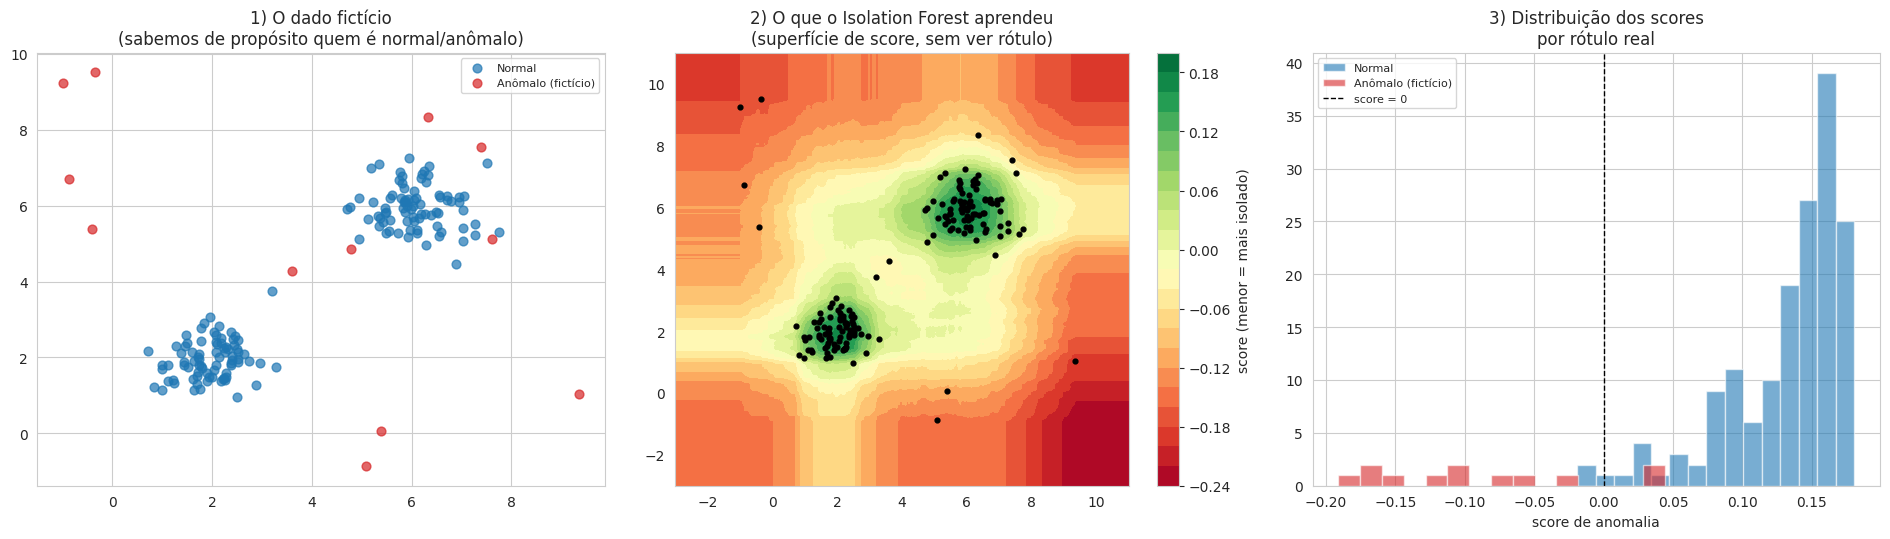

In [284]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

cores_ficticio = {'Normal': 'tab:blue', 'Anômalo (fictício)': 'tab:red'}
for rotulo, cor in cores_ficticio.items():
    m = rotulo_real_ficticio == rotulo
    axes[0].scatter(X_ficticio[m, 0], X_ficticio[m, 1], c=cor, label=rotulo, alpha=0.7, s=40)
axes[0].set_title('1) O dado fictício\n(sabemos de propósito quem é normal/anômalo)')
axes[0].legend(fontsize=8)

# superfície de score: o que o algoritmo "enxerga", sem ver rótulo nenhum
xx, yy = np.meshgrid(np.linspace(-3, 11, 300), np.linspace(-3, 11, 300))
Z = iso_ficticio.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
cs = axes[1].contourf(xx, yy, Z, levels=20, cmap='RdYlGn')
axes[1].scatter(X_ficticio[:, 0], X_ficticio[:, 1], c='black', s=12)
plt.colorbar(cs, ax=axes[1], label='score (menor = mais isolado)')
axes[1].set_title('2) O que o Isolation Forest aprendeu\n(superfície de score, sem ver rótulo)')

# distribuição dos scores por rótulo real
for rotulo, cor in cores_ficticio.items():
    m = rotulo_real_ficticio == rotulo
    axes[2].hist(score_ficticio[m], bins=15, color=cor, alpha=0.6, label=rotulo)
axes[2].axvline(0, color='black', linestyle='--', linewidth=1, label='score = 0')
axes[2].set_title('3) Distribuição dos scores\npor rótulo real')
axes[2].set_xlabel('score de anomalia')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()


A superfície de score (painel 2) fica **verde** (score alto, "normal") bem em cima dos dois grupos densos, e **vermelha** (score baixo, "anômalo") nas bordas e longe de tudo — exatamente onde estão os pontos fictícios que geramos como "anômalos". O algoritmo nunca viu o rótulo `Normal`/`Anômalo (fictício)`: ele chegou nisso só de contar quão rápido cada ponto fica isolado. O histograma (painel 3) mostra a mesma coisa de outro ângulo: os scores dos pontos normais ficam concentrados bem acima de zero; os anômalos, misturados mais pra baixo — a separação não é perfeita (alguns anômalos fictícios caíram por sorte perto dos grupos densos), o que já é um bom aviso pra quando aplicarmos em dado real: o Isolation Forest não é infalível, é uma sugestão de onde olhar com mais atenção.


### Por dentro de uma única árvore

A superfície de score acima é o resultado **já combinado** de 200 árvores. Pra enxergar o mecanismo de verdade — os cortes aleatórios que dão nome ao algoritmo — olhamos uma árvore sozinha: cada linha abaixo é um corte (variável aleatória, ponto de corte aleatório entre o mínimo e o máximo ali). Escolhemos dois pontos de propósito — um bem no meio de um grupo denso, outro o mais "anômalo" segundo o próprio modelo — e comparamos quantos cortes cada um precisou até ficar sozinho numa partição.


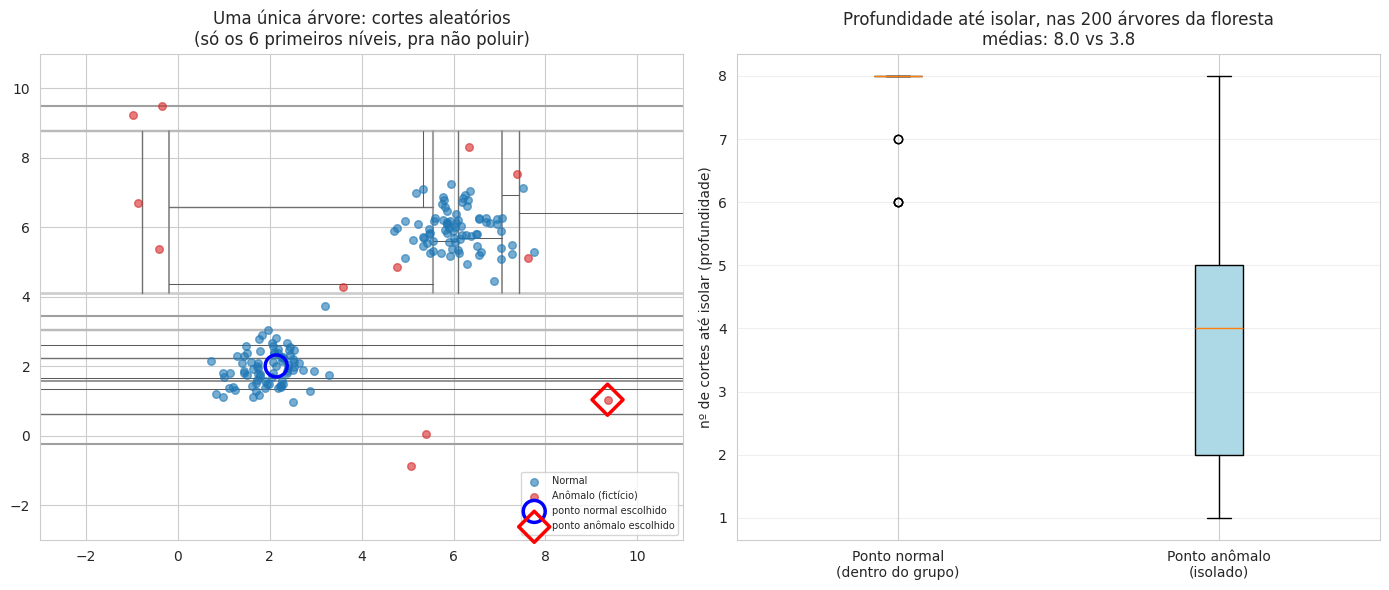

In [285]:
def desenhar_particoes(ax, tree_, no, x_min, x_max, y_min, y_max, profundidade=0, profundidade_max=6):
    """Desenha recursivamente os cortes de uma árvore de isolamento dentro de uma caixa
    [x_min,x_max] x [y_min,y_max]. Só os primeiros `profundidade_max` níveis são desenhados —
    a árvore de verdade continua até isolar cada ponto sozinho, mas isso poluiria demais o
    desenho sem ajudar a entender a ideia."""
    if profundidade >= profundidade_max or tree_.children_left[no] == -1:  # -1 = folha
        return
    variavel, limiar = tree_.feature[no], tree_.threshold[no]
    cor = plt.cm.Greys(0.3 + 0.5 * profundidade / profundidade_max)
    espessura = max(2 - 0.25 * profundidade, 0.4)
    if variavel == 0:
        ax.plot([limiar, limiar], [y_min, y_max], color=cor, linewidth=espessura)
        desenhar_particoes(ax, tree_, tree_.children_left[no], x_min, limiar, y_min, y_max, profundidade + 1, profundidade_max)
        desenhar_particoes(ax, tree_, tree_.children_right[no], limiar, x_max, y_min, y_max, profundidade + 1, profundidade_max)
    else:
        ax.plot([x_min, x_max], [limiar, limiar], color=cor, linewidth=espessura)
        desenhar_particoes(ax, tree_, tree_.children_left[no], x_min, x_max, y_min, limiar, profundidade + 1, profundidade_max)
        desenhar_particoes(ax, tree_, tree_.children_right[no], x_min, x_max, limiar, y_max, profundidade + 1, profundidade_max)


def profundidade_isolamento(tree_, ponto):
    """Quantos cortes uma árvore precisa até isolar `ponto` sozinho numa folha."""
    no, profundidade = 0, 0
    while tree_.children_left[no] != -1:
        variavel, limiar = tree_.feature[no], tree_.threshold[no]
        no = tree_.children_left[no] if ponto[variavel] <= limiar else tree_.children_right[no]
        profundidade += 1
    return profundidade


# dois pontos escolhidos de propósito: o mais "normal" (mais perto do centro do 1º grupo) e o
# mais "anômalo" de verdade segundo o próprio modelo (menor score entre os pontos fictícios)
ponto_normal = X_normal_ficticio[np.argmin(np.linalg.norm(X_normal_ficticio - [2, 2], axis=1))]
scores_dos_anomalos = iso_ficticio.decision_function(X_anomalo_ficticio)
ponto_anomalo = X_anomalo_ficticio[np.argmin(scores_dos_anomalos)]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# painel A: uma única árvore da floresta, cortes desenhados
ax = axes[0]
x_min, x_max, y_min, y_max = -3, 11, -3, 11
uma_arvore = iso_ficticio.estimators_[0].tree_
desenhar_particoes(ax, uma_arvore, 0, x_min, x_max, y_min, y_max)
for rotulo, cor in cores_ficticio.items():
    m = rotulo_real_ficticio == rotulo
    ax.scatter(X_ficticio[m, 0], X_ficticio[m, 1], c=cor, alpha=0.6, s=30, label=rotulo, zorder=3)
ax.scatter(*ponto_normal, s=250, facecolor='none', edgecolor='blue', linewidth=2.5, zorder=4, label='ponto normal escolhido')
ax.scatter(*ponto_anomalo, s=250, facecolor='none', edgecolor='red', linewidth=2.5, marker='D', zorder=4, label='ponto anômalo escolhido')
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_title('Uma única árvore: cortes aleatórios\n(só os 6 primeiros níveis, pra não poluir)')
ax.legend(fontsize=7, loc='lower right')

# painel B: profundidade até isolar cada um dos 2 pontos, em TODAS as árvores da floresta
profundidades_normal = [profundidade_isolamento(arv.tree_, ponto_normal) for arv in iso_ficticio.estimators_]
profundidades_anomalo = [profundidade_isolamento(arv.tree_, ponto_anomalo) for arv in iso_ficticio.estimators_]

ax2 = axes[1]
ax2.boxplot([profundidades_normal, profundidades_anomalo],
            tick_labels=['Ponto normal\n(dentro do grupo)', 'Ponto anômalo\n(isolado)'],
            patch_artist=True, boxprops=dict(facecolor='lightblue'))
ax2.set_ylabel('nº de cortes até isolar (profundidade)')
ax2.set_title(f'Profundidade até isolar, nas {len(iso_ficticio.estimators_)} árvores da floresta\n'
              f'médias: {np.mean(profundidades_normal):.1f} vs {np.mean(profundidades_anomalo):.1f}')
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


No painel A, repare que os cortes se acumulam (linhas mais escuras e grossas, dos primeiros níveis) tentando separar os dois grupos densos um do outro — é preciso *bastante* corte aleatório até isolar alguém que está cercado de vizinhos parecidos. Já nas regiões vazias, um corte já sobra bastante espaço sozinho.

O painel B mostra a consequência disso, com números de verdade: o ponto normal escolhido precisa, em média, de **quase o dobro** de cortes pra ficar isolado, comparado ao ponto anômalo. Repare também que a profundidade **varia bastante de árvore pra árvore** (a caixa do anômalo vai de 1 a 8 cortes) — cada árvore sorteou cortes diferentes, então uma única árvore pode "errar" por sorte. É exatamente por isso que o algoritmo tira a **média de centenas de árvores**, em vez de confiar numa só: no agregado, o padrão (caminho curto = anômalo) se sustenta, mesmo que árvore isolada nenhuma seja confiável sozinha.


---
## Detecção global: quem foge do padrão geral da base?

Reaproveitamos exatamente as mesmas 4 variáveis-driver já padronizadas na Fase 2 (`X`: `IDADE`, `ANOS_ESTUDO`, `Total_Bens_Log`, `Total_Gasto_Campanha_Log`) — mesma pergunta de negócio, agora olhando pra quem está nas bordas em vez de procurar grupos.

Antes de fixar `contamination`, vale ver como o número de candidatos sinalizados muda conforme a suposição:


In [286]:
for cont in [0.02, 0.03, 0.05, 0.08, 'auto']:
    iso_teste = IsolationForest(contamination=cont, random_state=SEMENTE, n_estimators=200)
    pred_teste = iso_teste.fit_predict(X)
    n_atipicos = int((pred_teste == -1).sum())
    print(f"contamination={cont!s:>6}: {n_atipicos:3d} atípicos de {len(X)} ({n_atipicos / len(X):.1%})")


contamination=  0.02:  14 atípicos de 692 (2.0%)
contamination=  0.03:  21 atípicos de 692 (3.0%)
contamination=  0.05:  35 atípicos de 692 (5.1%)
contamination=  0.08:  56 atípicos de 692 (8.1%)
contamination=  auto: 245 atípicos de 692 (35.4%)


O modo `'auto'` do scikit-learn usa uma heurística própria, baseada no artigo original do Isolation Forest, e não representa uma estimativa observada da proporção real de anomalias. Por isso, comparamos explicitamente recortes entre 2% e 8% e fixamos `contamination=0.05`. Na base de 692 candidatos, isso sinaliza cerca de 35 casos: um conjunto pequeno o bastante para inspeção individual, mas sem restringir a análise apenas aos casos mais extremos. A escolha continua sendo uma hipótese de trabalho, e a célula anterior permite avaliar sua sensibilidade.


In [287]:
contamination_global = 0.05  # ajuste conforme a célula anterior, se quiser um recorte maior/menor

iso_global = IsolationForest(contamination=contamination_global, random_state=SEMENTE, n_estimators=200)
pred_global = iso_global.fit_predict(X)
score_global = iso_global.decision_function(X)

df_cluster['anomalia_global'] = np.where(pred_global == -1, 'Atípico', 'Típico')
df_cluster['score_global'] = score_global

# Diagnóstico auxiliar: em qual variável o candidato mais se afasta da média geral?
# O valor é medido em desvios-padrão e serve para interpretar o alerta, não como prova de causalidade.
NOMES_VARIAVEIS = {
    'IDADE': 'idade',
    'ANOS_ESTUDO': 'anos de estudo',
    'Total_Bens_Log': 'patrimônio declarado',
    'Total_Gasto_Campanha_Log': 'despesas de campanha',
}
z_global = pd.DataFrame(
    StandardScaler().fit_transform(df_cluster[colunas_driver]),
    columns=colunas_driver,
    index=df_cluster.index,
)
df_cluster['variavel_mais_atipica_global'] = z_global.abs().idxmax(axis=1).map(NOMES_VARIAVEIS)
df_cluster['desvio_max_global'] = z_global.abs().max(axis=1)

n_atipicos_global = (df_cluster['anomalia_global'] == 'Atípico').sum()
print(f"{n_atipicos_global} candidatos atípicos na base inteira (contamination={contamination_global})")

colunas_ficha_anomalia = [
    'NM_URNA_CANDIDATO', 'SG_UF', 'SG_PARTIDO', 'IDADE', 'ANOS_ESTUDO',
    'Total_Bens', 'Total_Gasto_Campanha', 'cluster'
]


35 candidatos atípicos na base inteira (contamination=0.05)


### Lista de atípicos (visão global)


In [288]:
atipicos_globais = df_cluster[df_cluster['anomalia_global'] == 'Atípico'] \
    .sort_values('score_global')[
        colunas_ficha_anomalia
        + ['variavel_mais_atipica_global', 'desvio_max_global', 'score_global']
    ]

atipicos_globais


,NM_URNA_CANDIDATO,SG_UF,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,Total_Gasto_Campanha,cluster,variavel_mais_atipica_global,desvio_max_global,score_global
668,CHICO SÁ,MS,AVANTE,86,4,"150,000.00","18,105.50","Patrimonializados, escolarizados e com campanha ativa",anos de estudo,3.36,-0.08
328,ADAIR HENRIQUES VOVÔ DO JEEP,GO,PSDB,85,8,"25,041,060.33","250,096.50","Patrimonializados, escolarizados e com campanha ativa",idade,2.91,-0.07
291,BARBARA BOMBOM,GO,PSOL,34,1,0.00,"3,220.00",Campanha ativa sem patrimônio,anos de estudo,4.36,-0.06
72,SILVA FOTOGRAFO - O CORNO,DF,AGIR,65,4,"50,000.00",0.00,Patrimonializados sem despesas declaradas,anos de estudo,3.36,-0.05
512,PASTOR JERONIMO GOMES,MT,PSOL,78,9,0.00,"2,692.00",Campanha ativa sem patrimônio,idade,2.35,-0.05
185,CARLOS MARANHÃO,GO,PT,46,1,0.00,0.00,Jovens com baixa estrutura declarada,anos de estudo,4.36,-0.04
561,LUSIMAR DA CANAÃ,MT,DC,47,1,0.00,0.00,Jovens com baixa estrutura declarada,anos de estudo,4.36,-0.04
162,CARLOS VINÍCIUS,DF,PCO,25,4,0.00,0.00,Jovens com baixa estrutura declarada,anos de estudo,3.36,-0.04
557,VANDA,MT,AGIR,65,4,0.00,0.00,Jovens com baixa estrutura declarada,anos de estudo,3.36,-0.04
413,NEIDE ALVES,GO,DC,61,4,"700,000.00",0.00,Patrimonializados sem despesas declaradas,anos de estudo,3.36,-0.04


### Onde esses candidatos aparecem, visualmente


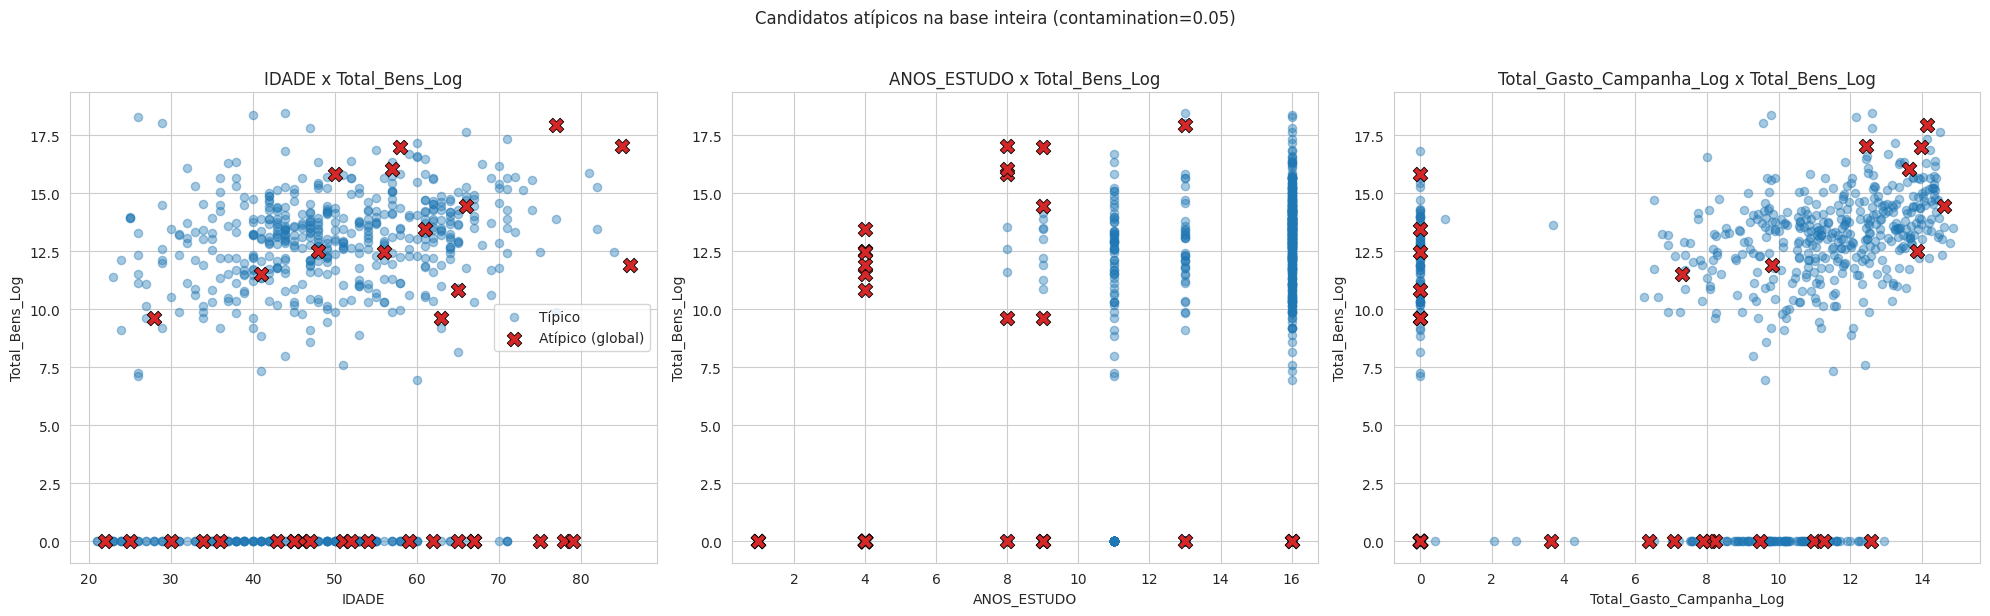

In [289]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

pares = [
    ('IDADE', 'Total_Bens_Log'),
    ('ANOS_ESTUDO', 'Total_Bens_Log'),
    ('Total_Gasto_Campanha_Log', 'Total_Bens_Log'),
]
for ax, (x_col, y_col) in zip(axes, pares):
    tipicos = df_cluster[df_cluster['anomalia_global'] == 'Típico']
    atipicos = df_cluster[df_cluster['anomalia_global'] == 'Atípico']
    ax.scatter(tipicos[x_col], tipicos[y_col], c='tab:blue', alpha=0.4, s=35, label='Típico')
    ax.scatter(atipicos[x_col], atipicos[y_col], c='tab:red', marker='X', s=110,
               edgecolor='black', linewidth=0.6, label='Atípico (global)')
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_title(f'{x_col} x {y_col}')

axes[0].legend()
plt.suptitle(f'Candidatos atípicos na base inteira (contamination={contamination_global})', y=1.02)
plt.tight_layout()
plt.show()


### O mesmo recorte, em 3D

Os painéis acima mostram somente duas variáveis de cada vez. Como o modelo usa **4 variáveis-driver simultaneamente**, não é possível representar todas em um único gráfico 3D. A projeção interativa abaixo preserva os três eixos originais (`IDADE`, `ANOS_ESTUDO` e `Total_Bens_Log`) e informa `Total_Gasto_Campanha_Log` ao passar o mouse. Portanto, a classificação considera as quatro dimensões, embora o gráfico mostre apenas três delas — arrastem pra rotacionar e passem o mouse num ponto pra ver quem é.


In [290]:
cores_iso = {'Típico': '#1f77b4', 'Atípico': '#d62728'}

fig3d = go.Figure()
for status, cor in cores_iso.items():
    sub = df_cluster[df_cluster['anomalia_global'] == status]
    texto_hover = (
        sub['NM_URNA_CANDIDATO'] + ' — ' + sub['cluster']
        + '<br>Total_Gasto_Campanha_Log=' + sub['Total_Gasto_Campanha_Log'].round(2).astype(str)
    )
    fig3d.add_trace(go.Scatter3d(
        x=sub['IDADE'], y=sub['ANOS_ESTUDO'], z=sub['Total_Bens_Log'],
        mode='markers', name=status,
        marker=dict(
            size=6 if status == 'Típico' else 9,
            color=cor,
            symbol='circle' if status == 'Típico' else 'diamond',
            opacity=0.5 if status == 'Típico' else 0.95,
            line=dict(width=1, color='black'),
        ),
        text=texto_hover,
        hovertemplate='<b>%{text}</b><br>IDADE=%{x}<br>ANOS_ESTUDO=%{y}<br>Total_Bens_Log=%{z:.2f}<extra></extra>',
    ))

fig3d.update_layout(
    scene=dict(xaxis_title='IDADE', yaxis_title='ANOS_ESTUDO', zaxis_title='Total_Bens_Log'),
    title=f'Candidatos atípicos (projeção em 3 das 4 variáveis-driver; contamination={contamination_global})',
    height=650, margin=dict(l=0, r=0, b=0, t=40),
)
fig3d.show()


---
## Detecção dentro de cada cluster: quem foge do padrão do próprio grupo?

Aqui está o detalhe metodológico que faz essa pergunta ser **diferente** da anterior, não uma repetição: se reaproveitássemos a mesma escala global (`X`, MinMax ajustado na base inteira) pra rodar o Isolation Forest separadamente por cluster, diferenças internas poderiam ser abafadas pela amplitude da base completa. Pra perguntar "isso é estranho **para este grupo**?", precisamos **padronizar de novo, usando só a média e o desvio-padrão daquele cluster** (`StandardScaler` ajustado cluster a cluster).

Sobre `contamination` por cluster: os cinco clusters têm tamanhos bem diferentes (418 / 111 / 78 / 44 / 41 candidatos). Usamos `max(5%, 2 candidatos)` — um piso de pelo menos 2 candidatos sinalizados mesmo nos grupos menores, sem passar de 50% do grupo. Assim, mantemos uma proporção comparável nos clusters maiores sem deixar os menores sem casos para inspeção. Os resultados dos grupos menores devem ser interpretados com mais cautela, pois cada observação tem peso maior.


In [291]:
resultados_cluster = []

for nome in df_cluster['cluster'].unique():
    sub_idx = df_cluster.index[df_cluster['cluster'] == nome].to_numpy()
    n = len(sub_idx)

    X_cluster = df_cluster.loc[sub_idx, colunas_driver].values
    X_cluster_padronizado = StandardScaler().fit_transform(X_cluster)

    contaminacao_cluster = min(max(0.05, 2 / n), 0.5)
    iso_cluster = IsolationForest(contamination=contaminacao_cluster, random_state=SEMENTE, n_estimators=200)
    pred_cluster = iso_cluster.fit_predict(X_cluster_padronizado)
    score_cluster = iso_cluster.decision_function(X_cluster_padronizado)

    # Variável com o maior afastamento padronizado dentro do próprio cluster.
    maior_desvio_idx = np.abs(X_cluster_padronizado).argmax(axis=1)
    variavel_mais_atipica = [NOMES_VARIAVEIS[colunas_driver[i]] for i in maior_desvio_idx]
    desvio_max_cluster = np.abs(X_cluster_padronizado).max(axis=1)

    n_atipicos = int((pred_cluster == -1).sum())
    print(f"{nome} (n={n}, contamination={contaminacao_cluster:.3f}): {n_atipicos} atípicos dentro do grupo")

    resultados_cluster.append(pd.DataFrame({
        'indice_original': sub_idx,
        'anomalia_cluster': np.where(pred_cluster == -1, 'Atípico', 'Típico'),
        'score_cluster': score_cluster,
        'variavel_mais_atipica_cluster': variavel_mais_atipica,
        'desvio_max_cluster': desvio_max_cluster,
    }))

anomalia_cluster_df = pd.concat(resultados_cluster).set_index('indice_original').sort_index()
for coluna in anomalia_cluster_df.columns:
    df_cluster[coluna] = anomalia_cluster_df[coluna]


Patrimonializados, escolarizados e com campanha ativa (n=418, contamination=0.050): 21 atípicos dentro do grupo
Patrimonializados sem despesas declaradas (n=78, contamination=0.050): 4 atípicos dentro do grupo
Campanha ativa sem patrimônio (n=111, contamination=0.050): 6 atípicos dentro do grupo
Jovens com baixa estrutura declarada (n=44, contamination=0.050): 3 atípicos dentro do grupo
Escolarizados sem bens nem despesas (n=41, contamination=0.050): 2 atípicos dentro do grupo


In [292]:
for nome in df_cluster['cluster'].unique():
    print(f"--- {nome}: mais atípicos dentro do grupo ---")
    sub = df_cluster[(df_cluster['cluster'] == nome) & (df_cluster['anomalia_cluster'] == 'Atípico')]
    display(sub.sort_values('score_cluster')[
        colunas_ficha_anomalia
        + ['variavel_mais_atipica_cluster', 'desvio_max_cluster', 'score_cluster']
    ])


--- Patrimonializados, escolarizados e com campanha ativa: mais atípicos dentro do grupo ---


,NM_URNA_CANDIDATO,SG_UF,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,Total_Gasto_Campanha,cluster,variavel_mais_atipica_cluster,desvio_max_cluster,score_cluster
668,CHICO SÁ,MS,AVANTE,86,4,"150,000.00","18,105.50","Patrimonializados, escolarizados e com campanha ativa",anos de estudo,5.22,-0.15
328,ADAIR HENRIQUES VOVÔ DO JEEP,GO,PSDB,85,8,"25,041,060.33","250,096.50","Patrimonializados, escolarizados e com campanha ativa",anos de estudo,3.32,-0.13
603,ISA MARCONDES,MS,REPUBLICANOS,48,4,"276,528.38","1,045,425.59","Patrimonializados, escolarizados e com campanha ativa",anos de estudo,5.22,-0.11
247,MAGDA MOFATTO,GO,PL,77,13,"62,944,315.40","1,372,194.84","Patrimonializados, escolarizados e com campanha ativa",patrimônio declarado,2.55,-0.06
447,NERI GELLER,MT,PODE,57,8,"9,174,334.90","835,932.74","Patrimonializados, escolarizados e com campanha ativa",anos de estudo,3.32,-0.06
308,DANIEL AGROBOM,GO,PSD,58,9,"24,542,352.43","1,170,955.49","Patrimonializados, escolarizados e com campanha ativa",anos de estudo,2.85,-0.05
19,ADRIANO AMARAL,DF,PSD,29,13,"66,757,749.04","14,104.58","Patrimonializados, escolarizados e com campanha ativa",patrimônio declarado,2.58,-0.05
219,JHONE SANTOS,GO,MISSÃO,33,9,"52,112.00","3,256.87","Patrimonializados, escolarizados e com campanha ativa",anos de estudo,2.85,-0.05
523,JUAREZ COSTA,MT,REPUBLICANOS,66,9,"1,930,512.73","2,254,180.46","Patrimonializados, escolarizados e com campanha ativa",anos de estudo,2.85,-0.05
95,WENDER,DF,PSB,24,13,"9,000.00","25,282.85","Patrimonializados, escolarizados e com campanha ativa",idade,2.26,-0.04


--- Patrimonializados sem despesas declaradas: mais atípicos dentro do grupo ---


,NM_URNA_CANDIDATO,SG_UF,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,Total_Gasto_Campanha,cluster,variavel_mais_atipica_cluster,desvio_max_cluster,score_cluster
198,EDMOTOS,GO,PV,41,4,"100,000.00","1,500.00",Patrimonializados sem despesas declaradas,despesas de campanha,6.18,-0.14
88,EDILSON PARDALS,DF,DC,50,11,"20,000.00","1,400.00",Patrimonializados sem despesas declaradas,despesas de campanha,6.12,-0.12
228,MAYKEL CARVALHO,GO,MISSÃO,43,9,"1,065,000.00",1.00,Patrimonializados sem despesas declaradas,anos de estudo,1.30,-0.03
72,SILVA FOTOGRAFO - O CORNO,DF,AGIR,65,4,"50,000.00",0.00,Patrimonializados sem despesas declaradas,anos de estudo,2.77,-0.00


--- Campanha ativa sem patrimônio: mais atípicos dentro do grupo ---


,NM_URNA_CANDIDATO,SG_UF,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,Total_Gasto_Campanha,cluster,variavel_mais_atipica_cluster,desvio_max_cluster,score_cluster
291,BARBARA BOMBOM,GO,PSOL,34,1,0.00,"3,220.00",Campanha ativa sem patrimônio,anos de estudo,3.52,-0.09
512,PASTOR JERONIMO GOMES,MT,PSOL,78,9,0.00,"2,692.00",Campanha ativa sem patrimônio,idade,2.89,-0.06
39,ESTER CARVALHO,DF,UNIÃO,22,9,0.00,"288,023.00",Campanha ativa sem patrimônio,idade,1.83,-0.04
555,CABO LUÍS ROBERTO,MT,AGIR,34,11,0.00,73.00,Campanha ativa sem patrimônio,despesas de campanha,3.46,-0.03
86,SERRALHEIRO RONO PINHEIRO,DF,DC,51,4,0.00,600.00,Campanha ativa sem patrimônio,anos de estudo,2.63,-0.03
250,PAPACAPIM,GO,MDB,52,4,0.00,"59,005.00",Campanha ativa sem patrimônio,anos de estudo,2.63,-0.01


--- Jovens com baixa estrutura declarada: mais atípicos dentro do grupo ---


,NM_URNA_CANDIDATO,SG_UF,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,Total_Gasto_Campanha,cluster,variavel_mais_atipica_cluster,desvio_max_cluster,score_cluster
118,ALVARO MOZINI,DF,MISSÃO,25,13,0.00,6.82,Jovens com baixa estrutura declarada,despesas de campanha,6.43,-0.06
27,MILENA DO MLB,DF,UP,26,11,"1,404.35",0.00,Jovens com baixa estrutura declarada,patrimônio declarado,4.63,-0.01
26,DURVAL,DF,UP,26,11,"1,224.11",0.00,Jovens com baixa estrutura declarada,patrimônio declarado,4.54,-0.01


--- Escolarizados sem bens nem despesas: mais atípicos dentro do grupo ---


,NM_URNA_CANDIDATO,SG_UF,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,Total_Gasto_Campanha,cluster,variavel_mais_atipica_cluster,desvio_max_cluster,score_cluster
213,ROBERTO GOMES,GO,NOVO,67,16,0.00,37.80,Escolarizados sem bens nem despesas,despesas de campanha,5.07,-0.08
139,PASTOR ISMAEL LOPES,DF,PDT,35,16,0.00,13.57,Escolarizados sem bens nem despesas,despesas de campanha,3.65,-0.05


### O mesmo recorte, em 3D — filtrando por cluster

Mesma ideia do gráfico 3D global, agora um por cluster: escolham no menu qual grupo olhar (cada cluster usa a sua **própria** padronização, então os pontos vermelhos aqui são atípicos *dentro daquele grupo*, não em relação à base inteira). Os eixos ficam fixos entre um cluster e outro, pra dar pra comparar a posição relativa. Como antes, o gasto de campanha participa do modelo e aparece ao passar o mouse, embora a projeção tenha apenas três eixos.


In [293]:
nomes_bisecting_ordenados = list(df_cluster['cluster'].unique())
n_status = len(cores_iso)  # 'Típico' e 'Atípico', mesmas cores do gráfico 3D global

fig3d_cluster = go.Figure()
for idx_cluster, nome in enumerate(nomes_bisecting_ordenados):
    for status, cor in cores_iso.items():
        sub = df_cluster[(df_cluster['cluster'] == nome) & (df_cluster['anomalia_cluster'] == status)]
        texto_hover = (
            sub['NM_URNA_CANDIDATO']
            + '<br>Total_Gasto_Campanha_Log=' + sub['Total_Gasto_Campanha_Log'].round(2).astype(str)
        )
        fig3d_cluster.add_trace(go.Scatter3d(
            x=sub['IDADE'], y=sub['ANOS_ESTUDO'], z=sub['Total_Bens_Log'],
            mode='markers', name=status,
            marker=dict(
                size=6 if status == 'Típico' else 9,
                color=cor,
                symbol='circle' if status == 'Típico' else 'diamond',
                opacity=0.55 if status == 'Típico' else 0.95,
                line=dict(width=1, color='black'),
            ),
            text=texto_hover,
            hovertemplate='<b>%{text}</b><br>IDADE=%{x}<br>ANOS_ESTUDO=%{y}<br>Total_Bens_Log=%{z:.2f}<extra></extra>',
            visible=(idx_cluster == 0),       # só o primeiro cluster começa visível
            legendgroup=status,
            showlegend=(idx_cluster == 0),    # legenda não se repete a cada cluster
        ))

# um botão por cluster no menu suspenso — cada um liga só os 2 traços (Típico/Atípico) daquele cluster
botoes_cluster = []
for idx_cluster, nome in enumerate(nomes_bisecting_ordenados):
    visibilidade = [False] * (len(nomes_bisecting_ordenados) * n_status)
    for j in range(n_status):
        visibilidade[idx_cluster * n_status + j] = True
    botoes_cluster.append(dict(
        label=nome, method='update',
        args=[{'visible': visibilidade}, {'title': f'Atípicos dentro do cluster: {nome}'}],
    ))

fig3d_cluster.update_layout(
    scene=dict(
        xaxis_title='IDADE', yaxis_title='ANOS_ESTUDO', zaxis_title='Total_Bens_Log',
        xaxis=dict(range=[df_cluster['IDADE'].min() - 2, df_cluster['IDADE'].max() + 2]),
        yaxis=dict(range=[df_cluster['ANOS_ESTUDO'].min() - 1, df_cluster['ANOS_ESTUDO'].max() + 1]),
        zaxis=dict(range=[df_cluster['Total_Bens_Log'].min() - 0.5, df_cluster['Total_Bens_Log'].max() + 0.5]),
    ),
    updatemenus=[dict(active=0, buttons=botoes_cluster, x=0.02, y=1.05, xanchor='left')],
    title=f'Atípicos dentro do cluster: {nomes_bisecting_ordenados[0]}',
    height=650, margin=dict(l=0, r=0, b=0, t=60),
)
fig3d_cluster.show()


### Comparando: global vs. dentro do cluster

Quatro combinações possíveis pra cada candidato: atípico nos dois recortes (destoa de tudo, robusto), só globalmente, só dentro do cluster, ou típico nos dois. O caso mais interessante pedagogicamente é o **"só dentro do cluster"**: candidatos que passam despercebidos quando olhamos a base inteira, mas que não se parecem com seus próprios colegas de grupo.


In [294]:
tabela_comparacao = pd.crosstab(df_cluster['anomalia_global'], df_cluster['anomalia_cluster'])
tabela_comparacao.index.name = 'anomalia_global \ anomalia_cluster'
display(tabela_comparacao)

so_no_cluster = df_cluster[(df_cluster['anomalia_global'] == 'Típico') & (df_cluster['anomalia_cluster'] == 'Atípico')]
print(f"\n{len(so_no_cluster)} candidatos são atípicos só DENTRO do próprio cluster (passariam despercebidos na análise global):")
so_no_cluster[
    colunas_ficha_anomalia
    + ['variavel_mais_atipica_cluster', 'desvio_max_cluster', 'score_cluster']
].sort_values('score_cluster')


anomalia_cluster,Atípico,Típico
anomalia_global \ anomalia_cluster,,
Atípico,15,20
Típico,21,636



21 candidatos são atípicos só DENTRO do próprio cluster (passariam despercebidos na análise global):


,NM_URNA_CANDIDATO,SG_UF,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,Total_Gasto_Campanha,cluster,variavel_mais_atipica_cluster,desvio_max_cluster,score_cluster
88,EDILSON PARDALS,DF,DC,50,11,"20,000.00","1,400.00",Patrimonializados sem despesas declaradas,despesas de campanha,6.12,-0.12
118,ALVARO MOZINI,DF,MISSÃO,25,13,0.00,6.82,Jovens com baixa estrutura declarada,despesas de campanha,6.43,-0.06
19,ADRIANO AMARAL,DF,PSD,29,13,"66,757,749.04","14,104.58","Patrimonializados, escolarizados e com campanha ativa",patrimônio declarado,2.58,-0.05
139,PASTOR ISMAEL LOPES,DF,PDT,35,16,0.00,13.57,Escolarizados sem bens nem despesas,despesas de campanha,3.65,-0.05
219,JHONE SANTOS,GO,MISSÃO,33,9,"52,112.00","3,256.87","Patrimonializados, escolarizados e com campanha ativa",anos de estudo,2.85,-0.05
95,WENDER,DF,PSB,24,13,"9,000.00","25,282.85","Patrimonializados, escolarizados e com campanha ativa",idade,2.26,-0.04
237,LUCÉLIA RODRIGUES,GO,PL,30,9,"700,000.00","595,742.00","Patrimonializados, escolarizados e com campanha ativa",anos de estudo,2.85,-0.04
452,ELINEI MACIEL,MT,PSDB,62,8,"110,000.00","12,225.00","Patrimonializados, escolarizados e com campanha ativa",anos de estudo,3.32,-0.04
105,GARCIA LOCUTOR,DF,MOBILIZA,48,8,"301,000.00","3,500.00","Patrimonializados, escolarizados e com campanha ativa",anos de estudo,3.32,-0.03
41,PROF. DÍDIA,DF,UNIÃO,60,16,"1,035.84","15,000.00","Patrimonializados, escolarizados e com campanha ativa",patrimônio declarado,3.42,-0.03


---
## Fechamento

Com esta Fase 4, fecha-se o pipeline completo: preparação de dados (Fase 0), análise descritiva (Fase 1), clusterização — K-Means e Bisecting K-Means (Fase 2), regras de associação (Fase 3) e, agora, detecção de anomalias, tanto na base inteira quanto dentro de cada um dos cinco clusters nomeados na Fase 2.

As colunas `variavel_mais_atipica_global` e `variavel_mais_atipica_cluster` ajudam a interpretar cada alerta: mostram, entre idade, escolaridade, patrimônio e despesas de campanha, qual dimensão apresenta o maior afastamento padronizado no respectivo recorte. Elas não explicam causalidade nem substituem a inspeção da ficha do candidato.

**Exercícios sugeridos:**
- Comparar com `sklearn.neighbors.LocalOutlierFactor` — outro clássico de detecção de anomalias, baseado em densidade local (mais parecido com a lógica do DBSCAN) em vez de isolamento por cortes aleatórios. Os dois concordam nos mesmos candidatos?
- Variar `contamination` (global e por cluster) e ver quão sensível é a lista de atípicos a essa escolha.
- Investigar manualmente 2 ou 3 candidatos da lista "só dentro do cluster" — o que a ficha completa deles (partido, ocupação, bens e despesas declaradas) sugere sobre por que destoam do próprio grupo?
